# **Machine Learning Homework 2026: Repeat Purchase Prediction (Group 44)**
The notebook has four parts: Part 1, exploratory data analysis (sections 1 to 11); Part 2, preprocessing (12 to 21); Part 3, feature selection (22 to 28); Part 4, modelling and submission (29 to 36). It reads `train.csv`, `test.csv`, `clientes.csv` and `sample_submission.csv` from `../data/raw/`, and saves the submission in `../data/processed/`.

## **Part 1. Exploratory Data Analysis**

### **1.Setup**

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

train_path=os.path.join("..","data","raw","train.csv")
clientes_path=os.path.join("..","data","raw","clientes.csv")

df_train= pd.read_csv(train_path,index_col="ID",sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

### **2.Loading Data and First Look**

#### **2.1. Overall First Look**

In [2]:
print(f"Rows:{df_train.shape[0]:,} | Columns:{df_train.shape[1]}")
df_train.head().T

Rows:6,534 | Columns:38


ID,10000000,10000001,10000002,10000003,10000004
Total a Pagar,558.11,978.8,10.33,856.83,1616.1
Total Bruto,510.9,830.02,12.0,696.61,1488.85
Total Liquido,453.75,795.77,8.4,696.61,1313.9
Total Imp_,104.36,183.03,1.93,160.22,302.2
Total Portes,0.0,0.0,0.0,0.0,0.0
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,57.15,34.25,3.6,0.0,174.95
Custo,153.099911,472.943134,6.097485,408.167275,485.401864
N_ Detalhes,4.0,32.0,1.0,9.0,33.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,1.0


In [3]:
#df_train.info() shows the type of each column
df_train.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

Purchase Date as String is a problem

#### **2.2 Grouping the Variables**

To better organize our data we chose to group the variables by themes:

In [4]:
#Variables with special structural roles
target_col = "repeat_purchase_90d"
group_col = "customer_id"
index_col = "ID"

# Grouping by themes
var_groups = {
    "Identifier": [
        "ID",
        "customer_id"
    ],
    "Target": [
        "repeat_purchase_90d"
    ],
    "Current transaction (financial)": [
        "Total a Pagar",
        "Total Bruto",
        "Total Liquido",
        "Total Imp_",
        "Total Portes",
        "Total Desc_ Global",
        "Total Desc_ Linha",
        "Custo"
    ],
    "Current transaction (operational)": [
        "N_ Detalhes",
        "invoice_count_current_purchase"
    ],
    "Transaction context & date": [
        "purchase_date",
        "payment_type",
        "salesperson",
        "commercial_zone",
        "warehouse",
        "document_series",
        "transport_method"
    ],
    "Customer historical summary": [
        "customer_tenure_days",
        "prior_purchase_count",
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_std_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value"
    ],
    "Customer cadence & gaps": [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "prior_std_gap_days"
    ],
    "Rolling windows (RFM)": [
        "purchase_count_30d",
        "spend_30d",
        "purchase_count_90d",
        "spend_90d",
        "purchase_count_180d",
        "spend_180d",
        "purchase_count_365d",
        "spend_365d"
    ],
    "Synthetic / Control": [
        "random_noise"
    ]
}
pd.DataFrame(
    [(group, len(cols), ", ".join(cols)) for group, cols in var_groups.items()], columns=["Group", "# vars", "Variables"])

,Group,# vars,Variables
0,Identifier,2,"ID, customer_id"
1,Target,1,repeat_purchase_90d
2,Current transaction (financial),8,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
3,Current transaction (operational),2,"N_ Detalhes, invoice_count_current_purchase"
4,Transaction context & date,7,"purchase_date, payment_type, salesperson, comm..."
5,Customer historical summary,7,"customer_tenure_days, prior_purchase_count, pr..."
6,Customer cadence & gaps,3,"days_since_previous_purchase, prior_mean_gap_d..."
7,Rolling windows (RFM),8,"purchase_count_30d, spend_30d, purchase_count_..."
8,Synthetic / Control,1,random_noise


#### **2.3.The Target and the Floor**

In [5]:
balance = df_train[target_col].value_counts().sort_index() #counting the number of 0 and 1 of the target column
print(balance.to_frame("rows").assign(share=lambda f: (f["rows"] / f["rows"].sum()).round(3)).to_string())

# The  floor: always predict 1 (F1 of class 1).
p = df_train[target_col].mean()
print(f"\nalways predict 1 -> accuracy {p:.3f} | F1(class 1) {2 * p / (1 + p):.3f}")

                     rows  share
repeat_purchase_90d             
0                    2880  0.441
1                    3654  0.559

always predict 1 -> accuracy 0.559 | F1(class 1) 0.717


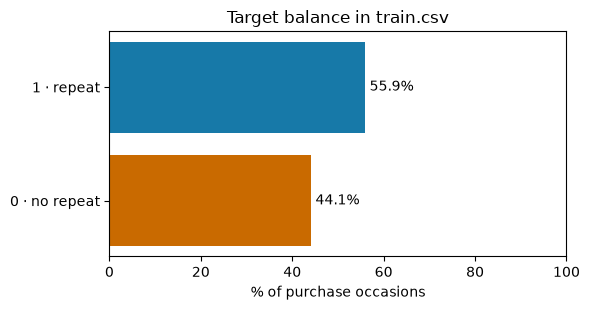

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.2))
shares = df_train[target_col].value_counts(normalize=True).sort_index() * 100
ax.barh(["0 · no repeat", "1 · repeat"], shares.values, color=["#C96A00", "#1779A8"])
for i, v in enumerate(shares.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set(xlim=(0, 100), xlabel="% of purchase occasions", title="Target balance in train.csv")
plt.tight_layout()
plt.show()

**What this tells us**

* The classes are **almost balanced (class 1≈56%/class 0≈44%)** .
* Two consequences for later: (1) every F1 we report will be compared with the all-ones floor, and
  (2) the decision **threshold** is part of the model. The default 0.5 is not necessarily the one that maximises F1.

###  **3. Data Quality Assessment**

  Before changing anything, we first diagnose the problems.

#### **3.1. Rows with no information**

Before looking at each column, we look at each row, to see how much information each row gives us.

In [7]:
row_missing_percentage = pd.DataFrame({
    'customer_id': df_train['customer_id'],
    'n_missing': df_train.isna().sum(axis=1),
    'pct_missing': (df_train.isna().sum(axis=1) * 100) / df_train.shape[1]})

row_missing_percentage = (
    row_missing_percentage
    .set_index("customer_id")
    .query("n_missing > 19")
    .sort_values("n_missing", ascending=False))

print(f"There are {row_missing_percentage.shape[0]} rows with more than 50% of missing values")
row_missing_percentage

There are 65 rows with more than 50% of missing values


,n_missing,pct_missing
customer_id,,
755628,36,94.736842
755628,36,94.736842
427118,36,94.736842
508217,36,94.736842
427118,36,94.736842
...,...,...
151492,36,94.736842
230585,36,94.736842
902830,36,94.736842


In [8]:
# rows where everything is missing except customer_id and the target
empty_rows = df_train.drop(columns=["customer_id", "repeat_purchase_90d"]).isna().all(axis=1)
print(f"Empty rows: {empty_rows.sum()}")

# df is our working copy without the empty rows (df_train stays untouched)
df = df_train.loc[~empty_rows]
print(f"Rows in df: {df.shape[0]:,}")

Empty rows: 65
Rows in df: 6,469


There are 65 rows completely empty (the ones we identified before), having only `customer_id` and the target. We **consider them disposable because they do not give us any information**, so from now on we analyse `df`, which is `df_train` without these 65 rows.

#### **3.2. Duplicates**

In [9]:
n_dup_rows=df_train.duplicated().sum()  #rows that are 100% identical in the raw file
print(f"Fully duplicated rows (raw file): {n_dup_rows}")
print(f"Fully duplicated rows (without the empty rows): {df.duplicated().sum()}")

n_dup_ids=df["customer_id"].duplicated().sum() #repeated client IDs
n_client_ids= df["customer_id"].nunique()
print(f"Duplicated client_id  : {n_dup_ids}")
print(f"Number of clients : {n_client_ids}")
print(f"Number of receipts/clients: {(len(df)/n_client_ids):.2f}")

Fully duplicated rows (raw file): 10
Fully duplicated rows (without the empty rows): 0
Duplicated client_id  : 5862
Number of clients : 607
Number of receipts/clients: 10.66


In the raw file there are 10 fully duplicated rows, but they are all empty rows: two empty rows of the same client look the same. Without the empty rows there are **no duplicated purchases**.

The repeated `customer_id` is not a problem: there are 6,469 purchases from 607 clients, about 10.7 purchases per client. This means the rows of the same client are not independent, which we have to keep in mind when we split the data for validation.

#### **3.3. Missing Values**

In [10]:
missing_values=(df.isna().sum().to_frame("n_missing").assign(percentage=lambda x: (x["n_missing"]*100/len(df))).query("n_missing>0").sort_values("percentage", ascending=False))
missing_values

,n_missing,percentage
prior_std_gap_days,1413,21.842634
prior_mean_gap_days,1243,19.214716
prior_std_purchase_value,1048,16.200340
prior_mean_purchase_value,797,12.320297
days_since_previous_purchase,796,12.304838
prior_min_purchase_value,603,9.321379
prior_max_purchase_value,603,9.321379
transport_method,196,3.029835
spend_365d,195,3.014376
payment_type,195,3.014376


We have 12 columns with at least 190 missing values. Some of the missing values may be explained by the lack of history.Lets look at the column prior_pucharse_count and see how many missing values per clients with: no history (prior_pucharse_count=0), 1 prior purchase, 2 prior purchases and 3+ prior purchases.

In [11]:
# Hypothesis: history columns are missing because the customer has (almost) no history.
history_missing = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
                   "prior_min_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
prior_n = df["prior_purchase_count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
table = (df[history_missing].isna()
         .groupby(prior_n).mean().mul(100).round(1)
         .assign(rows=prior_n.value_counts()))
table.index.name = "prior purchases"
table

,days_since_previous_purchase,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_mean_gap_days,prior_std_gap_days,rows
prior purchases,,,,,,,
0,100.0,100.0,100.0,100.0,100.0,100.0,603
1,4.3,4.5,100.0,0.0,100.0,100.0,445
2,5.5,3.0,0.0,0.0,5.8,100.0,365
3+,3.0,3.2,0.0,0.0,3.4,0.0,5056


The hypothesis holds **only in part**:

* With **0 prior purchases**, every history column is missing in 100% of rows, as expected: there is no history.
* With **1 prior purchase**, the gap and the standard deviations are always missing (one purchase has no gap and no
  spread), but `days_since_previous_purchase` should exist, and it is still missing for a fraction of rows.
* With **2 or more** prior purchases, all these columns *should* exist, yet a few percent are missing anyway. That
  part is ordinary missingness, not structural.

So "missing = no history" (the business-logic reading, MNAR) explains most but not all of it. This decides the fix: we
add an explicit flag such as `is_first_purchase` (`prior_purchase_count == 0`) and *missing indicators*, then impute
the remaining gaps with the **training median**. We do **not** fill gaps with 0: a gap of 0 days would mean "buys every
day", which is the opposite of "no history".

Without the empty rows, the invoice columns, `commercial_zone`, `document_series`, `purchase_date` and the rolling windows have **no missing values**, except `spend_365d` (195 missing values). The real missing values are only in the history columns, in `spend_365d` and in some context columns (about 3% each).

Some history columns have around 20% of missing values, but we do **not** drop them: the missing values are mostly structural (clients without previous purchases), and these columns are among the most important ones for the target (for example `prior_mean_gap_days`). Dropping them would lose a lot of information.

#### **3.4. Inconsistent Categories**

Lets verify if there are any categorical values with inconsistent values. Incosistent values would make the model consider values with the same meaning different due to typography errors.

In [12]:
cat_cols = df.select_dtypes(include=['object', 'category', 'str']).columns.tolist() #columns with categorical values
cat_cols.remove("purchase_date")  # it is a date, not a category
for col in cat_cols:
    print(f"{col:<10} -> {df[col].nunique()} distinct values")

payment_type -> 9 distinct values
salesperson -> 9 distinct values
commercial_zone -> 5 distinct values
transport_method -> 80 distinct values
warehouse  -> 2 distinct values
document_series -> 3 distinct values


Each category is always written in the same way, so there are no spelling variants to fix. The real problem is the **rare levels**: some levels appear only a few times (for example `commercial_zone` 6 and 7 with 1 row each, and many `transport_method` levels with only 1 row). Lets look at each column.

In [13]:
df["payment_type"].value_counts(dropna=False)

payment_type
Maybe Tomorrow Payment 7     4565
Maybe Tomorrow Payment 12     991
Maybe Tomorrow Payment 9      502
NaN                           195
Maybe Tomorrow Payment 10     134
Maybe Tomorrow Payment 8       40
Maybe Tomorrow Payment 2       21
Maybe Tomorrow Payment 4        9
Maybe Tomorrow Payment 11       8
Maybe Tomorrow Payment 3        4
Name: count, dtype: int64

Payment Type has 195 Missing values and no inconsistencies. Values with <10 counts may be considered rare values.

In [14]:
df[("salesperson")].value_counts(dropna=False)

salesperson
VLOOKUP Master 1    4054
VLOOKUP Master 4    1461
VLOOKUP Master 9     384
VLOOKUP Master 7     201
NaN                  194
VLOOKUP Master 2     123
VLOOKUP Master 3      30
VLOOKUP Master 6      12
VLOOKUP Master 5       7
VLOOKUP Master 8       3
Name: count, dtype: int64

Salesperson only has missing values.Values with <10 counts may be considered rare values.

In [15]:
df[("commercial_zone")].value_counts(dropna=False)

commercial_zone
Decorative Dashboard Zone 4    6260
Decorative Dashboard Zone 2     151
Decorative Dashboard Zone 3      56
Decorative Dashboard Zone 6       1
Decorative Dashboard Zone 7       1
Name: count, dtype: int64

This category is fine and has no missing values once the empty rows are removed. Zones 6 and 7 only have 1 row each, so they are rare levels.

In [16]:
print(f"There are {df['transport_method'].isna().sum()} NaNs in this category")
df["transport_method"].value_counts(dropna=False)

There are 196 NaNs in this category


transport_method
Maybe Tomorrow Delivery 72    1119
Maybe Tomorrow Delivery 61     627
Maybe Tomorrow Delivery 73     445
Maybe Tomorrow Delivery 59     373
Maybe Tomorrow Delivery 80     319
                              ... 
Maybe Tomorrow Delivery 55       1
Maybe Tomorrow Delivery 58       1
Maybe Tomorrow Delivery 28       1
Maybe Tomorrow Delivery 21       1
Maybe Tomorrow Delivery 23       1
Name: count, Length: 81, dtype: int64

This category has 196 missing values and values with one observation, so they will be considered rare values.

In [17]:
df[("warehouse")].value_counts(dropna=False)

warehouse
Final Excel Warehouse 1    6253
NaN                         195
Final Excel Warehouse 3      21
Name: count, dtype: int64

Excluding the missing values, this column is fine.

In [18]:
df[("document_series")].value_counts(dropna=False)

document_series
Ctrl Z Series 2    2738
Ctrl Z Series 3    1903
Ctrl Z Series 1    1828
Name: count, dtype: int64

#### **3.5. Wrong Data Types**

#### **3.5.1. Dates**

In [19]:
# Date columns: check which formats are used by replacing every digit with "9"
patterns = df["purchase_date"].astype(str).str.replace(r"\d", "9", regex=True).value_counts()
print(f"{'date format':<18}", patterns.to_dict())
print(f"{'missing values':<18}", df["purchase_date"].isna().sum())

date format        {'9999-99-99': 6469}
missing values     0


The dates are all in the format 9999-99-99, and there are no missing dates once the empty rows are removed.

#### **3.6. Impossible Values**

Lets analyse if there are impossible values "hidden" within the data.

In [20]:
cols_num = df.select_dtypes(include=["number"]).columns.tolist()
df[cols_num].describe().T[["min","25%","50%","75%","max"]].round(2)

,min,25%,50%,75%,max
Total a Pagar,0.93,188.92,476.74,1087.67,2.229721e+04
Total Bruto,0.83,175.74,445.74,1036.70,2.157828e+04
Total Liquido,0.76,154.38,389.91,903.37,1.812781e+04
Total Imp_,0.00,29.93,79.74,184.84,4.169400e+03
Total Portes,0.00,0.00,0.00,0.00,1.810600e+02
Total Desc_ Global,0.00,0.00,0.00,0.00,2.184900e+02
Total Desc_ Linha,0.00,0.00,13.13,92.28,4.103440e+03
Custo,0.00,49.05,152.54,396.06,7.427400e+03
N_ Detalhes,1.00,4.00,11.00,29.00,4.230000e+02
invoice_count_current_purchase,1.00,1.00,1.00,1.00,5.000000e+00


Two things cannot be true:

* `prior_mean_purchase_value` and `spend_365d` reach **1,000,000,000** (one billion euros), while their medians are
  ≈725 € and ≈2,400 €.
* `days_since_previous_purchase` and `prior_mean_gap_days` have **negative** values (a gap cannot be negative), and
  `prior_mean_purchase_value` and `spend_365d` too (spending cannot be negative).

Random damage would scatter over many values. Placeholders sit on a few exact values, so we look at the values themselves.

In [21]:
checks = {
    "prior_mean_purchase_value": df["prior_mean_purchase_value"],
    "spend_365d": df["spend_365d"],
    "days_since_previous_purchase": df["days_since_previous_purchase"],
    "prior_mean_gap_days": df["prior_mean_gap_days"],
}
for name, s in checks.items():
    bad = s[(s < 0) | (s >= 1e8)]
    print(f"{name:30s} {len(bad):3d} impossible values -> {bad.value_counts().head(4).to_dict()}")

prior_mean_purchase_value       32 impossible values -> {1000000000.0: 16, -110.14709677419351: 1, -409.7916666666667: 1, -218.2663917525773: 1}
spend_365d                      30 impossible values -> {1000000000.0: 15, -3456.32: 1, -1230.72: 1, -167.18: 1}
days_since_previous_purchase    16 impossible values -> {-4.0: 16}
prior_mean_gap_days             16 impossible values -> {-4.0: 16}


We have observed that the values 1e9 and -4 are exact repeated values, so they look like codes and not real values. They are impossible values considering the financial context. Before deciding what to do, we check if the real value can be recovered from other columns.

##### **3.6.1. Impossible Values of `prior_mean_purchase_value`**

Lets examine the negative values of `prior_mean_purchase_value`:

In [22]:
df[df["prior_mean_purchase_value"]<0].T

ID,10000018,10000519,10000536,10001157,10001375,10001461,10002281,10002605,10002989,10003383,10003794,10003949,10005413,10006099,10006217,10006219
Total a Pagar,2460.0,221.74,4.65,473.82,423.46,105.29,43.01,2923.88,377.3,93.81,491.61,56.79,502.17,27.8,144.13,592.97
Total Bruto,2000.0,180.28,5.4,447.0,646.53,122.28,49.95,2587.5,409.0,88.5,399.68,54.52,472.96,22.6,117.18,791.45
Total Liquido,2000.0,180.28,3.78,447.0,344.28,85.6,34.97,2587.5,306.75,88.5,399.68,46.17,408.27,22.6,117.18,482.09
Total Imp_,460.0,41.46,0.87,26.82,79.18,19.69,8.04,336.38,70.55,5.31,91.93,10.62,93.9,5.2,26.95,110.88
Total Portes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.1,3.1,5.6,0.0,0.0,4.2
Total Desc_ Global,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Total Desc_ Linha,0.0,0.0,1.62,0.0,302.25,36.68,14.98,0.0,102.25,0.0,0.0,8.35,64.69,0.0,0.0,309.36
Custo,0.0,140.628,2.97,289.5,149.968648,61.08,16.29,0.0,123.74,57.9,227.21,3.56634,150.857,17.78,57.811668,189.475636
N_ Detalhes,1.0,6.0,1.0,58.0,30.0,3.0,1.0,1.0,3.0,8.0,14.0,3.0,10.0,2.0,7.0,44.0
invoice_count_current_purchase,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


We have noticed that the prior mean purchase value may be recomputed through the total spend and the purchase count. Lets confirm this theory:

In [23]:
recomputed_mean = df["prior_total_spend"] / df["prior_purchase_count"].replace(0, np.nan)
stored_mean = df["prior_mean_purchase_value"]

is_billion = stored_mean >= 1e8
is_negative = stored_mean < 0
is_normal = stored_mean.notna() & ~is_billion & ~is_negative
pd.DataFrame({
    "prior_total_spend": df.loc[is_negative, "prior_total_spend"],
    "prior_purchase_count": df.loc[is_negative, "prior_purchase_count"],
    "total / count": recomputed_mean[is_negative],
    "stored prior_mean_purchase_value": stored_mean[is_negative],
}).head(5).round(2)

,prior_total_spend,prior_purchase_count,total / count,stored prior_mean_purchase_value
ID,,,,
10000018,3414.56,31.0,110.15,-110.15
10000519,2458.75,6.0,409.79,-409.79
10000536,42343.68,194.0,218.27,-218.27
10001157,2925.42,7.0,417.92,-417.92
10001375,3895.15,5.0,779.03,-779.03


**The 16 negative values are a sign error**: in every one of them, the stored value is exactly
  `−(prior_total_spend / prior_purchase_count)`. There is no business logic behind a negative mean.

In [24]:
pd.DataFrame({
    "rows": [is_normal.sum(), is_negative.sum(), is_billion.sum()],
    "stored = total / count": [np.isclose(stored_mean[m], recomputed_mean[m]).mean()
                               for m in (is_normal, is_negative, is_billion)],
    "|stored| = total / count": [np.isclose(stored_mean[m].abs(), recomputed_mean[m]).mean()
                                 for m in (is_normal, is_negative, is_billion)],
    "total / count can be computed": [recomputed_mean[m].notna().mean()
                                      for m in (is_normal, is_negative, is_billion)],
}, index=["normal values", "negative values", "1e9 values"]).round(3)

,rows,stored = total / count,|stored| = total / count,total / count can be computed
normal values,5640,0.992,0.992,1.0
negative values,16,0.000,1.000,1.0
1e9 values,16,0.000,0.000,1.0


**The formula holds**: for 99.2% of the normal rows, the stored mean is exactly total / count.

**The 16 values of 1e9 can be recovered as well**: all these customers have previous purchases, so total / count can
  be computed for every one of them.

##### **3.6.2. And the negative values of `spend_365d`?**

There is no general formula to recompute `spend_365d` from other columns, but it must respect two bounds: it includes the last 180 days, so
it is at least `spend_180d`, and it is part of the whole history, so it is at most `prior_total_spend`. We check
whether the negative values fit these bounds once the sign is removed.

In [25]:
spend = df["spend_365d"]
spend_negative = spend < 0
spend_billion = spend >= 1e8
spend_normal = spend.notna() & ~spend_negative & ~spend_billion


def inside_bounds(values, rows):
    """True where a 365-day spend lies between the 180-day spend and the full prior spend (1 cent tolerance)."""
    return ((values >= df.loc[rows, "spend_180d"] - 0.01)
            & (values <= df.loc[rows, "prior_total_spend"] + 0.01))


pd.DataFrame({
    "rows": [spend_normal.sum(), spend_negative.sum()],
    "value inside the bounds": [inside_bounds(spend[spend_normal], spend_normal).mean(),
                                inside_bounds(spend[spend_negative], spend_negative).mean()],
    "|value| inside the bounds": [inside_bounds(spend[spend_normal].abs(), spend_normal).mean(),
                                  inside_bounds(spend[spend_negative].abs(), spend_negative).mean()],
}, index=["normal spend_365d", "negative spend_365d"]).round(3)

,rows,value inside the bounds,|value| inside the bounds
normal spend_365d,6244,0.994,0.994
negative spend_365d,15,0.000,0.933


In [26]:
# The negative value that does not fit the bounds even without its sign
outside = spend_negative & ~inside_bounds(spend.abs(), df.index)
df.loc[outside, ["spend_180d", "spend_365d", "prior_total_spend"]]

,spend_180d,spend_365d,prior_total_spend
ID,,,
10004848,5631.64,-159115.175535,49328.65


* **14 of the 15 negative values fit the bounds once the sign is removed**, so a sign error is possible (99.4% of the normal values respect the same bounds).
* **One value cannot be explained**: −159,115 € in absolute value is three times the customer's whole prior spend
  (49,329 €). No correction is defensible, so it is treated as unknown.
* The 15 values of **1e9** in `spend_365d` cannot be reconstructed from other columns either (only in a few special cases, see 3.6.7).

But is fitting the bounds enough to trust the sign correction? We check how often a random `spend_365d` value would also fit the bounds of these rows.

In [27]:
# for each of the 14 rows, how many normal spend_365d values (taken at random) would also fit its bounds?
pool = spend[spend_normal]
fits = spend_negative & inside_bounds(spend.abs(), df.index)
chance = []
for row in df.index[fits]:
    low, high = df.loc[row, "spend_180d"], df.loc[row, "prior_total_spend"]
    chance.append(((pool >= low - 0.01) & (pool <= high + 0.01)).mean())
print(f"On average {np.mean(chance):.0%} of random values would also fit the bounds")

On average 45% of random values would also fit the bounds


About 45% of random values would also fit, because the bounds are wide. So the bounds do not prove that only the sign is wrong: the whole value could be a recording error. This is different from `prior_mean_purchase_value`, where the value is exactly equal to total / count, which a random value would almost never be.

So we do **not** just remove the minus sign: the 15 negative values of `spend_365d` will be treated as missing (NaN). The ones that can not be recovered (3.6.7) are imputed with the median in Part 2. The median has to be computed only on the training rows, inside the pipeline, to avoid leakage, and we use the median and not the mean because the column is very skewed. This affects the 15 negative values (69 values of `spend_365d` in total become missing, see 3.6.3).

##### **3.6.3. Values that look normal but are not**

The bounds above can also be checked on the "normal" values. A mean purchase value cannot be bigger than the biggest purchase of the client, and the spend of the last 365 days cannot be bigger than the whole prior spend.

In [28]:
# mean bigger than the max purchase of the client
mean_too_high = is_normal & (stored_mean > df["prior_max_purchase_value"] + 0.01)
print(f"prior_mean_purchase_value bigger than prior_max_purchase_value: {mean_too_high.sum()}")
print(f"normal values that do not match total / count: {(is_normal & ~np.isclose(stored_mean, recomputed_mean)).sum()}")

# spend of the last 365 days bigger than the whole prior spend
spend_too_high = spend_normal & (spend > df["prior_total_spend"] + 0.01)
print(f"spend_365d bigger than prior_total_spend: {spend_too_high.sum()}")

# missing means that can be computed with total / count
print(f"prior_mean_purchase_value missing but computable: {(stored_mean.isna() & recomputed_mean.notna()).sum()}")

prior_mean_purchase_value bigger than prior_max_purchase_value: 45
normal values that do not match total / count: 46
spend_365d bigger than prior_total_spend: 39
prior_mean_purchase_value missing but computable: 194


* 46 "normal" means do not match total / count, and in 45 of them the mean is bigger than the biggest purchase of the client, which is impossible. These values look fine alone, so `describe()` could not show them. Since total / count always works, we can recompute `prior_mean_purchase_value` for every row.
* 39 values of `spend_365d` are bigger than the whole prior spend of the client, also impossible. There is no general formula to recover them, so they will be treated as missing (some can still be computed in special cases, see 3.6.7).
* 194 missing values of `prior_mean_purchase_value` can be computed with total / count, so they are not really missing.

##### **3.6.4. Are both negatives on the same rows?**

We test the hypothesis that `prior_mean_purchase_value` and `spend_365d` are negative in the same rows. If this is true, the minus sign is probably a typing error that affects the whole row, and removing it would be easier to defend. If not, we keep the decision we took before.

In [29]:
# rows where each column is negative, and rows where both are negative
neg_mean = df["prior_mean_purchase_value"] < 0
neg_spend = df["spend_365d"] < 0
print(f"Rows with negative prior_mean_purchase_value: {neg_mean.sum()}")
print(f"Rows with negative spend_365d: {neg_spend.sum()}")
print(f"Rows with both negative: {(neg_mean & neg_spend).sum()}")

df.loc[neg_mean | neg_spend, ["customer_id", "prior_mean_purchase_value", "spend_365d", "prior_total_spend", "prior_purchase_count"]]

Rows with negative prior_mean_purchase_value: 16
Rows with negative spend_365d: 15
Rows with both negative: 0


,customer_id,prior_mean_purchase_value,spend_365d,prior_total_spend,prior_purchase_count
ID,,,,,
10000018,239651,-110.147097,1019.820000,3414.56,31.0
10000300,928271,691.264000,-3456.320000,3456.32,5.0
10000519,933227,-409.791667,NaN,2458.75,6.0
10000536,103940,-218.266392,13067.220000,42343.68,194.0
10001157,568558,-417.917143,567.230000,2925.42,7.0
10001375,215423,-779.030000,3261.060000,3895.15,5.0
10001461,103940,-212.360622,14030.610000,44383.37,209.0
10002022,449027,732.742857,-1230.720000,5129.20,7.0
10002033,981754,172.458667,-167.180000,2586.88,15.0


The two columns are never negative in the same row. So the negative values are not an error of the whole row, and we keep the decision we took before: `prior_mean_purchase_value` is recomputed as total / count, and the negative values of `spend_365d` are treated as missing.

##### **3.6.5. Are the invoices consistent?**

The invoice columns are linked by accounting rules: the net value is the gross value minus the discounts, and the amount to pay is the net value plus the tax. If a row breaks these rules, one of its values is wrong. Lets check them.

In [30]:
# the accounting rules of the invoice (2 cents of tolerance for the rounding)
net_rule = np.isclose(df["Total Liquido"], df["Total Bruto"] - df["Total Desc_ Linha"] - df["Total Desc_ Global"], atol=0.02)
pay_rule = np.isclose(df["Total a Pagar"], df["Total Liquido"] + df["Total Imp_"], atol=0.02)
print(f"Total Liquido = Total Bruto - discounts:    {net_rule.mean():.1%} of the rows")
print(f"Total a Pagar = Total Liquido + Total Imp_: {pay_rule.mean():.1%} of the rows")

Total Liquido = Total Bruto - discounts:    100.0% of the rows
Total a Pagar = Total Liquido + Total Imp_: 100.0% of the rows


The two rules hold in 100% of the rows, so the invoice columns have no errors to correct. It also means that these columns are built from each other, which we will see again in the redundancy analysis (section 8).

##### **3.6.6. Is the biggest purchase possible?**

In 3.6.3 we compared the mean with the biggest purchase of the client, but the biggest purchase also has a limit. A client with `count` prior purchases made `count − 1` purchases besides the biggest one, and each of them is at least the minimum. So the biggest one is at most `prior_total_spend − (count − 1) × prior_min_purchase_value`.

In [31]:
count = df["prior_purchase_count"]
max_value = df["prior_max_purchase_value"]
max_limit = df["prior_total_spend"] - (count - 1) * df["prior_min_purchase_value"]
max_too_high = (count >= 1) & (max_value > max_limit + 0.01)

print(f"prior_max_purchase_value above its limit: {max_too_high.sum()}")
print(f"  of which bigger than the whole prior spend: {(max_too_high & (max_value > df['prior_total_spend'] + 0.01)).sum()}")
df.loc[max_too_high, ["prior_purchase_count", "prior_total_spend", "prior_min_purchase_value", "prior_max_purchase_value"]].head()

prior_max_purchase_value above its limit: 46
  of which bigger than the whole prior spend: 45


,prior_purchase_count,prior_total_spend,prior_min_purchase_value,prior_max_purchase_value
ID,,,,
10000300,5.0,3456.32,87.48,22844.431540
10000853,25.0,40285.74,162.61,55316.611919
10001102,9.0,16658.36,56.33,55269.483555
10001129,5.0,2494.49,294.46,21941.361234
10001474,21.0,15632.63,17.80,25095.641836


46 values are above this limit, and 45 of them are even bigger than the whole prior spend of the client: a client with 5 purchases and 3,456 € of total spend can not have one purchase of 22,844 €. Like the inflated means of 3.6.3, these values look normal alone, so `describe()` could not show them. They are impossible, so they will be treated as missing.

##### **3.6.7. Values that can be recovered**

In 3.6.1 the mean could be computed again as total / count. Some other columns are also built from each other, so a missing (or wrong) value is not always unknown:
* With 1 prior purchase, the previous purchase is also the first one, so `days_since_previous_purchase` is the tenure of the client.
* The tenure is the days since the previous purchase plus all the gaps between the purchases, so `days_since = tenure − gap × (count − 1)`, and the other way round for the gap.
* `spend_365d` is 0 if there was no purchase in the last 365 days, it is equal to `spend_180d` if there was no purchase between 180 and 365 days ago, and it is equal to `prior_total_spend` if all the prior purchases are in the last 365 days.
* With 1 prior purchase the biggest purchase is the total, and with 2 it is the total minus the minimum.

A rule is only useful if it always holds. So we first set the impossible values of 3.6 to missing, then we check each rule on the rows where we know both sides, and we count how many missing cells it can fill.

In [32]:
# a copy with the impossible values of 3.6 set to missing (the mean is already covered in 3.6.1)
clean = df.copy()
bad_spend = (clean["spend_365d"] < 0) | (clean["spend_365d"] >= 1e8) | (clean["spend_365d"] > clean["prior_total_spend"] + 0.01)
clean.loc[bad_spend, "spend_365d"] = np.nan
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    clean.loc[clean[col] < 0, col] = np.nan
clean.loc[max_too_high, "prior_max_purchase_value"] = np.nan

count, tenure = clean["prior_purchase_count"], clean["customer_tenure_days"]
days, gap, spend = clean["days_since_previous_purchase"], clean["prior_mean_gap_days"], clean["spend_365d"]

# rule: (rows where it applies, stored value, value given by the rule)
rules = {
    "days_since = tenure (1 prior purchase)": (count == 1, days, tenure),
    "days_since = tenure - gap x (count - 1)": (count >= 2, days, tenure - gap * (count - 1)),
    "gap = (tenure - days_since) / (count - 1)": (count >= 2, gap, (tenure - days) / (count - 1)),
    "spend_365d = 0 (no purchase in 365 days)": (clean["purchase_count_365d"] == 0, spend, pd.Series(0.0, index=clean.index)),
    "spend_365d = spend_180d (no purchase 180-365 days)": (clean["purchase_count_365d"] == clean["purchase_count_180d"], spend, clean["spend_180d"]),
    "spend_365d = prior_total_spend (all purchases in 365 days)": (clean["purchase_count_365d"] == count, spend, clean["prior_total_spend"]),
    "max = total (1 prior purchase)": (count == 1, clean["prior_max_purchase_value"], clean["prior_total_spend"]),
    "max = total - min (2 prior purchases)": (count == 2, clean["prior_max_purchase_value"], clean["prior_total_spend"] - clean["prior_min_purchase_value"]),
}
table = []
for rule, (applies, stored, formula) in rules.items():
    known = applies & stored.notna() & formula.notna()
    table.append({"rule": rule, "rows to check": known.sum(),
                  "rule holds": f"{np.isclose(stored[known], formula[known], atol=0.01).mean():.1%}",
                  "missing cells it can fill": (applies & stored.isna() & formula.notna()).sum()})
pd.DataFrame(table).set_index("rule")

,rows to check,rule holds,missing cells it can fill
rule,,,
days_since = tenure (1 prior purchase),423,100.0%,22
days_since = tenure - gap x (count - 1),5031,100.0%,179
gap = (tenure - days_since) / (count - 1),5031,100.0%,203
spend_365d = 0 (no purchase in 365 days),810,100.0%,33
spend_365d = spend_180d (no purchase 180-365 days),1792,100.0%,80
spend_365d = prior_total_spend (all purchases in 365 days),1703,100.0%,82
max = total (1 prior purchase),442,100.0%,3
max = total - min (2 prior purchases),364,100.0%,1


Every rule holds in 100% of the rows we can check, so these rules are not estimates: they give the true values. The function below applies them (and total / count of 3.6.1), using only the values of the same row.

In [33]:
def recover_values(frame):
    """Fills the cells that can be computed exactly from other columns of the same row (3.6.1 and 3.6.7)."""
    out = frame.copy()
    count, tenure = out["prior_purchase_count"], out["customer_tenure_days"]
    out["prior_mean_purchase_value"] = out["prior_total_spend"] / count.replace(0, np.nan)

    days, gap = out["days_since_previous_purchase"].copy(), out["prior_mean_gap_days"].copy()
    fill = days.isna() & (count == 1)
    out.loc[fill, "days_since_previous_purchase"] = tenure[fill]
    fill = days.isna() & (count >= 2) & gap.notna()
    out.loc[fill, "days_since_previous_purchase"] = (tenure - gap * (count - 1))[fill]
    fill = gap.isna() & (count >= 2) & days.notna()
    out.loc[fill, "prior_mean_gap_days"] = ((tenure - days) / (count - 1))[fill]

    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == 0)
    out.loc[fill, "spend_365d"] = 0.0
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == out["purchase_count_180d"])
    out.loc[fill, "spend_365d"] = out.loc[fill, "spend_180d"]
    fill = out["spend_365d"].isna() & (out["purchase_count_365d"] == count)
    out.loc[fill, "spend_365d"] = out.loc[fill, "prior_total_spend"]

    fill = out["prior_max_purchase_value"].isna() & (count == 1)
    out.loc[fill, "prior_max_purchase_value"] = out.loc[fill, "prior_total_spend"]
    fill = out["prior_max_purchase_value"].isna() & (count == 2)
    out.loc[fill, "prior_max_purchase_value"] = (out["prior_total_spend"] - out["prior_min_purchase_value"])[fill]
    return out


recovered = recover_values(clean)
cols = ["days_since_previous_purchase", "prior_mean_gap_days", "spend_365d", "prior_max_purchase_value"]
print(f"Missing cells recovered: {(clean[cols].isna().sum() - recovered[cols].isna().sum()).sum()}")
wrong = {"days_since_previous_purchase": df["days_since_previous_purchase"] < 0,
         "prior_mean_gap_days": df["prior_mean_gap_days"] < 0,
         "spend_365d": bad_spend,
         "prior_max_purchase_value": max_too_high}
pd.DataFrame({
    "missing in the file": df[cols].isna().sum(),
    "after removing the impossible values": clean[cols].isna().sum(),
    "after recovering": recovered[cols].isna().sum(),
    "impossible values recovered": [(wrong[c] & recovered[c].notna()).sum() for c in cols],
    "impossible values": [wrong[c].sum() for c in cols],
})

Missing cells recovered: 516


,missing in the file,after removing the impossible values,after recovering,impossible values recovered,impossible values
days_since_previous_purchase,796,812,611,15,16
prior_mean_gap_days,1243,1259,1056,14,16
spend_365d,195,264,156,23,69
prior_max_purchase_value,603,649,645,4,46


Removing the impossible values first creates more missing values, but the rules recover many more cells than that: 516 in total. Most of the gaps of -4 days come back (15 of 16 for `days_since_previous_purchase` and 14 of 16 for `prior_mean_gap_days`), and also 23 of the 69 wrong values of `spend_365d` and 4 of the 46 impossible maximums. The missing values that are left are the ones that really can not be computed, mostly the first purchases, which have no history (3.3).

These rules use only the values of the same row, so they can be applied to the whole file, and later to test.csv, without leakage.

##### **3.6.8. A cost of zero**

The `describe()` at the start of 3.6 shows that `Custo` has a minimum of 0. A sale with no cost can be real (a service, an offer) or it can be a cost that was never recorded and was saved as 0. Lets look at these purchases.

In [34]:
zero_cost = df["Custo"] == 0
print(f"Purchases with Custo = 0: {zero_cost.sum()} ({zero_cost.mean():.1%})")
print(f"Repeat rate | Custo = 0: {df.loc[zero_cost, target_col].mean():.2f} | Custo > 0: {df.loc[~zero_cost, target_col].mean():.2f}")
print(f"Total Liquido of these purchases (median): {df.loc[zero_cost, 'Total Liquido'].median():.0f} €")
print(f"Years with Custo = 0: {pd.to_datetime(df.loc[zero_cost, 'purchase_date']).dt.year.value_counts().sort_index().to_dict()}")

Purchases with Custo = 0: 486 (7.5%)
Repeat rate | Custo = 0: 0.68 | Custo > 0: 0.55
Total Liquido of these purchases (median): 187 €
Years with Custo = 0: {2015: 21, 2016: 28, 2017: 52, 2018: 72, 2019: 76, 2020: 80, 2021: 61, 2022: 29, 2023: 32, 2024: 30, 2025: 5}


486 purchases (7.5%) have a cost of 0. They are not a period of the system (they appear in every year) and they are not tiny invoices (median of 187 €), and these purchases come back more than the others (0.68 vs 0.55). A cost of 0 is possible, so unlike the other values of 3.6 we can not call it impossible: we keep it as it is. In Part 2 we test if treating it as missing would help the model.

#### **3.7. Summary of the data quality problems**

| Problem | Rows | What we will do (Part 2) |
|---|---|---|
| Empty rows (only `customer_id` and target) | 65 | drop |
| Duplicated rows | 10 in the raw file, all empty rows; 0 after removing them | nothing |
| Missing values in the history columns (no previous purchase) | 600 to 1,400 per column | flag for first purchase + impute with the train median |
| Missing values in the context columns | about 195 per column | new category "Missing" |
| Rare categories | many in `transport_method` | group into "Other" |
| `purchase_date` as text | all | convert to datetime |
| `prior_mean_purchase_value` negative, 1e9, inflated or missing but computable | 16 + 16 + 46 + 194 | recompute as total / count |
| `spend_365d` negative (sign error not provable), 1e9 or bigger than the prior spend | 15 + 15 + 39 | missing, recover what the rules of 3.6.7 allow, then impute the rest with the train median |
| Gaps of -4 days | 16 + 16 | missing, recover what the rules of 3.6.7 allow, then impute the rest |
| `prior_max_purchase_value` above its possible limit | 46 | missing, recover what the rules of 3.6.7 allow, then impute the rest |
| Missing values that can be computed exactly from other columns | 516 (plus the 194 means of 3.6.3) | recover with the rules of 3.6.7, before any imputation |
| Invoice columns | all | consistent (3.6.5), nothing to do |
| `Custo` = 0 | 486 | keep (a possible value), test in Part 2 |

### **4.Outliers Values**

In money data a very big value can be an error or simply a very good client. The errors (1e9, wrong signs, gaps of -4 days) were already found in 3.6. For the other extreme values, lets check with the 1.5 x IQR rule how many rows would be called outliers, and if these clients buy again or not.

In [35]:
# How many rows would the 1.5 x IQR rule call outliers, and do those clients buy again?
for col in ["Total a Pagar", "prior_total_spend", "prior_purchase_count", "N_ Detalhes"]:
    s = df[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    out = s > q3 + 1.5 * (q3 - q1)
    print(f"{col:22s} {100 * out.mean():.1f}% flagged | repeat rate flagged {df.loc[out[out].index, 'repeat_purchase_90d'].mean():.2f}"
          f" vs rest {df.loc[out[~out].index, 'repeat_purchase_90d'].mean():.2f}")

Total a Pagar          9.2% flagged | repeat rate flagged 0.67 vs rest 0.55
prior_total_spend      9.9% flagged | repeat rate flagged 0.84 vs rest 0.53
prior_purchase_count   7.7% flagged | repeat rate flagged 0.97 vs rest 0.53
N_ Detalhes            6.7% flagged | repeat rate flagged 0.64 vs rest 0.55


The rule flags between 7% and 10% of the rows, and these clients buy again much more than the rest (for example 0.97 vs 0.53 for `prior_purchase_count`). They are our best clients, not errors, so we keep them.

So we do **not** remove the outliers. The impossible values (1e9, wrong signs, -4 days) were already treated in 3.6 as errors, but the other extreme values are real. Since these variables are very skewed, in Part 2 we will use a `log1p` transformation for the models that are sensitive to the scale (the trees are not).

### **5. Time Structure**

Every purchase has a date, and the model will always be used to predict purchases that happen after the ones it learned from. Lets see how the data changes over time.

In [36]:
# convert the date (it was read as string, see 3.5.1)
purchase_dates = pd.to_datetime(df["purchase_date"]) # converting the date from string to date format
print(f"First purchase: {purchase_dates.min().date()} | Last purchase: {purchase_dates.max().date()}")

# number of purchases and repeat rate per year
by_year = df.groupby(purchase_dates.dt.year)[target_col].agg(["count", "mean"])
by_year.columns = ["rows", "repeat rate"]
by_year.index.name = "year"
by_year.round(3)

First purchase: 2015-07-11 | Last purchase: 2025-02-15


,rows,repeat rate
year,,
2015,335,0.534
2016,420,0.514
2017,670,0.633
2018,716,0.538
2019,646,0.522
2020,670,0.594
2021,782,0.549
2022,628,0.481
2023,767,0.581


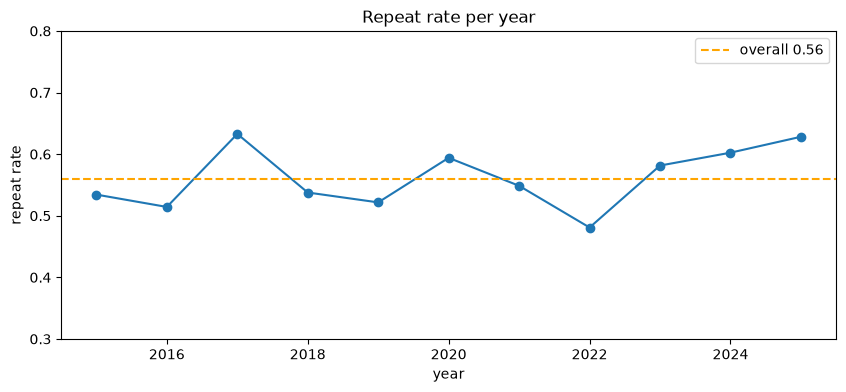

In [37]:
plt.figure(figsize=(10, 4))
plt.plot(by_year.index, by_year["repeat rate"], marker="o")
plt.axhline(df[target_col].mean(), color="orange", linestyle="--", label=f"overall {df[target_col].mean():.2f}")
plt.ylim(0.3, 0.8)
plt.xlabel("year")
plt.ylabel("repeat rate")
plt.title("Repeat rate per year")
plt.legend()
plt.show()

The repeat rate is not the same every year: it goes from 0.48 (2022) to 0.63 (2017 and 2025), and the last years are above the overall average. This means the population changes over time (population drift), so the clients the model will see in the future are not exactly the same as the ones it learned from. 2025 only has 78 rows because the data ends in February 2025.

In [38]:
# how many of the recent purchases come from clients we already knew?
recent = purchase_dates >= "2023-01-01"
old_clients = set(df.loc[~recent, "customer_id"])
recent_clients = set(df.loc[recent, "customer_id"])

print(f"Purchases from 2023 onwards: {recent.sum():,}")
print(f"Made by clients who already bought before 2023: {df.loc[recent, 'customer_id'].isin(old_clients).mean():.1%}")
print(f"Clients active since 2023: {len(recent_clients)} | new clients: {len(recent_clients - old_clients)}")

Purchases from 2023 onwards: 1,602
Made by clients who already bought before 2023: 89.5%
Clients active since 2023: 261 | new clients: 57


Almost 90% of the recent purchases come from clients that already bought before. Clients keep coming back over many years, so a future purchase will usually belong to a client that already has history in the data.

In [39]:
# median of some variables in 3 periods
period = pd.cut(purchase_dates.dt.year, bins=[2014, 2018, 2022, 2025], labels=["2015-2018", "2019-2022", "2023-2025"])
cols_time = ["Total a Pagar", "N_ Detalhes", "days_since_previous_purchase", "purchase_count_90d", "spend_90d",
             "purchase_count_365d", "customer_tenure_days", "prior_purchase_count", "prior_total_spend"]
df.groupby(period, observed=True)[cols_time].median().T.round(1)

purchase_date,2015-2018,2019-2022,2023-2025
Total a Pagar,382.1,489.5,634.4
N_ Detalhes,9.0,12.0,15.0
days_since_previous_purchase,49.0,63.0,61.0
purchase_count_90d,1.0,1.0,1.0
spend_90d,147.9,162.6,352.6
purchase_count_365d,3.0,4.0,4.0
customer_tenure_days,309.0,1238.5,2082.0
prior_purchase_count,4.0,15.0,21.0
prior_total_spend,2275.8,9004.0,15013.7


* The **cumulative variables grow with time** just because the company and the clients get older: the median tenure goes from 309 to 2,082 days and the prior total spend from 2,276 € to 15,014 €. The money values also go up (the median invoice goes from 382 € to 634 €).
* The **behaviour variables stay stable**: the days since the previous purchase (around 50-60) and the number of purchases in the last 90 or 365 days almost do not change.

**What we take from this:**
* The model will always predict the future, so the validation should also be **temporal**: each model is trained on older purchases and validated on the purchases that come after them, never before. A random split would train on future purchases to predict past ones, and the results would look better than they really are. We also leave a gap of 90 days between the train rows and the validation rows, because the target of a purchase looks 90 days ahead.
* We will **not use the year** of the purchase as a variable, because any future purchase will be in a year the model never saw.
* The cumulative variables will always be a bit higher in the future, so the behaviour variables (recency, frequency in fixed windows) are the safer ones.

### **6.Univariate Analysis**

For this part we use a copy of `df` with the corrections we decided in 3.6, so the wrong values do not change the statistics, and with the values that can be recovered exactly (3.6.7). The other missing values are **not** filled here (that is done in Part 2), so every statistic only uses the values that exist.

In [40]:
# exploration copy with the corrections of 3.6 (df stays the same)
df_eda = df.copy()

# prior_mean_purchase_value is total / count, so we recompute it for every row
df_eda["prior_mean_purchase_value"] = df_eda["prior_total_spend"] / df_eda["prior_purchase_count"].replace(0, np.nan)

# spend_365d: 1e9, negative or bigger than the whole prior spend -> missing
bad_spend = (df_eda["spend_365d"] >= 1e8) | (df_eda["spend_365d"] < 0) | (df_eda["spend_365d"] > df_eda["prior_total_spend"] + 0.01)
df_eda.loc[bad_spend, "spend_365d"] = np.nan

# gaps of -4 days -> missing
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    df_eda.loc[df_eda[col] < 0, col] = np.nan

# biggest purchase above its possible limit (3.6.6) -> missing
df_eda.loc[max_too_high, "prior_max_purchase_value"] = np.nan

# missing values that can be computed exactly (3.6.7)
missing_before = df_eda.isna().sum().sum()
df_eda = recover_values(df_eda)

print(f"spend_365d values set to missing: {bad_spend.sum()}")
print(f"Missing cells recovered: {missing_before - df_eda.isna().sum().sum()}")

spend_365d values set to missing: 69
Missing cells recovered: 516


#### **6.1. Numeric Variables**

In [41]:
# numeric columns, taken from the groups of 2.2
numeric_cols = (var_groups["Current transaction (financial)"] + var_groups["Current transaction (operational)"]
                + var_groups["Customer historical summary"] + var_groups["Customer cadence & gaps"]
                + var_groups["Rolling windows (RFM)"])

shape = df_eda[numeric_cols].describe().T[["mean", "50%", "std", "max"]]
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)
shape["skew"] = df_eda[numeric_cols].skew()
shape["% zeros"] = 100 * (df_eda[numeric_cols] == 0).mean()
shape.sort_values("skew", ascending=False).round(2)

,mean,50%,std,max,mean/median,skew,% zeros
Total Desc_ Global,0.35,0.00,5.12,218.49,NaN,27.46,98.30
Total Portes,1.15,0.00,5.84,181.06,NaN,19.55,83.72
prior_mean_gap_days,95.87,68.36,121.73,3199.00,1.40,9.24,0.00
prior_std_gap_days,74.14,50.64,101.82,2212.54,1.46,7.77,0.02
days_since_previous_purchase,102.71,57.00,169.29,3199.00,1.80,6.56,0.00
invoice_count_current_purchase,1.07,1.00,0.31,5.00,1.07,6.44,0.00
Total Desc_ Linha,112.47,13.13,289.99,4103.44,8.57,5.92,37.73
prior_min_purchase_value,185.46,64.34,408.40,6298.98,2.88,5.90,0.00
spend_30d,457.14,0.00,1191.23,22297.21,NaN,5.50,67.12
Total Imp_,152.22,79.74,225.26,4169.40,1.91,4.84,3.29


Almost all the money and count variables are **very skewed to the right** (skew > 2 and the mean much bigger than the median): many small values and a long tail of very big ones. `Total Portes` and `Total Desc_ Global` are 0 in almost every row (84% and 98%), and `invoice_count_current_purchase` is almost always 1.

To be able to see the shape of these variables, the histograms of the very skewed ones (skew > 2) are shown with `log1p`. This is only for the plot, the statistics above use the original values. We use `log1p` and not `log` because many variables have zeros and log(0) does not exist.

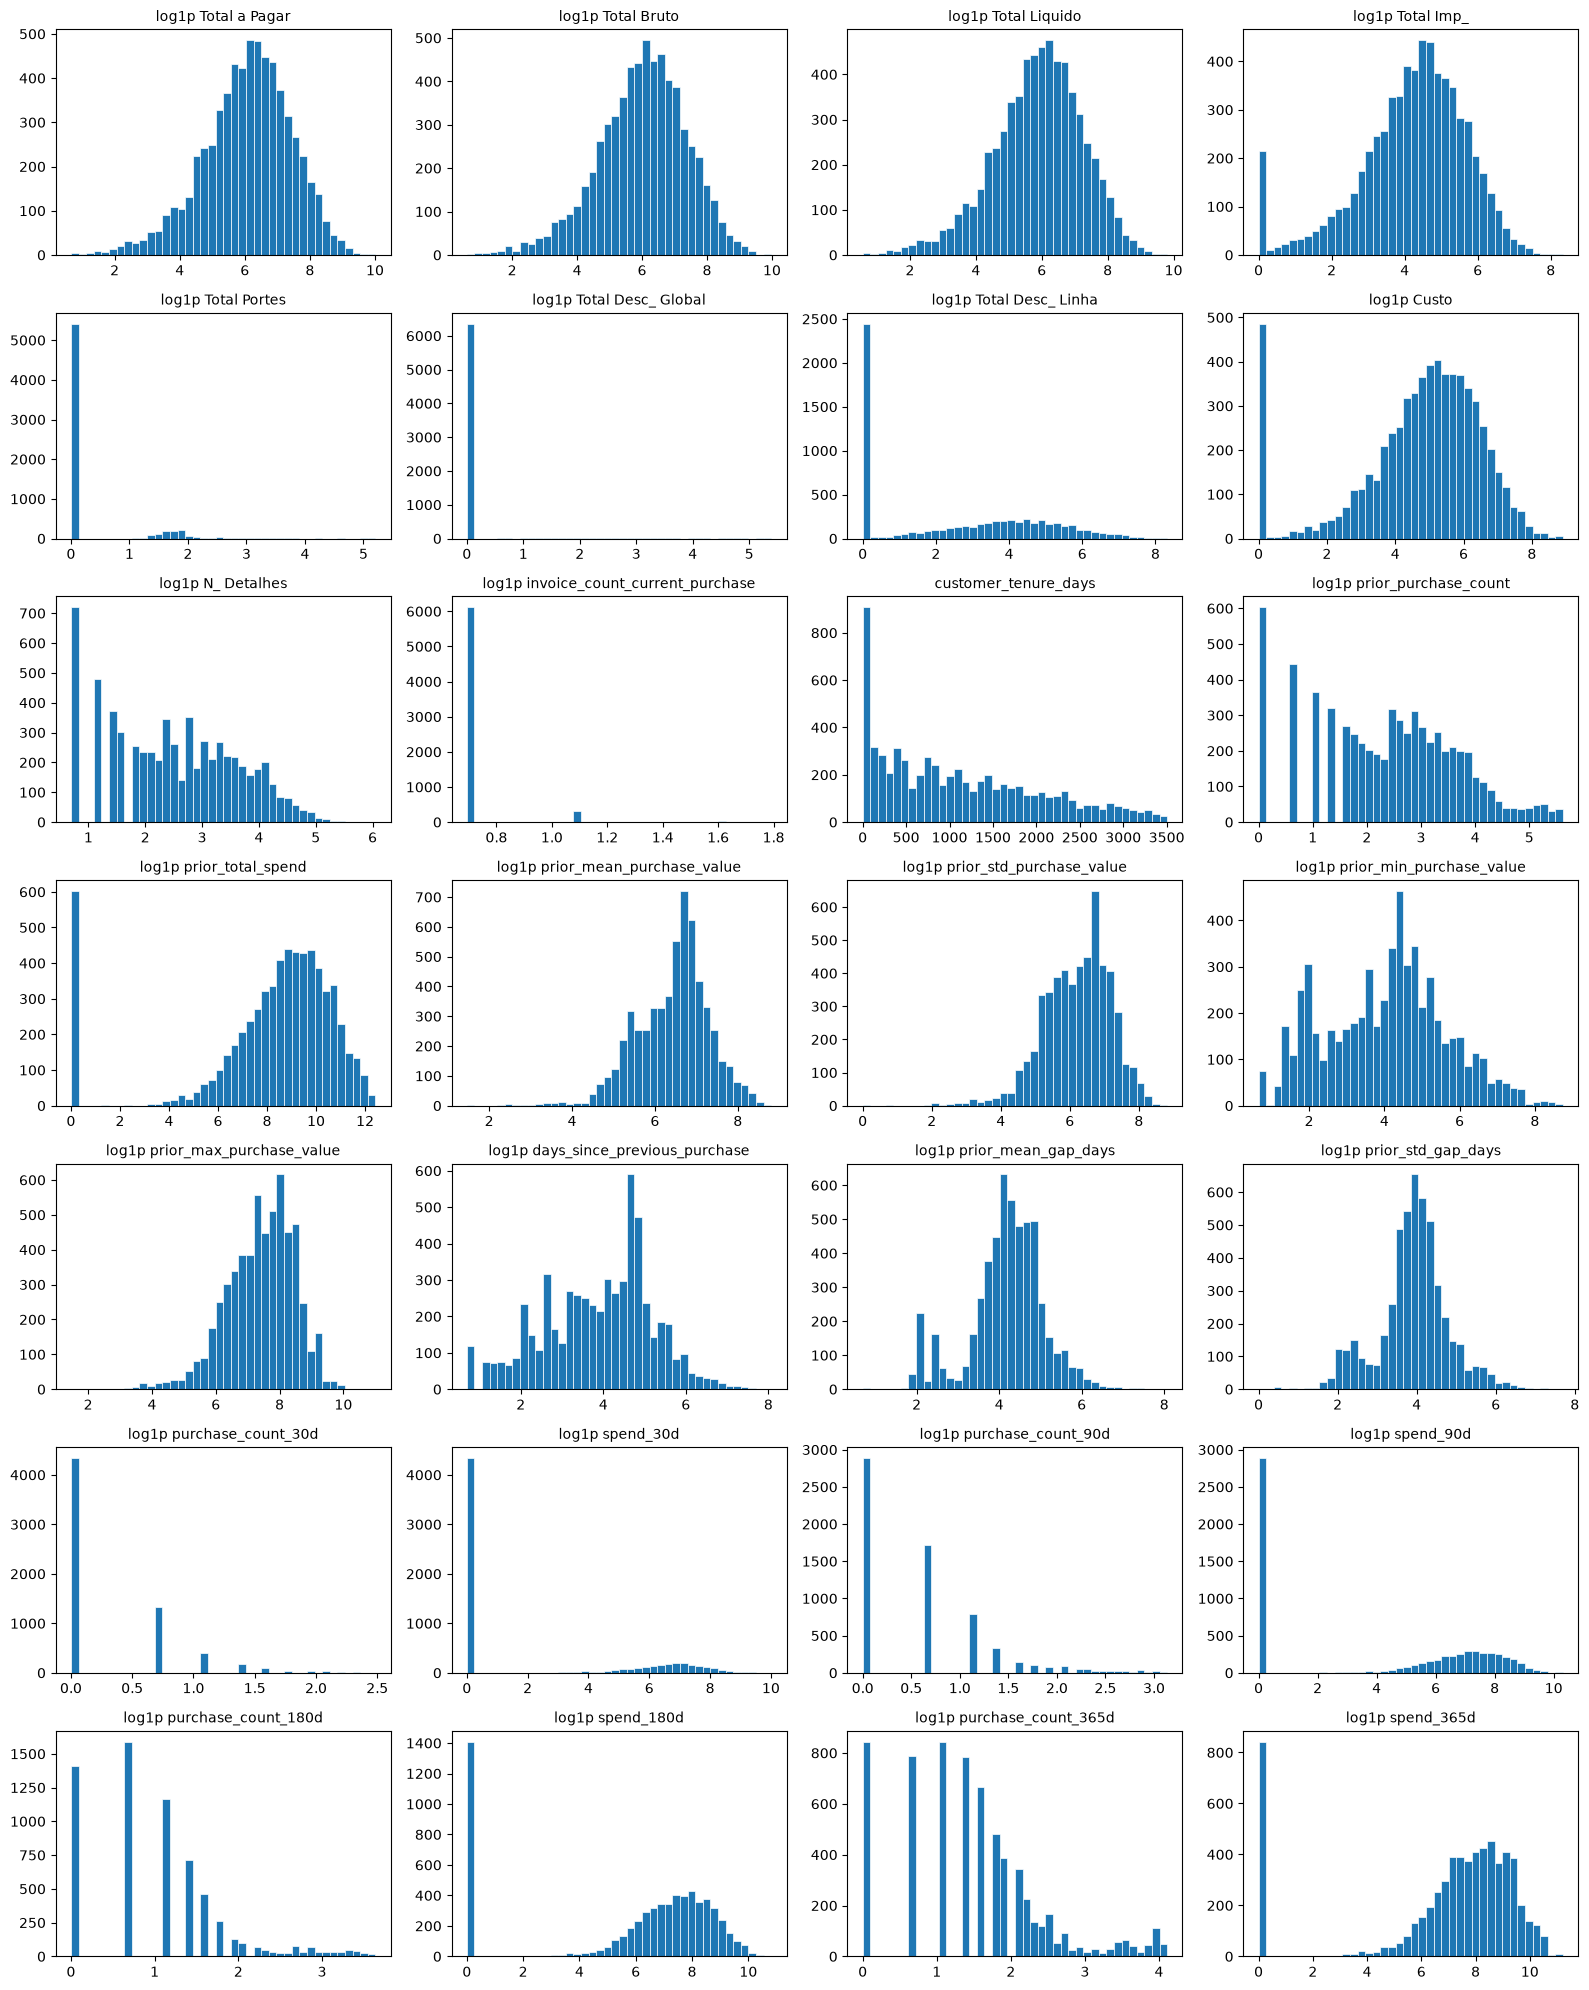

In [42]:
skewed = shape.index[shape["skew"] > 2].tolist()

fig, axes = plt.subplots(7, 4, figsize=(16, 20))
for ax, col in zip(axes.flat, numeric_cols):
    values = df_eda[col].dropna()
    if col in skewed:
        values = np.log1p(values.clip(lower=0))
        ax.set_title(f"log1p {col}", fontsize=10)
    else:
        ax.set_title(col, fontsize=10)
    ax.hist(values, bins=40, edgecolor="white", linewidth=0.5)
for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

* With `log1p` most of the money variables look almost like a normal curve, so a `log1p` transformation can help the linear model in Part 2.
* The rolling windows have a lot of zeros (67% of the rows have no purchase in the last 30 days). Here a zero is information: it means no recent purchase.
* The extreme values of these variables are not errors: in section 4 we saw that they are our best clients, so we keep them.

#### **6.2. Categorical Variables**

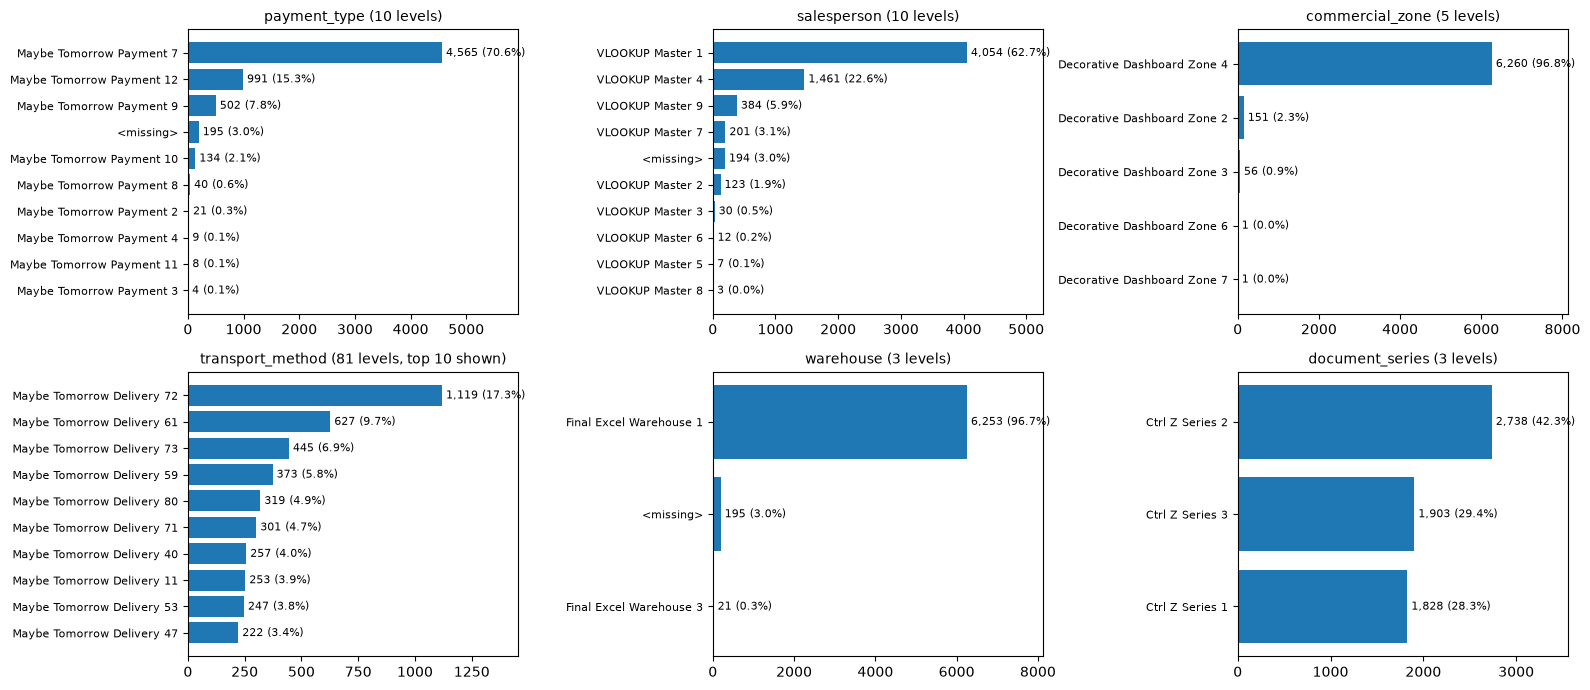

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, cat_cols):
    counts = df_eda[col].fillna("<missing>").value_counts()
    top = counts.head(10)
    ax.barh(top.index[::-1], top.values[::-1])
    # write the number and the % next to each bar (small levels are not visible otherwise)
    for i, v in enumerate(top.values[::-1]):
        ax.text(v, i, f" {v:,} ({100 * v / counts.sum():.1f}%)", va="center", fontsize=8)
    title = f"{col} ({counts.size} levels" + (", top 10 shown)" if counts.size > 10 else ")")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, counts.max() * 1.3)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `warehouse` (Warehouse 1 in 99.7% of the rows with a value) and `commercial_zone` (97% in Zone 4) are almost constant, so they can not say much about the target.
* `Final Excel Warehouse 3` only appears in 21 purchases of 13 clients, all between July 2015 and March 2016. After that every purchase comes from Warehouse 1, so this level marks a period and not a type of client.
* `transport_method` has a long tail: a few methods have most of the rows and many have only a few rows.
* `payment_type` and `salesperson` have one main level but are more spread.

### **7. Relationship with the Target**

#### **7.1. Pearson or Spearman?**

Before measuring the relation of each numeric variable with the target, we have to choose which correlation to use, and then use the same one for all the variables:
* **Pearson** measures **linear** relations (the repeat rate goes up always by the same amount when the variable goes up) and is very sensitive to extreme values.
* **Spearman** uses the ranks of the values, so it measures any **monotonic** relation (always up or always down, even if not in a straight line) and is not affected by the extreme values.

The target is 0/1, so a normal scatter plot would only show two lines of points. Instead, we cut each variable in 10 groups with the same number of rows (deciles) and plot the repeat rate of each group against the median value of the group. If the points make a straight line the relation is linear, if they go up or down but curve it is monotonic.

We use equal-depth and not equal-width because our variables are very skewed: with equal-width almost all the rows would fall in the first interval and the other ones would be almost empty. With 10 groups each one has about 650 rows, so the repeat rate of each group is stable. This discretization is only used to look at the relations, the variables themselves are not changed here.

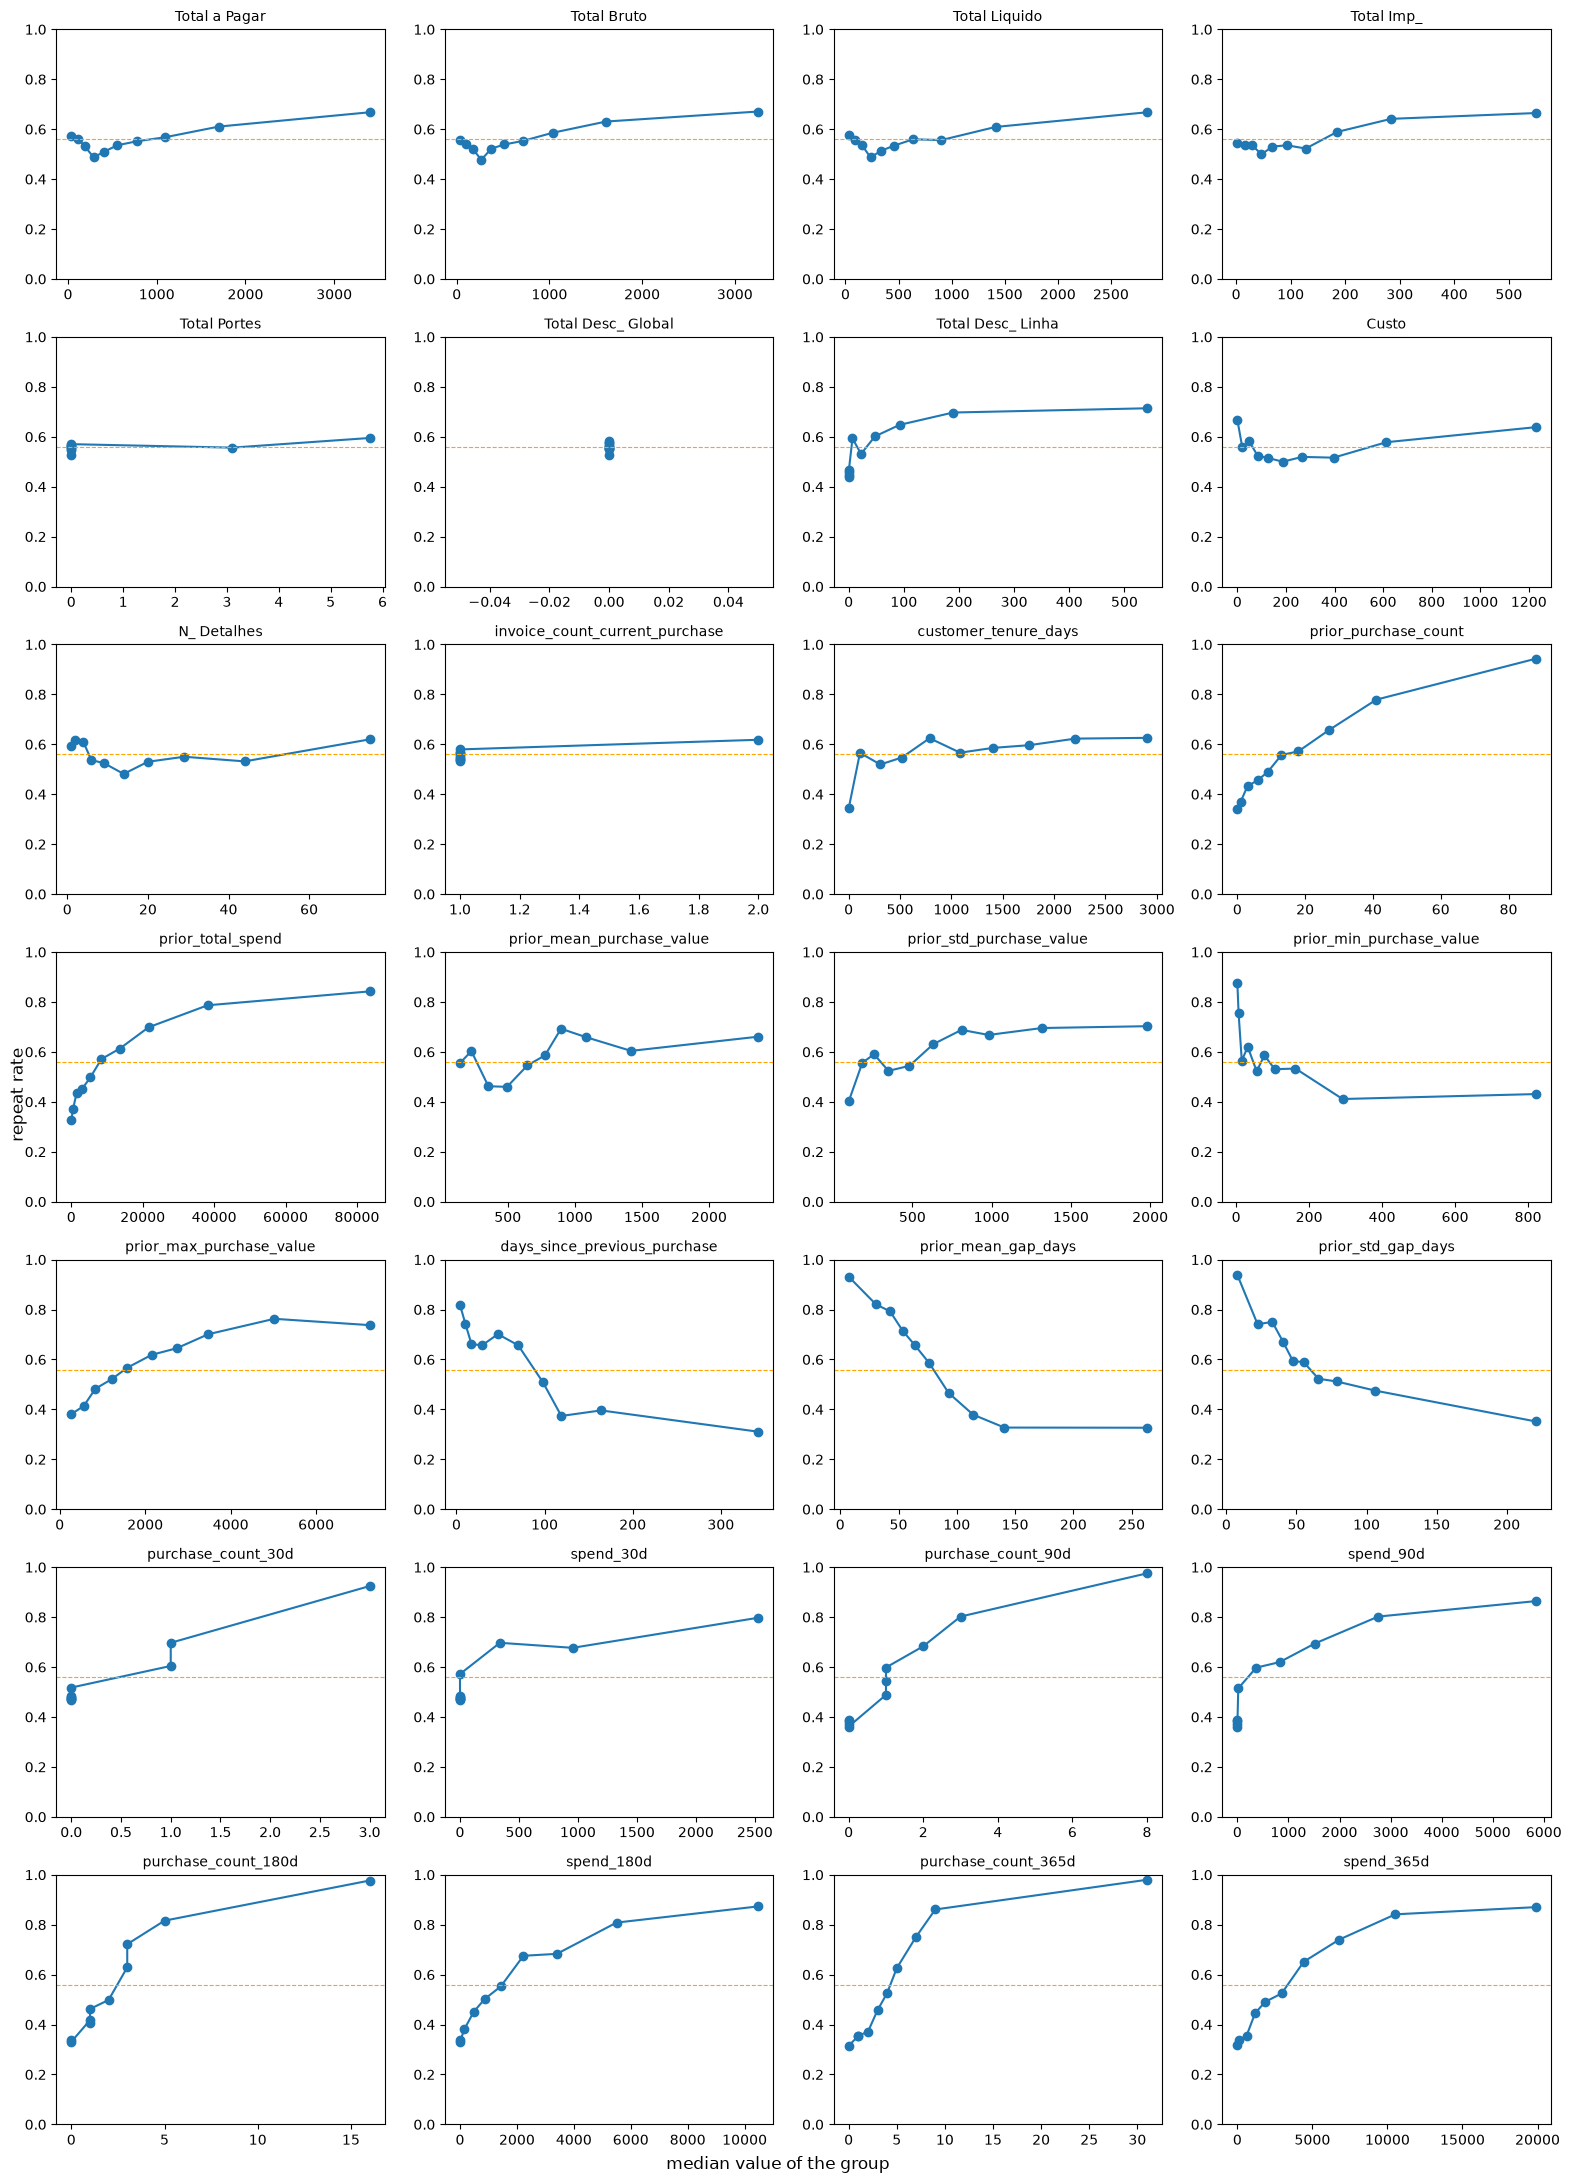

In [44]:
# repeat rate in 10 groups of each variable (deciles)
fig, axes = plt.subplots(7, 4, figsize=(16, 22))
for ax, col in zip(axes.flat, numeric_cols):
    pair = df_eda[[col, target_col]].dropna()
    # we cut the rank and not the value, so variables with many equal values (like zeros) also get 10 groups
    groups = pd.qcut(pair[col].rank(method="first"), 10, labels=False)
    by_group = pair.groupby(groups).agg(median=(col, "median"), rate=(target_col, "mean"))
    ax.plot(by_group["median"], by_group["rate"], marker="o")
    ax.axhline(df_eda[target_col].mean(), color="orange", linestyle="--", linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 1)
for ax in axes.flat[len(numeric_cols):]:
    ax.set_visible(False)
fig.supxlabel("median value of the group")
fig.supylabel("repeat rate")
plt.tight_layout()
plt.show()

* Almost no variable makes a straight line. The most important ones are **monotonic but curved**: the count and spend variables (`prior_purchase_count`, `prior_total_spend`, `purchase_count_365d`, `spend_365d`...) go up fast in the first groups and then become almost flat, and `prior_mean_gap_days` and `days_since_previous_purchase` go down until about 120-150 days and then stay flat.
* The values of the current invoice (`Total a Pagar`, `Custo`, `N_ Detalhes`) are almost flat and not even monotonic (they go a bit down and then up), so their correlation will be close to 0 with any method.
* So the relations are monotonic but not linear, and in 6.1 we saw that the variables have many extreme values. Both things are a problem for Pearson but not for Spearman. Lets confirm it with the numbers.

In [45]:
corr_rows = []
for col in numeric_cols:
    pair = df_eda[[col, target_col]].dropna()
    corr_rows.append({"feature": col,
                      "Pearson": pair[col].corr(pair[target_col], method="pearson"),
                      "Spearman": pair[col].corr(pair[target_col], method="spearman")})

compare = pd.DataFrame(corr_rows).set_index("feature")
compare["|Spearman| - |Pearson|"] = compare["Spearman"].abs() - compare["Pearson"].abs()
print(f"Spearman is bigger than Pearson in {(compare['|Spearman| - |Pearson|'] > 0).sum()} of {len(compare)} variables")
compare.sort_values("|Spearman| - |Pearson|", ascending=False).round(3)

Spearman is bigger than Pearson in 22 of 28 variables


,Pearson,Spearman,|Spearman| - |Pearson|
feature,,,
prior_mean_gap_days,-0.241,-0.419,0.179
prior_min_purchase_value,-0.099,-0.235,0.137
days_since_previous_purchase,-0.199,-0.316,0.116
prior_std_gap_days,-0.205,-0.315,0.111
Total Desc_ Linha,0.092,0.197,0.105
purchase_count_365d,0.340,0.437,0.097
spend_90d,0.269,0.359,0.090
purchase_count_180d,0.334,0.406,0.072
spend_30d,0.165,0.236,0.071


Spearman is bigger than Pearson in almost all the variables, and the difference is biggest exactly in the most useful ones: `prior_mean_gap_days` (−0.42 with Spearman vs −0.24 with Pearson), `days_since_previous_purchase` (−0.32 vs −0.20) or `purchase_count_365d` (0.44 vs 0.34). Pearson only gives a bigger value in the invoice values, where both are close to 0. Pearson underestimates the relations because they are curved and the extreme values pull the line.

**So we use the Spearman correlation for all the numeric variables**.

#### **7.2. Numeric Variables**

Following 7.1, we measure the relationship between each numeric variable and the target with the **Spearman** correlation, and we also show the median of each variable in each class.

In [46]:
rel_rows = []
for col in numeric_cols:
    pair = df_eda[[col, target_col]].dropna()
    rho, p_value = stats.spearmanr(pair[col], pair[target_col])
    rel_rows.append({"feature": col, "Spearman rho": rho, "p-value": p_value,
                     "median | 0": pair.loc[pair[target_col] == 0, col].median(),
                     "median | 1": pair.loc[pair[target_col] == 1, col].median()})

relevance = pd.DataFrame(rel_rows).set_index("feature")
relevance = relevance.reindex(relevance["Spearman rho"].abs().sort_values(ascending=False).index)
relevance.round(3)

,Spearman rho,p-value,median | 0,median | 1
feature,,,,
purchase_count_365d,0.437,0.000,2.000,5.000
prior_mean_gap_days,-0.419,0.000,102.625,55.758
purchase_count_180d,0.406,0.000,1.000,3.000
purchase_count_90d,0.393,0.000,0.000,1.000
spend_365d,0.391,0.000,1100.760,4434.460
spend_180d,0.370,0.000,457.870,2106.220
spend_90d,0.359,0.000,0.000,746.190
prior_purchase_count,0.346,0.000,6.000,17.000
prior_total_spend,0.332,0.000,3246.525,12098.990


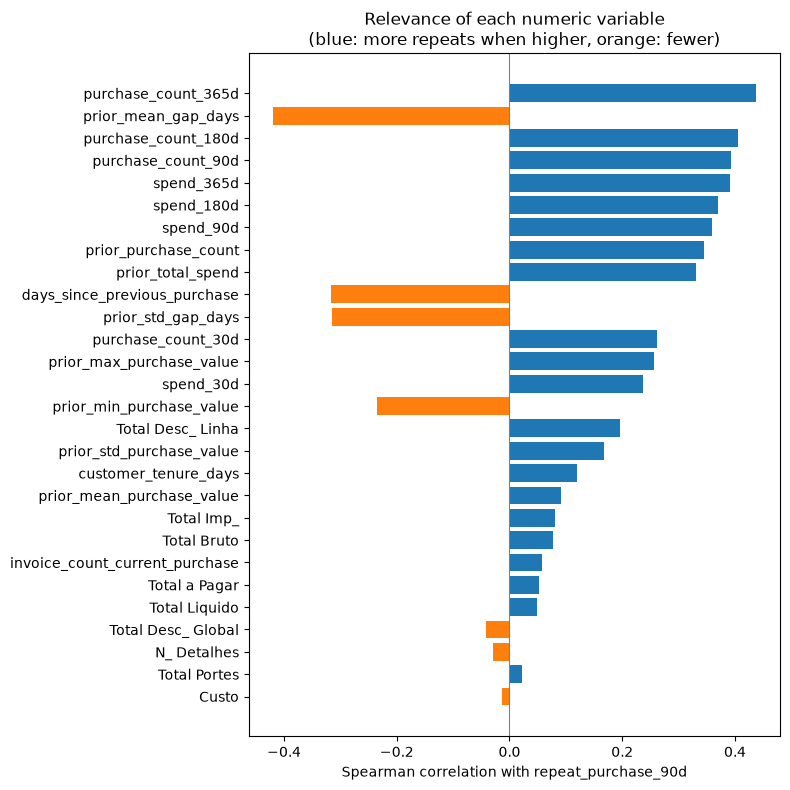

In [47]:
values = relevance["Spearman rho"]
colors = ["tab:blue" if v > 0 else "tab:orange" for v in values[::-1]]

plt.figure(figsize=(8, 8))
plt.barh(values.index[::-1], values.values[::-1], color=colors)
plt.axvline(0, color="grey", linewidth=0.8)
plt.xlabel("Spearman correlation with repeat_purchase_90d")
plt.title("Relevance of each numeric variable\n(blue: more repeats when higher, orange: fewer)")
plt.tight_layout()
plt.show()

* **Recency and frequency are the strongest signals.** The clients who bought more times in the last 90, 180 and 365 days come back more (for example `purchase_count_365d`: median of 2 purchases for class 0 and 5 for class 1), and the clients with smaller gaps between purchases also come back more (`prior_mean_gap_days`: median of 103 days for class 0 and 56 for class 1). This is the RFM logic (Recency, Frequency, Monetary).
* **The values of the current invoice matter very little** (`Total a Pagar`, `Total Bruto`, `Total Liquido` have correlations close to 0).
* `customer_tenure_days` is weak: being an old client is not the same as being an active client.
* With 6,469 rows almost every p-value is very small, so we look at the size of the correlation and not at the p-value.

#### **7.3. Recency and Frequency**

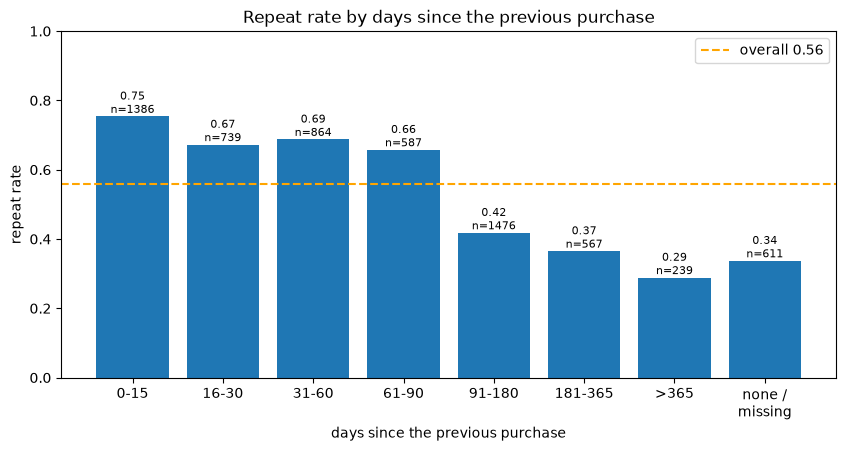

In [48]:
bins = [0, 15, 30, 60, 90, 180, 365, np.inf]
labels = ["0-15", "16-30", "31-60", "61-90", "91-180", "181-365", ">365"]
recency = pd.cut(df_eda["days_since_previous_purchase"], bins=bins, labels=labels, include_lowest=True)
recency = recency.cat.add_categories("none /\nmissing").fillna("none /\nmissing")
by_recency = df_eda.groupby(recency, observed=True)[target_col].agg(["mean", "size"])

plt.figure(figsize=(10, 4.5))
plt.bar(by_recency.index.astype(str), by_recency["mean"])
plt.axhline(df_eda[target_col].mean(), color="orange", linestyle="--", label=f"overall {df_eda[target_col].mean():.2f}")
for i, (rate, n) in enumerate(zip(by_recency["mean"], by_recency["size"])):
    plt.text(i, rate + 0.01, f"{rate:.2f}\nn={n}", ha="center", fontsize=8)
plt.ylim(0, 1)
plt.xlabel("days since the previous purchase")
plt.ylabel("repeat rate")
plt.title("Repeat rate by days since the previous purchase")
plt.legend()
plt.show()

In [49]:
# first purchases (no previous purchase at all) vs the rest
first_purchase = df_eda["prior_purchase_count"] == 0
print(f"First purchases: {first_purchase.sum()} rows, repeat rate {df_eda.loc[first_purchase, target_col].mean():.3f}")
print(f"Other purchases: {(~first_purchase).sum()} rows, repeat rate {df_eda.loc[~first_purchase, target_col].mean():.3f}")

First purchases: 603 rows, repeat rate 0.333
Other purchases: 5866 rows, repeat rate 0.583


In [50]:
# frequency: repeat rate by number of purchases in the previous 90 days
freq = df_eda["purchase_count_90d"].clip(upper=6).astype("Int64").astype(str).replace({"6": "6+"})
df_eda.groupby(freq)[target_col].agg(["mean", "size"]).rename(columns={"mean": "repeat rate", "size": "rows"}).round(3)

,repeat rate,rows
purchase_count_90d,,
0,0.379,2889
1,0.568,1714
2,0.712,787
3,0.832,328
4,0.879,149
5,0.940,100
6+,0.986,502


* There is a **clear break at 90 days**: clients whose previous purchase was less than 90 days ago come back in 66% to 75% of the cases, after 90 days the rate falls to around 40%, and to 29% after one year. The relation is not linear, so `log1p` or bins can help a linear model.
* **First purchases** (no previous purchase at all) come back in only **33%** of the cases, close to the clients whose previous purchase was more than one year ago. The "none / missing" bar of the plot (34%) is now almost only these first purchases, because the other missing values of `days_since_previous_purchase` were recovered in 3.6.7. This is why we want a flag `is_first_purchase` in Part 2 instead of just filling their missing values.
* **Frequency is even clearer**: with no purchase in the previous 90 days the repeat rate is 38%, with one purchase 57%, with three 83% and with six or more 99%.

#### **7.4. Rhythm of each Client**

The same number of days does not mean the same for every client: 30 days is a lot for a client who buys every week and very little for a client who buys once a year. So we test a ratio that compares the days since the previous purchase with the usual gap of the client: `days_since_previous_purchase / prior_mean_gap_days`. A value below 1 means this purchase came sooner than usual, and above 1 later than usual.

In [51]:
rhythm = df_eda["days_since_previous_purchase"] / df_eda["prior_mean_gap_days"].replace(0, np.nan)
pair = pd.DataFrame({"rhythm": rhythm, target_col: df_eda[target_col]}).dropna()

rho, _ = stats.spearmanr(pair["rhythm"], pair[target_col])
print(f"Spearman correlation with the target: {rho:.3f}")
pair.groupby(target_col)["rhythm"].describe()[["count", "25%", "50%", "75%"]].round(2)

Spearman correlation with the target: -0.054


,count,25%,50%,75%
repeat_purchase_90d,,,,
0,2164.0,0.34,0.92,1.62
1,3249.0,0.34,0.77,1.45


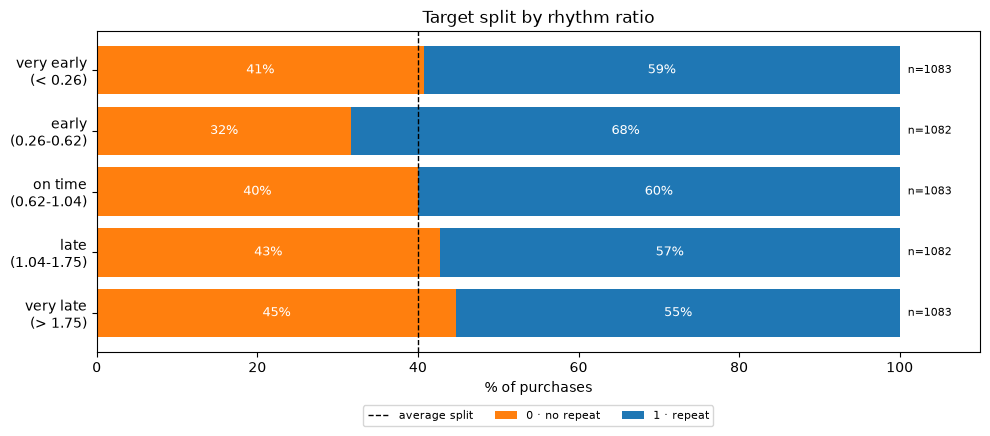

In [52]:
# share of 0 and 1 in each group of the ratio
pair["rhythm group"] = pd.qcut(pair["rhythm"], 5, labels=["very early\n(< 0.26)", "early\n(0.26-0.62)",
                                                           "on time\n(0.62-1.04)", "late\n(1.04-1.75)",
                                                           "very late\n(> 1.75)"])
shares = pd.crosstab(pair["rhythm group"], pair[target_col], normalize="index") * 100
rows = pair["rhythm group"].value_counts().reindex(shares.index)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(shares.index[::-1], shares[0][::-1], color="tab:orange", label="0 · no repeat")
ax.barh(shares.index[::-1], shares[1][::-1], left=shares[0][::-1], color="tab:blue", label="1 · repeat")
for i, (zero, one, n) in enumerate(zip(shares[0][::-1], shares[1][::-1], rows[::-1])):
    ax.text(zero / 2, i, f"{zero:.0f}%", va="center", ha="center", color="white", fontsize=9)
    ax.text(zero + one / 2, i, f"{one:.0f}%", va="center", ha="center", color="white", fontsize=9)
    ax.text(101, i, f"n={n}", va="center", fontsize=8)
ax.axvline(100 - 100 * pair[target_col].mean(), color="black", linestyle="--", linewidth=1, label="average split")
ax.set(xlim=(0, 110), xlabel="% of purchases", title="Target split by rhythm ratio")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

The ratio is very similar in the two classes (median 0.92 for class 0 and 0.77 for class 1, Spearman −0.05). Only the "early" group (clients who came back at about half of their usual gap) stands out, with 68% of repeats against about 60% on average. The other groups are close to the average. So the idea makes sense, but alone the ratio has much less signal than the recency and the frequency. We keep it only as a candidate variable for Part 2, and the feature selection will decide.

#### **7.5. Categorical Variables**

For two categorical variables we use the **chi-square test** and the **Cramér's V** (from 0 = no association to 1 = perfect association). The chi-square is only reliable when the expected count of every cell is around 5 or more, so we also show the minimum expected count.

In [53]:
cat_rows = []
for col in cat_cols:
    x = df_eda[col].fillna("<missing>") # the missing values are transformed in a string "<miaaing>" to not lose them
    table = pd.crosstab(x, df_eda[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    cat_rows.append({"feature": col, "levels": table.shape[0], "chi2": chi2, "p-value": p_value,
                     "Cramer's V": v, "min expected count": expected.min()})
pd.DataFrame(cat_rows).set_index("feature").sort_values("Cramer's V", ascending=False).round(4)

,levels,chi2,p-value,Cramer's V,min expected count
feature,,,,,
transport_method,81,527.2252,0.0000,0.2855,0.4403
payment_type,10,354.3527,0.0000,0.2340,1.7610
salesperson,10,260.7604,0.0000,0.2008,1.3208
commercial_zone,5,26.2955,0.0000,0.0638,0.4403
warehouse,3,10.1673,0.0062,0.0396,9.2453
document_series,3,0.0553,0.9727,0.0029,804.7834


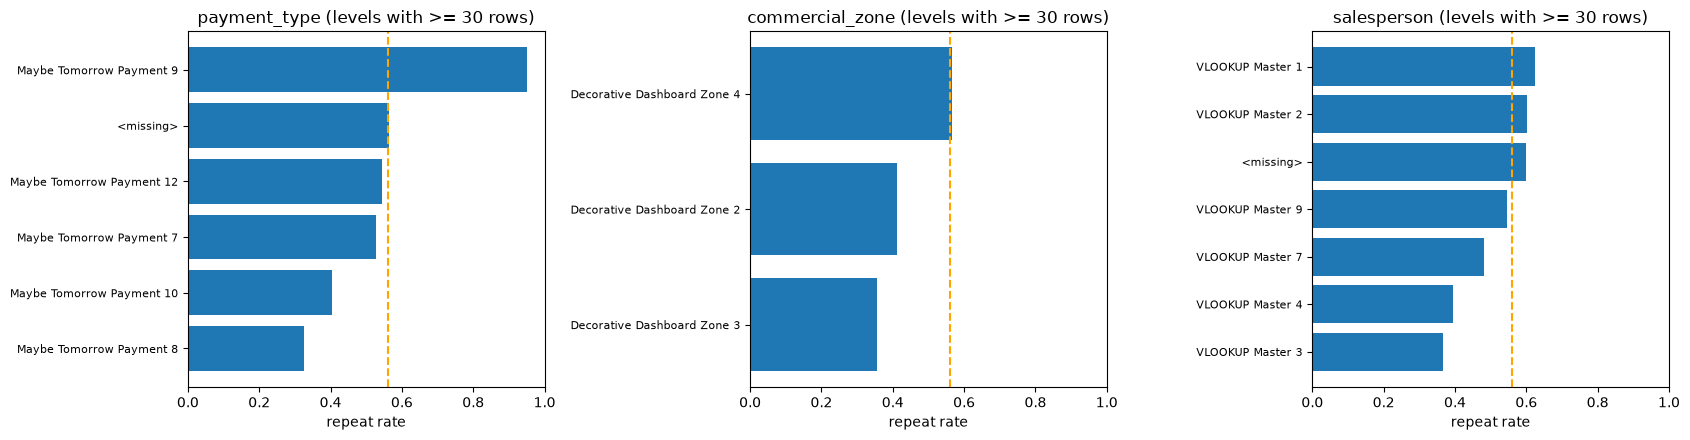

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["payment_type", "commercial_zone", "salesperson"]):
    by_level = df_eda.groupby(df_eda[col].fillna("<missing>"))[target_col].agg(["mean", "size"])
    by_level = by_level[by_level["size"] >= 30].sort_values("mean")
    ax.barh(by_level.index, by_level["mean"])
    ax.axvline(df_eda[target_col].mean(), color="orange", linestyle="--")
    ax.set(xlim=(0, 1), title=f"{col} (levels with >= 30 rows)", xlabel="repeat rate")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

* `transport_method`, `payment_type` and `salesperson` have a moderate association with the target (Cramér's V between 0.20 and 0.29). Some payment types have repeat rates far from the average, which makes sense: the payment terms can show the type of relationship with the client.
* The V of `transport_method` is partly high **because** it has 80 levels: many tiny levels with extreme rates push the V up (their expected counts are far below 5). Grouping the rare levels into "Other" in Part 2 is what makes this variable usable.
* `commercial_zone` and `warehouse` have a weak association, and `document_series` has none (V ≈ 0, p = 0.97).

### **8. Redundancy between Variables**

Two variables can both be related to the target and still say the same thing. To check this we use the Spearman correlation between all the numeric variables and list the pairs above 0.90.

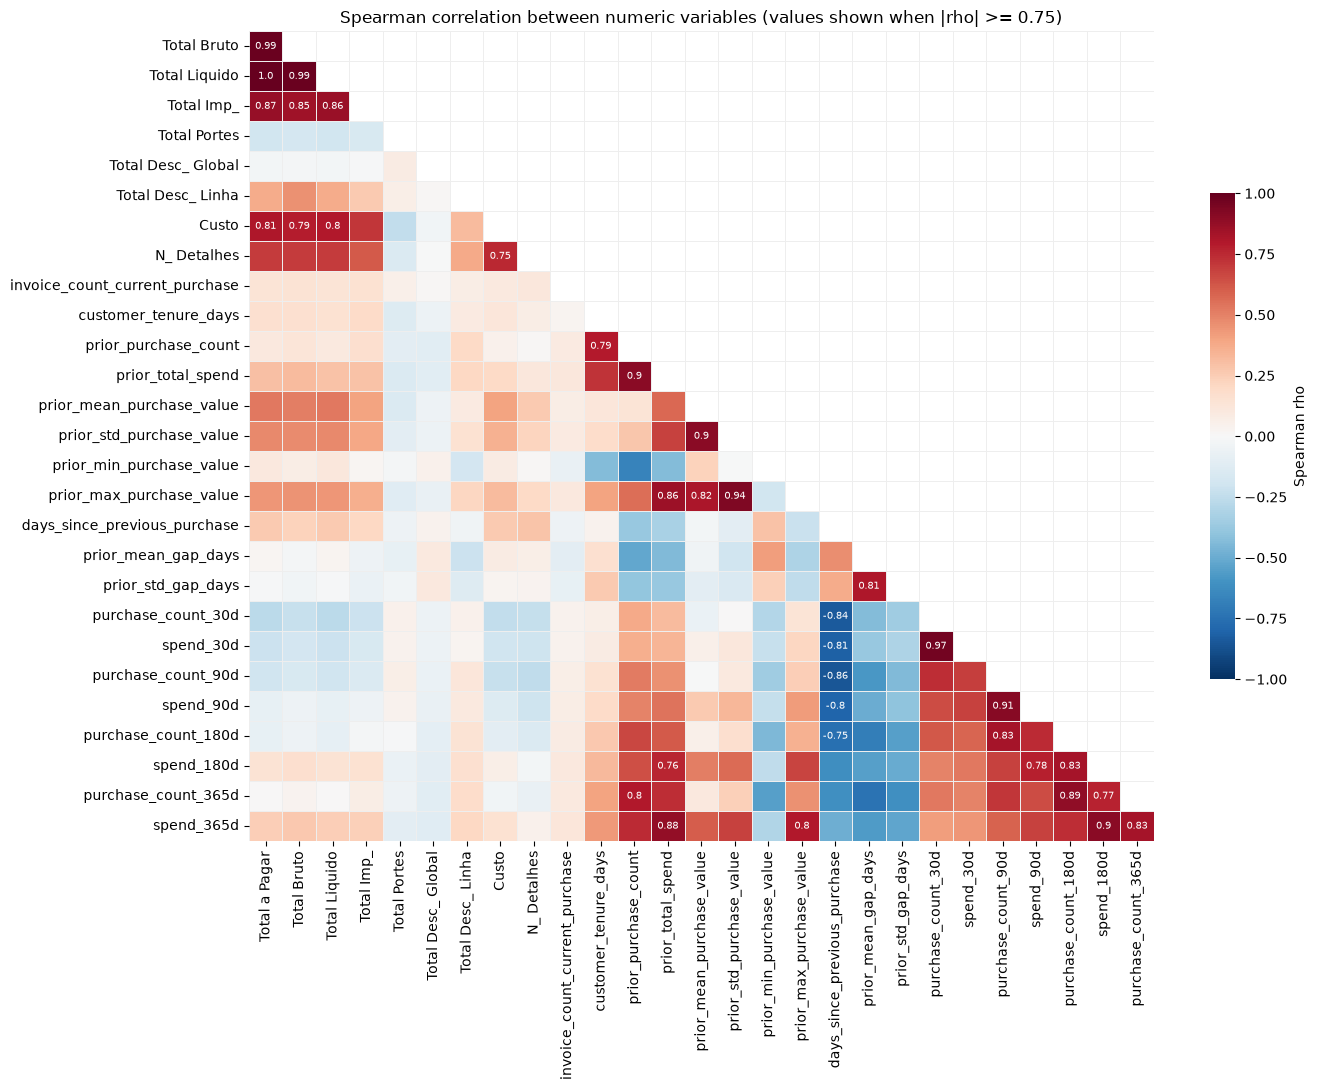

In [55]:
corr = df_eda[numeric_cols].corr(method="spearman")

# only the lower triangle (the upper one is the same), without the empty first row and last column
corr_plot = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_plot, dtype=bool), k=1)

# write the value only in the strong correlations
strong = 0.75
annot = corr_plot.round(2).astype(str).where(corr_plot.abs() >= strong, "")

fig, ax = plt.subplots(figsize=(14, 11), facecolor="white")
ax.set_facecolor("white")
sns.heatmap(corr_plot, mask=mask, annot=annot, fmt="", annot_kws={"size": 7}, cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, linewidths=0.5, linecolor="#EEEEEE",
            cbar_kws={"shrink": 0.6, "label": "Spearman rho"}, ax=ax)
ax.set_title(f"Spearman correlation between numeric variables (values shown when |rho| >= {strong})")
plt.tight_layout()
plt.show()

In [56]:
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().reset_index()
pairs.columns = ["variable A", "variable B", "Spearman rho"]
pairs = pairs.reindex(pairs["Spearman rho"].abs().sort_values(ascending=False).index)
pairs[pairs["Spearman rho"].abs() >= 0.90].round(3).reset_index(drop=True)

,variable A,variable B,Spearman rho
0,Total Liquido,Total a Pagar,1.000
1,Total Liquido,Total Bruto,0.991
2,Total Bruto,Total a Pagar,0.991
3,spend_30d,purchase_count_30d,0.965
4,prior_max_purchase_value,prior_std_purchase_value,0.936
5,spend_90d,purchase_count_90d,0.909
6,prior_total_spend,prior_purchase_count,0.903
7,spend_365d,spend_180d,0.901


In [57]:
# some links come from how the columns are built
no_recent = df_eda["purchase_count_90d"] == 0
print(f"Rows with no purchase in the last 90 days and days_since_previous_purchase > 90: "
      f"{(df_eda.loc[no_recent, 'days_since_previous_purchase'].dropna() > 90).mean():.1%}")

Rows with no purchase in the last 90 days and days_since_previous_purchase > 90: 100.0%


Eight pairs are above 0.90:
* `Total a Pagar`, `Total Bruto` and `Total Liquido` (0.99 to 1.00): they are linked by the accounting rules (net = gross − discounts), so one of them is enough.
* The count and the spend of the short windows: `purchase_count_30d` with `spend_30d` (0.97) and `purchase_count_90d` with `spend_90d` (0.91).
* `prior_purchase_count` with `prior_total_spend` (0.90), `prior_max_purchase_value` with `prior_std_purchase_value` (0.94) and `spend_365d` with `spend_180d` (0.90).

Redundancy is a problem mainly for the linear model (unstable coefficients), so in Part 3 we will use a redundancy filter and then the other feature selection methods.

### **9. The Clients Table (clientes.csv)**

The guidelines ask us to decide if and how to use `clientes.csv` through `customer_id`. First we check the quality of the table, then if it adds something new.

In [58]:
print(f"Clients in clientes.csv: {len(df_clientes):,} | customer_id unique: {df_clientes['customer_id'].is_unique}")
print(f"Train clients found in clientes.csv: {df['customer_id'].isin(df_clientes['customer_id']).mean():.0%}")

# we only look at our clients, the other rows of the table never reach the model
clientes_train = df_clientes[df_clientes["customer_id"].isin(df["customer_id"])]
print(f"Train clients described: {len(clientes_train)}")

pd.DataFrame({
    "% missing": (100 * clientes_train.isna().mean()).round(1),
    "distinct values": clientes_train.nunique(),
    "distinct / clients": (clientes_train.nunique() / len(clientes_train)).round(3),
})

Clients in clientes.csv: 1,143 | customer_id unique: True
Train clients found in clientes.csv: 100%
Train clients described: 607


,% missing,distinct values,distinct / clients
customer_id,0.0,607,1.000
country_or_region,0.0,7,0.012
commercial_region,2.0,32,0.053
island,46.8,10,0.016
municipality,6.8,150,0.247
city,38.6,259,0.427
postal_area,6.6,188,0.310
postal_code,3.3,516,0.850
street,54.2,264,0.435
address,0.0,597,0.984


* `customer_id` is a good key: it is unique in the table and every client of the train is there. The table has 1,143 clients and the train only 607, but this is not a problem if we do a **left join** from the purchases (each purchase gets its client and the number of rows does not change) and we do not compute any statistic on the whole table.
* `customer_type` is **100% empty**.
* `company_name`, `address`, `street`, `postal_code` and `city` are almost unique for each client, so they identify the client instead of describing him (the same problem as using `customer_id`). Some of them are also half empty.
* The possible variables are the geography (`country_or_region` 7 levels, `commercial_region` 32, `island` 10, `municipality` 150, `postal_area` 188) and `customer_since_year`.

In [59]:
# join the candidate columns to each purchase and measure the association with the target
candidates = ["country_or_region", "commercial_region", "island", "municipality", "customer_since_year"]
joined = df_eda.join(df_clientes.set_index("customer_id")[candidates], on="customer_id")

rows = []
for col in candidates:
    x = joined[col].astype("string").fillna("<missing>")
    table = pd.crosstab(x, joined[target_col])
    chi2, p_value, _, expected = chi2_contingency(table, correction=False)
    rows.append({"feature": col, "levels": table.shape[0],
                 "Cramer's V": np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))),
                 "min expected count": expected.min()})
pd.DataFrame(rows).set_index("feature").round(3)

,levels,Cramer's V,min expected count
feature,,,
country_or_region,7,0.066,0.440
commercial_region,33,0.264,0.440
island,11,0.148,4.403
municipality,151,0.365,0.440
customer_since_year,10,0.196,11.447


In [60]:
# is customer_since_year new information, or the same as customer_tenure_days?
purchase_year = pd.to_datetime(joined["purchase_date"]).dt.year
years_as_client = purchase_year - joined["customer_since_year"]
rho, _ = stats.spearmanr(years_as_client, joined["customer_tenure_days"], nan_policy="omit")
print(f"Spearman(purchase year - customer_since_year, customer_tenure_days) = {rho:.3f}")
print(f"Purchases made before the customer_since_year: {(years_as_client < 0).mean():.1%}")

Spearman(purchase year - customer_since_year, customer_tenure_days) = 0.917
Purchases made before the customer_since_year: 0.0%


When we look at `customer_since_year`, 2015 has much more clients than the other years. Since the data only starts in July 2015, lets check if these are really new clients or old clients that were loaded into the system when it started.

In [61]:
# how many clients have 2015 as start year, inside and outside the train?
in_train = df_clientes["customer_id"].isin(df["customer_id"])
since_2015 = df_clientes["customer_since_year"] == 2015
print(f"Clients with customer_since_year = 2015: {since_2015.sum()} of {len(df_clientes)}")
print(f"  clients in train: {since_2015[in_train].mean():.0%} ({since_2015[in_train].sum()} of {in_train.sum()})")
print(f"  clients not in train: {since_2015[~in_train].mean():.0%} ({since_2015[~in_train].sum()} of {(~in_train).sum()})")

# first purchases in 2015 vs first purchases in the other years
first_purchase = df_eda["prior_purchase_count"] == 0
year = pd.to_datetime(df_eda["purchase_date"]).dt.year
print(f"\nRepeat rate of first purchases in 2015: {df_eda.loc[first_purchase & (year == 2015), target_col].mean():.2f}")
print(f"Repeat rate of first purchases after 2015: {df_eda.loc[first_purchase & (year > 2015), target_col].mean():.2f}")

Clients with customer_since_year = 2015: 664 of 1143
  clients in train: 39% (238 of 607)
  clients not in train: 79% (426 of 536)

Repeat rate of first purchases in 2015: 0.45
Repeat rate of first purchases after 2015: 0.29


More than half of all the clients (664 of 1,143) have 2015 as start year, while in the other years only 13 to 82 clients join per year. Most of these 2015 clients never buy anything in our data (79% of the clients that are not in the train are from 2015). Also, the "first purchases" of 2015 come back much more than the first purchases of the other years (45% vs 29%), so they look like old clients and not new ones.

So it looks like the company started this system in 2015 and loaded all the clients it already had, but not their old purchases. This means that in 2015 the history variables (`prior_purchase_count`, `customer_tenure_days`...) are lower than the real history of these clients, and some "first purchases" are not really first purchases. So the purchases of 2015 can teach the model something wrong: clients that look new but behave like loyal clients. In Part 2 we will test if the model gets better when we remove the 2015 purchases from the training data, or when we add a flag for this period.

In [62]:
# is a missing island related to the target?
island_missing = joined["island"].isna()
print(f"Island missing: {island_missing.sum()} purchases ({joined.loc[island_missing, 'customer_id'].nunique()} clients), repeat rate {joined.loc[island_missing, target_col].mean():.2f}")
print(f"Island known: {(~island_missing).sum()} purchases ({joined.loc[~island_missing, 'customer_id'].nunique()} clients), repeat rate {joined.loc[~island_missing, target_col].mean():.2f}")

Island missing: 2189 purchases (284 clients), repeat rate 0.64
Island known: 4280 purchases (323 clients), repeat rate 0.52


`island` is missing for almost half of the clients, and these clients come back more (64% vs 52%). Lets check where these clients are, to understand what a missing island means.

In [63]:
# where are the clients with and without island?
island_known = clientes_train["island"].notna()
country = clientes_train["country_or_region"].str.split(":").str[0]
region = clientes_train["commercial_region"].str.split(":").str[0]

print("Regions of the clients with island:", region[island_known].value_counts().to_dict())
island_regions = region.isin(["Region RG17", "Region RG29"])
print("Clients in RG17 or RG29 without island:", (island_regions & ~island_known).sum())

pd.crosstab(country, island_known)

Regions of the clients with island: {'Region RG17': 301, 'Region RG29': 22}
Clients in RG17 or RG29 without island: 0


island,False,True
country_or_region,,
Country CT10,246,323
Country CT4,1,0
Country CT5,30,0
Country CT6,3,0
Country CT7,2,0
Country CT8,1,0
Country CT9,1,0


All the clients with an island are from `Country CT10` and from only two regions (RG17 and RG29), and every client of these two regions has the island filled. The clients without island are the other regions of CT10 (the mainland) and the other countries. So a missing island is not a data error: it means the client is not on an island. In Part 2 we keep it as its own category ("Missing" = not on an island) and do not fill it with the most frequent island, which would put mainland clients on an island.

This also shows that `island` is a detail inside `commercial_region`: the island clients are exactly the clients of RG17 and RG29. So the two variables are partly redundant, and the feature selection will decide if both are needed.

In [64]:
# repeat rate when each column of clientes.csv is missing or not
all_cols = df_clientes.columns.drop(["customer_id", "customer_type"])
joined_all = df_eda.join(df_clientes.set_index("customer_id")[all_cols], on="customer_id")

rows = []
for col in all_cols:
    missing = joined_all[col].isna()
    if missing.sum() == 0:
        continue
    rows.append({"column": col,
                 "clients missing": joined_all.loc[missing, "customer_id"].nunique(),
                 "repeat rate (missing)": joined_all.loc[missing, target_col].mean(),
                 "repeat rate (known)": joined_all.loc[~missing, target_col].mean()})

both = clientes_train["municipality"].isna() & clientes_train["postal_area"].isna()
print(f"Clients with municipality and postal_area both missing: {both.sum()}")
pd.DataFrame(rows).set_index("column").sort_values("clients missing", ascending=False).round(2)

Clients with municipality and postal_area both missing: 38


,clients missing,repeat rate (missing),repeat rate (known)
column,,,
street,329,0.59,0.52
island,284,0.64,0.52
city,234,0.55,0.56
municipality,41,0.38,0.57
postal_area,40,0.41,0.57
postal_code,20,0.42,0.56
commercial_region,12,0.34,0.56


Besides `island`, the clients without `municipality` or `postal_area` come back much less (38-41% vs 57%). These are almost the same clients in both columns (38 clients with both missing), so it looks like a group of clients with an incomplete address. We do not use these two columns (too detailed), but in Part 2 we can test a simple flag "incomplete address". It is only about 40 clients, so this signal is weak and the feature selection will decide. `commercial_region` is missing for only 12 clients, which is too few to say anything.

**Decision on `clientes.csv` (to do in Part 2)**
* **We use only the geography that is not too detailed**: `country_or_region`, `commercial_region` and `island` (missing → "Missing", rare levels → "Other"). They describe where the client is, which can matter for logistics and sales. Their association with the target goes from weak (`country_or_region`, V = 0.07) to moderate (`commercial_region`, V = 0.26), but part of this last one comes from its 33 levels with few clients, like we saw with `transport_method`. The feature selection will decide if they stay.
* **We do not use** `customer_type` (because it is empty), `company_name`, `address`, `street`, `postal_code` and `city` (they work like identifiers), and `municipality` and `postal_area`: 151 and 189 levels for 607 clients is too detailed, and the high V of `municipality` (0.37) comes from the few clients in each municipality, not from a real pattern.  Their missing values, however, can still be useful as a flag.
* **We do not use** `customer_since_year`: it has a correlation of 0.92 with `customer_tenure_days`, which is already in the train and is measured in days. The two tables are consistent (no purchase before the year the client joined), so the year does not add anything new.  Its biggest pattern (the 2015 peak) comes from the clients loaded into the system, not from real new clients.
* **One thing we can not check**: we do not know if `clientes.csv` shows the clients as they are today or as they were at the time of each purchase. If a client changed region, for example, a purchase from 2016 would get the region of today, which is information the company did not have in 2016. Since the geography of a client rarely changes we accept this risk, but it is one more reason to use only the less detailed geography.

A geography that is too detailed is almost an identifier: with only 607 clients, a municipality with two clients is almost the same as the client ID.

### **10. Identifiers and Random Noise**

The guidelines say that variables that look like identifiers should be treated critically. We check `ID`, `customer_id` and `random_noise` against the target and against the date.

In [65]:
id_frame = df.reset_index()
id_dates = pd.to_datetime(id_frame["purchase_date"]).astype("int64")

pd.DataFrame({
    "Spearman with target": [stats.spearmanr(id_frame[c], id_frame[target_col])[0] for c in ["ID", "customer_id", "random_noise"]],
    "Spearman with date": [stats.spearmanr(id_frame[c], id_dates)[0] for c in ["ID", "customer_id", "random_noise"]],
}, index=["ID", "customer_id", "random_noise"]).round(3)

,Spearman with target,Spearman with date
ID,0.012,0.011
customer_id,-0.116,-0.022
random_noise,-0.008,0.018


In [66]:
# why would customer_id be related to the target? Lets look at the clients with more purchases
top_clients = df["customer_id"].value_counts().head(5).index
(df[df["customer_id"].isin(top_clients)]
 .groupby("customer_id")[target_col].agg(["size", "mean"])
 .rename(columns={"size": "purchases", "mean": "repeat rate"})
 .sort_values("purchases", ascending=False).round(3))

,purchases,repeat rate
customer_id,,
103940,276,0.993
258332,200,1.000
755628,107,0.944
151492,88,0.852
519184,88,0.875


* **`ID`** is just the number of the row: it has no relation with the target or with the date. It stays as the index and is never used as a variable.
* **`customer_id`** has a small correlation with the target (−0.12), but this is a **spurious relation**: the number is just a code, and the correlation only appears because a few very active clients (hundreds of purchases and repeat rates close to 1) have specific ID values. A model could learn these ID values and memorise these clients, which does not work for new purchases. So it is not used as a variable, only as the key to join `clientes.csv`.
* **`random_noise`** has no relation with anything (correlation ≈ 0 with the target and with the date). We do **not** delete it by hand: we keep it as a control in the feature selection (Part 3). A good feature selection method should remove it by itself.

### **11. Main Findings**

What we've discovered in this first part, and what we will do with it in Part 2:

1. **Target and floor**: 56% of the purchases are followed by another purchase in the next 90 days. Predicting always 1 already gives **F1 = 0.72**, so this is the floor every model has to beat, and the decision threshold will have to be tuned and not left at 0.5.
2. **Data quality**: 65 empty rows (drop) and impossible values in five columns. `prior_mean_purchase_value` can be recomputed as total / count for every row, while the wrong values of `spend_365d` (69), the gaps of -4 days (32) and the impossible maximums (46) become missing. Many missing values can be computed exactly from other columns (516 cells, 3.6.7), so they are recovered before any imputation. The invoice columns are consistent, and a cost of 0 (486 purchases) is possible, so it is kept.
3. **Missing values are mostly structural**: first purchases have no history. We will add a flag `is_first_purchase` and missing indicators, and impute with the train median (never with 0). The context columns (about 3% missing each) get a "Missing" category.
4. **Outliers are our best clients**: we keep them and use `log1p` for the models that need it.
5. **Recency and frequency are the strongest signals** (Spearman up to 0.44: `purchase_count_365d`, `prior_mean_gap_days`, `purchase_count_180d`, `purchase_count_90d`). The relations are monotonic but not linear (for example the break at 90 days), which is why we use Spearman. The values of the current invoice matter very little, and first purchases come back much less (33% vs 58%).
6. **Categorical variables**: `transport_method`, `payment_type` and `salesperson` have a moderate association (Cramér's V 0.20 to 0.29), but their rare levels have to be grouped into "Other". `document_series` has no relation with the target.
7. **Redundancy**: 8 pairs of variables have a correlation above 0.90 (for example `Total a Pagar`, `Total Bruto` and `Total Liquido`), so in Part 3 we start with a redundancy filter. `random_noise` stays as a control for the feature selection, and `ID` and `customer_id` are never used as variables.
8. **clientes.csv**: left join by `customer_id`, using only `country_or_region`, `commercial_region` and `island`. A missing `island` means the client is not on an island (it is only filled in regions RG17 and RG29), so it becomes its own category. Clients with an incomplete address (`municipality` and `postal_area` missing) come back less, which we can test as a flag.
9. **Time**: the repeat rate changes from year to year (0.48 to 0.63) and the cumulative variables grow with time, and the purchases of the same client are not independent. So the validation will be **temporal** (train on the past, validate on the most recent purchases) and the year is not used as a variable. The clients registered in 2015 look like old clients loaded into the system without their past purchases, so in Part 2 we will test the model with and without the 2015 purchases.

## **Part 2. Preprocessing**

Part 2 starts again from the raw files, so nothing that was changed for the analysis in Part 1 reaches the model.

In [67]:
df_train = pd.read_csv(train_path, index_col="ID", sep=",")
df_clientes = pd.read_csv(clientes_path, sep=",")

### 12. Preprocessing Strategy

The aim of preprocessing is to correct invalid values, handle missing data, and prepare the features for modelling. We compare alternative treatments using the same validation procedure so that each decision has a consistent basis.

The steps are divided into two groups:

- **Layer A: row-level preparation.** These steps use information from the purchase itself or its matching customer record. They include consistency checks, value recovery, and feature creation. They do not estimate parameters from the purchase dataset.
- **Layer B: fitted transformations.** Imputation, category encoding, and scaling learn parameters from data. These transformations are fitted inside a scikit-learn `Pipeline`, using only the training rows of each split.

We first define the development data, temporal splits, and evaluation metric. When the results do not show a clear difference, we choose the treatment based on the meaning of the variables and the complexity it adds.

In [68]:
import warnings
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, FunctionTransformer,
                                   StandardScaler, MinMaxScaler, RobustScaler)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score
from sklearn.exceptions import ConvergenceWarning

# without scaling the solver can stop at its limit of iterations. We look at this in section 18, so we hide the warning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

#### 12.1. Development and Holdout Sets

We remove the 65 training rows that contain no purchase information beyond the customer identifier and target. This removal applies only to `train.csv`; every row in `test.csv` must receive a prediction.

Purchases before 2024 form the **development set**, which is used to compare preprocessing options. Purchases from 2024 and 2025 are reserved as a **holdout set** for the final model evaluation. Their predictive performance is not used to choose preprocessing options or features.

In [69]:
# Part 2 starts again from the raw file. The empty rows of 3.1 are removed here, only from train.csv
# (test.csv can not lose rows: every ID needs a prediction)
empty_rows = df_train.drop(columns=["customer_id", target_col]).isna().all(axis=1)
df_base = df_train.loc[~empty_rows].copy()
df_base["purchase_date"] = pd.to_datetime(df_base["purchase_date"])
print(f"Empty rows removed: {empty_rows.sum()}")

# the purchases of 2024 and 2025 stay apart for the final evaluation in Part 4
is_dev = df_base["purchase_date"] < "2024-01-01"
print(f"Rows: {len(df_base):,} | Development (2015-2023): {is_dev.sum():,} | Holdout (2024-2025): {(~is_dev).sum():,}")
print(f"Repeat rate | Development: {df_base.loc[is_dev, target_col].mean():.3f} | Holdout: {df_base.loc[~is_dev, target_col].mean():.3f}")

Empty rows removed: 65
Rows: 6,469 | Development (2015-2023): 5,634 | Holdout (2024-2025): 835
Repeat rate | Development: 0.553 | Holdout: 0.605


The holdout contains 835 purchases, with a repeat-purchase rate of 0.605 compared with 0.553 in the development set. This difference indicates a change in the target distribution over time. Keeping the most recent purchases separate provides a more realistic final evaluation on later data.

#### 12.2. Temporal Validation

We use temporal validation because the model will predict repeat purchases for future transactions. A random split would mix earlier and later purchases, whereas temporal splits preserve the order in which information becomes available.

Each validation block covers six months and is predicted using only older purchases. A **90-day gap** separates the training set from the start of validation. This gap accounts for the target window: the outcome of a training purchase must be observable before the validation period begins.

A customer may appear in both training and validation. This reflects predictions for returning customers, provided that each purchase's features contain only information available at that time.

In [70]:
# 12 validation blocks of 6 months, from 2018 to 2023. Each block is predicted by a model trained
# only on the purchases made more than 90 days before the block starts.
dev = df_base.loc[is_dev]
block_starts = pd.date_range("2018-01-01", "2023-07-01", freq="6MS")

folds = []
for start in block_starts:
    end = start + pd.DateOffset(months=6)
    train_idx = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    val_idx = dev.index[(dev["purchase_date"] >= start) & (dev["purchase_date"] < end)]
    folds.append((train_idx, val_idx))

pd.DataFrame({
    "validation block": [f"{s:%Y-%m} to {s + pd.DateOffset(months=5):%Y-%m}" for s in block_starts],
    "train rows": [len(t) for t, v in folds],
    "validation rows": [len(v) for t, v in folds],
    "repeat rate (validation)": [round(dev.loc[v, target_col].mean(), 3) for t, v in folds],
}, index=[f"fold {i + 1}" for i in range(len(folds))])

,validation block,train rows,validation rows,repeat rate (validation)
fold 1,2018-01 to 2018-06,1186,292,0.534
fold 2,2018-07 to 2018-12,1624,424,0.540
fold 3,2019-01 to 2019-06,1909,232,0.517
fold 4,2019-07 to 2019-12,2287,414,0.524
fold 5,2020-01 to 2020-06,2578,293,0.577
fold 6,2020-07 to 2020-12,2962,377,0.607
fold 7,2021-01 to 2021-06,3234,315,0.581
fold 8,2021-07 to 2021-12,3649,467,0.527
fold 9,2022-01 to 2022-06,4004,269,0.539
fold 10,2022-07 to 2022-12,4392,359,0.437


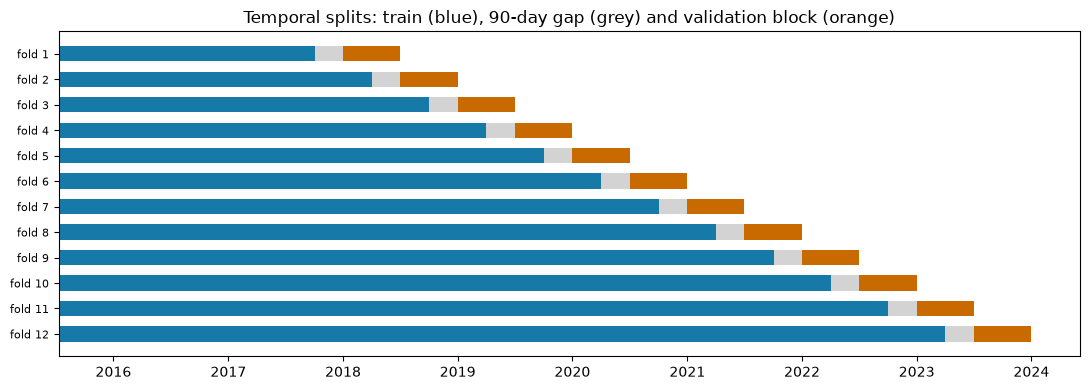

In [71]:
# picture of the 12 splits
first_day = dev["purchase_date"].min()
fig, ax = plt.subplots(figsize=(11, 4))
for i, start in enumerate(block_starts):
    gap_start = start - pd.Timedelta(days=90)
    end = start + pd.DateOffset(months=6)
    ax.barh(i, (gap_start - first_day).days, left=0, color="#1779A8", height=0.6)
    ax.barh(i, 90, left=(gap_start - first_day).days, color="lightgrey", height=0.6)
    ax.barh(i, (end - start).days, left=(start - first_day).days, color="#C96A00", height=0.6)
years = pd.date_range("2016-01-01", "2024-01-01", freq="YS")
ax.set_xticks([(y - first_day).days for y in years])
ax.set_xticklabels([y.year for y in years])
ax.set_yticks(range(len(block_starts)))
ax.set_yticklabels([f"fold {i + 1}" for i in range(len(block_starts))], fontsize=8)
ax.invert_yaxis()
ax.set_title("Temporal splits: train (blue), 90-day gap (grey) and validation block (orange)")
plt.tight_layout()
plt.show()

The procedure creates 12 splits. Training sets grow from 1,186 to 5,077 purchases, while validation blocks contain between 232 and 467 purchases. Validation repeat-purchase rates range from 0.437 to 0.607, showing that the periods differ in their target distribution. Every preprocessing option is evaluated on these same splits.

#### 12.3. Baseline Model and Evaluation Metric

We use **logistic regression** to compare preprocessing options. It is relatively fast to train and responds to changes in feature scale, transformations, and categorical encoding. Its purpose here is to evaluate preprocessing choices; model selection is a separate step.

The following functions define the comparison procedure:

- `make_preprocessor` builds the transformations for numeric, categorical, and binary features. Each experiment changes a specific part of this configuration.
- `temporal_scores` fits the full pipeline on each training set and returns one validation score per split.
- `compare` reports the mean score and the paired differences against a reference option. It also calculates the standard error of those differences (SEM).

The comparison labels a difference within two SEM as `inside the noise`. We use this as a descriptive rule for identifying small differences, rather than as a formal significance test. The training sets overlap, so the fold scores are not independent and the SEM may understate uncertainty.

In [72]:
def signed_log(X):
    """log1p that keeps the sign. For values >= 0 it is the same as log1p, and it also works
    on the negative impossible values of the option "keep as is" (13.4)."""
    return np.sign(X) * np.log1p(np.abs(X))


class Winsorizer(BaseEstimator, TransformerMixin):
    """Clips each column to its 1% and 99% quantiles, learned on the train rows."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, 0.01, axis=0)
        self.high_ = np.nanquantile(X, 0.99, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


def make_preprocessor(log_cols, plain_cols, cat_cols, flag_cols=(), num_fill="median", indicators=False,
                      cat_fill="Missing", outliers="log1p", encoder="onehot", min_frequency=None, scaler="standard"):
    """Layer B: the steps that learn something from the data (medians, levels, scales).
    Inside a Pipeline they are fitted only on the train rows of each split."""
    scalers = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}

    def numeric_steps(long_tail):
        if num_fill == "zero":
            steps = [("impute", SimpleImputer(strategy="constant", fill_value=0, add_indicator=indicators))]
        else:
            steps = [("impute", SimpleImputer(strategy=num_fill, add_indicator=indicators))]
        if long_tail and outliers == "log1p":
            steps.append(("log", FunctionTransformer(signed_log)))
        elif long_tail and outliers == "winsorize":
            steps.append(("winsorize", Winsorizer()))
        if scaler in scalers:
            steps.append(("scale", scalers[scaler]()))
        return Pipeline(steps)

    # categories: missing -> "Missing" (or the most frequent level), then encoding
    if cat_fill == "Missing":
        cat_steps = [("impute", SimpleImputer(strategy="constant", fill_value="Missing"))]
    else:
        cat_steps = [("impute", SimpleImputer(strategy="most_frequent"))]
    if encoder == "onehot" and min_frequency is None:
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    elif encoder == "onehot":
        cat_steps.append(("encode", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency,
                                                  sparse_output=False)))
    else:
        cat_steps.append(("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)))
        if scaler in scalers:
            cat_steps.append(("scale", scalers[scaler]()))

    parts = [("log", numeric_steps(long_tail=True), list(log_cols)),       # money, counts and days (long tails)
             ("plain", numeric_steps(long_tail=False), list(plain_cols)),  # columns that can be negative, or ratios
             ("cat", Pipeline(cat_steps), list(cat_cols)),
             ("flags", "passthrough", list(flag_cols))]                    # 0/1 columns
    return ColumnTransformer([p for p in parts if len(p[2]) > 0])

In [73]:
def temporal_scores(frame, columns, recipe, row_filter=None, metric="ap"):
    """One score per fold: the instrument is fitted on the train rows and scored on the validation block."""
    used = columns["log_cols"] + columns["plain_cols"] + columns["cat_cols"] + columns["flag_cols"]
    scores = []
    for train_idx, val_idx in folds:
        train, val = frame.loc[train_idx], frame.loc[val_idx]
        if row_filter is not None:
            train = row_filter(train)   # rows are only removed from the train side, never from validation
        pipe = Pipeline([("prep", make_preprocessor(**columns, **recipe)),
                         ("model", LogisticRegression(max_iter=3000))])
        pipe.fit(train[used], train[target_col])
        prob = pipe.predict_proba(val[used])[:, 1]
        if metric == "ap":
            scores.append(average_precision_score(val[target_col], prob))
        elif metric == "f1":
            scores.append(f1_score(val[target_col], prob >= 0.5))
        else:
            scores.append((prob >= 0.5).mean())   # share of rows predicted as 1
    return np.array(scores)


def compare(results, reference):
    """Mean AP of each option and its difference to the reference, fold by fold (paired)."""
    rows = {}
    for name, scores in results.items():
        diff = scores - results[reference]
        sem = diff.std(ddof=1) / np.sqrt(len(diff))
        if name == reference:
            verdict = "reference"
        elif abs(diff.mean()) <= 2 * sem:
            verdict = "inside the noise"
        else:
            verdict = "better" if diff.mean() > 0 else "worse"
        rows[name] = {"AP": round(scores.mean(), 4), "difference": round(diff.mean(), 4), "SEM": round(sem, 4),
                      "better in": f"{(diff > 0).sum()}/{len(diff)}", "verdict": verdict}
    return pd.DataFrame(rows).T

The initial model uses the numeric and categorical purchase features. `ID` and `customer_id` are excluded as predictors: the former identifies rows, and the latter is used to join customer information. `purchase_date` defines the temporal splits.

The competition metric is F1 for class 1. However, F1 depends on the classification threshold, which has not yet been tuned. We therefore compare F1 at the default threshold of 0.5 with the baseline of always predicting class 1, and also calculate **average precision (AP)** to assess the ranking of purchases independently of a single threshold.

In [74]:
# columns of the instrument at the start (clientes.csv and the new features come in sections 19 and 20)
# not used as variables: ID (index, section 10), customer_id (only the key for clientes.csv, section 10)
# and purchase_date (only used to build the temporal splits, section 5)
numeric_cols = (var_groups["Current transaction (financial)"] + var_groups["Current transaction (operational)"]
                + var_groups["Customer historical summary"] + var_groups["Customer cadence & gaps"]
                + var_groups["Rolling windows (RFM)"])
cat_cols = ["payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse", "document_series"]
columns = {"log_cols": numeric_cols, "plain_cols": ["random_noise"], "cat_cols": cat_cols, "flag_cols": []}

# the starting recipe: usual defaults. Each section below tests one of these choices.
recipe = {"num_fill": "median", "indicators": False, "cat_fill": "Missing", "outliers": "log1p",
          "encoder": "onehot", "min_frequency": None, "scaler": "standard"}

# first version of the data: the impossible values of 3.6 only set to missing (section 13 decides properly)
df_start = df_base.copy()
for col in ["prior_mean_purchase_value", "spend_365d"]:
    df_start.loc[(df_start[col] < 0) | (df_start[col] >= 1e8), col] = np.nan
for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    df_start.loc[df_start[col] < 0, col] = np.nan

f1_05 = temporal_scores(df_start, columns, recipe, metric="f1")
share_1 = temporal_scores(df_start, columns, recipe, metric="share")
ap_start = temporal_scores(df_start, columns, recipe)
rate = np.array([dev.loc[v, target_col].mean() for t, v in folds])
pd.DataFrame({"repeat rate": rate, "predicted as 1 (at 0.5)": share_1, "F1 always 1": 2 * rate / (1 + rate),
              "F1 at 0.5": f1_05, "AP": ap_start}, index=[f"fold {i + 1}" for i in range(12)]).T.round(3)

,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,fold 10,fold 11,fold 12
repeat rate,0.534,0.540,0.517,0.524,0.577,0.607,0.581,0.527,0.539,0.437,0.563,0.596
predicted as 1 (at 0.5),0.702,0.519,0.616,0.505,0.567,0.576,0.473,0.422,0.669,0.421,0.469,0.528
F1 always 1,0.696,0.701,0.682,0.688,0.732,0.756,0.735,0.690,0.700,0.609,0.720,0.747
F1 at 0.5,0.737,0.713,0.776,0.751,0.699,0.749,0.723,0.722,0.757,0.656,0.705,0.752
AP,0.850,0.803,0.864,0.859,0.792,0.838,0.851,0.852,0.849,0.747,0.844,0.879


In [75]:
print(f"F1 of always predicting 1: {(2 * rate / (1 + rate)).mean():.3f}")
print(f"F1 of the model at 0.5:    {f1_05.mean():.3f} (above always 1 in {(f1_05 > 2 * rate / (1 + rate)).sum()} of 12 folds)")
print(f"AP of always predicting 1: {rate.mean():.3f} (the AP of a model with no information is the repeat rate)")
print(f"AP of the model:           {ap_start.mean():.3f}")

F1 of always predicting 1: 0.705
F1 of the model at 0.5:    0.728 (above always 1 in 8 of 12 folds)
AP of always predicting 1: 0.545 (the AP of a model with no information is the repeat rate)
AP of the model:           0.836


At a threshold of 0.5, logistic regression achieves a mean F1 of 0.728, compared with 0.705 for always predicting class 1. It exceeds this baseline in 8 of the 12 folds. The proportion predicted as class 1 varies from about 42% to 70%, so differences in F1 also reflect how the fixed threshold behaves across periods.

We use **average precision (AP)** for the preprocessing comparisons. AP summarises precision across recall levels without selecting a single classification threshold. The model achieves a mean AP of 0.836, compared with 0.545 for constant predictions, where AP equals the positive-class proportion in each fold. F1 and threshold tuning are left for the modelling stage.

### 13. Invalid Values and Value Recovery

Some values violate the relationships expected between purchase-history variables, including negative time gaps, implausibly large amounts, and inconsistent purchase summaries. We first replace these values with missing entries, then recover values that can be calculated from other columns. We compare this approach with leaving the data unchanged or removing affected training rows.

#### 13.1. Correction and Recovery Functions

`blank_impossible` replaces values that fail the consistency checks with missing entries. `recover_values` then reconstructs values using relationships between totals, counts, purchase amounts, and time gaps.

These are Layer A operations: they use values from the same row and do not estimate parameters from other purchases. The same functions can therefore be applied to training and test data.

In [76]:
def blank_impossible(frame):
    """Impossible values of 3.6 -> missing. It works row by row, so it learns nothing from the other rows."""
    out = frame.copy()
    count = out["prior_purchase_count"]
    # 3.6.1 to 3.6.3: 1e9, negative values, means bigger than the biggest purchase, spend_365d bigger than the prior spend
    mean = out["prior_mean_purchase_value"]
    out.loc[(mean < 0) | (mean >= 1e8) | (mean > out["prior_max_purchase_value"] + 0.01), "prior_mean_purchase_value"] = np.nan
    spend = out["spend_365d"]
    out.loc[(spend < 0) | (spend >= 1e8) | (spend > out["prior_total_spend"] + 0.01), "spend_365d"] = np.nan
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        out.loc[out[col] < 0, col] = np.nan
    # 3.6.6: biggest purchase above its limit
    max_limit = out["prior_total_spend"] - (count - 1) * out["prior_min_purchase_value"]
    out.loc[(count >= 1) & (out["prior_max_purchase_value"] > max_limit + 0.01), "prior_max_purchase_value"] = np.nan
    return out




# recover_values is the function of 3.6.7
df_blank = blank_impossible(df_base)
df_recovered = recover_values(df_blank)
changed = pd.DataFrame({"missing in the file": df_base[numeric_cols].isna().sum(),
                        "after blanking the impossible values": df_blank[numeric_cols].isna().sum(),
                        "after recovering": df_recovered[numeric_cols].isna().sum()})
print(f"Cells set to missing: {(changed.iloc[:, 1] - changed.iloc[:, 0]).sum()} | Cells recovered: {(changed.iloc[:, 1] - changed.iloc[:, 2]).sum()}")
print(f"Missing cells | in the file: {changed.iloc[:, 0].sum():,} | after the two functions: {changed.iloc[:, 2].sum():,}")
changed[changed.iloc[:, 1] != changed.iloc[:, 2]]

Cells set to missing: 224 | Cells recovered: 787
Missing cells | in the file: 6,698 | after the two functions: 6,135


,missing in the file,after blanking the impossible values,after recovering
prior_mean_purchase_value,797,874,603
prior_max_purchase_value,603,649,645
days_since_previous_purchase,796,812,611
prior_mean_gap_days,1243,1259,1056
spend_365d,195,264,156


The consistency checks introduce 224 missing entries, and the recovery rules fill 787 entries. Together, these steps reduce the number of missing numeric values from 6,698 to 6,135. `prior_mean_purchase_value` remains missing only for purchases with no prior history, while missing entries in `spend_365d` decrease from 264 to 156.

#### 13.2. Comparing Treatments for Invalid Values

We compare four treatments: retain the original values, replace invalid values with missing entries, replace and recover values, or remove affected rows from training.

Row removal applies only to the training side of each split. Validation rows are retained so that all options are evaluated on the same purchases, including cases that still require a prediction despite data-quality problems.

In [77]:
# rows with at least one impossible value (for the arm "drop the row")
had_impossible = (df_blank[numeric_cols].isna() & df_base[numeric_cols].notna()).any(axis=1)
print(f"Rows with at least one impossible value: {had_impossible.sum()}")

results = {
    "keep as is": temporal_scores(df_base, columns, recipe),
    "set to missing": temporal_scores(df_blank, columns, recipe),
    "set to missing + recover": temporal_scores(df_recovered, columns, recipe),
    "drop the row": temporal_scores(df_blank, columns, recipe, row_filter=lambda t: t[~had_impossible[t.index]]),
}
compare(results, "set to missing")

Rows with at least one impossible value: 223


,AP,difference,SEM,better in,verdict
keep as is,0.8358,-0.0005,0.0006,6/12,inside the noise
set to missing,0.8363,0.0,0.0,0/12,reference
set to missing + recover,0.8368,0.0005,0.0004,7/12,inside the noise
drop the row,0.8357,-0.0006,0.0008,6/12,inside the noise


The four treatments do not show a clear difference under the comparison rule. Invalid values affect 223 of the 6,469 purchases, and the logarithmic transformation also reduces the magnitude of very large values.

We choose **replacement with missing values followed by recovery**. This avoids retaining known inconsistencies and preserves purchases whose other fields remain useful. Recovery uses the available relationships between columns instead of a general imputation value. This option also has the highest mean AP in the comparison. Remaining missing values are handled by the imputer.

#### 13.3. Zero Purchase Costs

A value of zero in `Custo` is not automatically invalid. We compare keeping these values with treating them as missing, both with and without a binary indicator identifying the affected purchases.

In [78]:
# the purchases with a cost of 0 (3.6.8)
zero_cost = df_base["Custo"] == 0

df_cost = df_recovered.assign(zero_cost=zero_cost.astype(int))
df_cost_missing = df_cost.assign(Custo=df_cost["Custo"].mask(zero_cost))
results = {
    "keep the 0": temporal_scores(df_cost, columns, recipe),
    "0 as missing": temporal_scores(df_cost_missing, columns, recipe),
    "0 as missing + flag": temporal_scores(df_cost_missing, {**columns, "flag_cols": ["zero_cost"]}, recipe),
}
compare(results, "keep the 0")

,AP,difference,SEM,better in,verdict
keep the 0,0.8368,0.0,0.0,0/12,reference
0 as missing,0.8365,-0.0004,0.0003,4/12,inside the noise
0 as missing + flag,0.8368,-0.0,0.0003,5/12,inside the noise


Replacing zero costs with missing values does not produce a clear improvement, with or without an indicator. We therefore **retain zero costs**. A zero may represent a valid recorded amount, and the validation results do not provide a reason to replace it. The margin feature also reflects the relationship between recorded cost and invoice value.

In [79]:
# decision of section 13
df_prep = df_recovered.copy()

### 14. Purchases Included in Training

Customer records suggest that some customers registered in 2015 may have entered the system without their earlier purchase history. Their recorded tenure and purchase counts may therefore understate their actual history.

We compare keeping these purchases, excluding them from training, and keeping them with an `is_2015` indicator. Validation starts in 2018, so the indicator is always zero in validation. It can only help the model account for differences associated with 2015 during training.

In [80]:
is_2015 = (df_prep["purchase_date"].dt.year == 2015).astype(int)
print(f"Purchases of 2015: {is_2015.sum()} (train rows of every fold, never validation rows)")
print(f"Share of 2015 in the train rows | fold 1: {is_2015[folds[0][0]].mean():.0%} | fold 12: {is_2015[folds[-1][0]].mean():.0%}")

results = {
    "keep 2015": temporal_scores(df_prep, columns, recipe),
    "drop 2015 from the train rows": temporal_scores(df_prep, columns, recipe,
                                                     row_filter=lambda t: t[t["purchase_date"].dt.year > 2015]),
    "keep 2015 + flag for 2015": temporal_scores(df_prep.assign(is_2015=is_2015),
                                                 {**columns, "flag_cols": ["is_2015"]}, recipe),
}
compare(results, "keep 2015")

Purchases of 2015: 335 (train rows of every fold, never validation rows)
Share of 2015 in the train rows | fold 1: 28% | fold 12: 7%


,AP,difference,SEM,better in,verdict
keep 2015,0.8368,0.0,0.0,0/12,reference
drop 2015 from the train rows,0.8369,0.0,0.0011,7/12,inside the noise
keep 2015 + flag for 2015,0.8368,0.0,0.0004,7/12,inside the noise


The alternatives have the same mean AP as retaining 2015 purchases at the precision displayed in the table. These purchases represent 28% of the first training set and 7% of the last, so their relative contribution decreases as more recent data becomes available.

We **keep the 2015 purchases without an additional indicator**. Neither removing them nor adding a feature shows a measurable benefit in this comparison.

### 15. Missing Values

After correction and recovery, some values remain missing because they cannot be reconstructed from the available columns. We count these entries by the number of prior purchases to distinguish missing history from missing information that would otherwise be expected.

In [81]:
left = df_prep[numeric_cols + cat_cols].isna().sum()
left = left[left > 0]
prior_n = df_prep["prior_purchase_count"]
missing = pd.DataFrame({
    "missing": left,
    "first purchase": df_prep.loc[prior_n == 0, left.index].isna().sum(),
    "1 prior purchase": df_prep.loc[prior_n == 1, left.index].isna().sum(),
    "2 prior purchases": df_prep.loc[prior_n == 2, left.index].isna().sum(),
    "3 or more": df_prep.loc[prior_n >= 3, left.index].isna().sum(),
})
missing

,missing,first purchase,1 prior purchase,2 prior purchases,3 or more
prior_mean_purchase_value,603,603,0,0,0
prior_std_purchase_value,1048,603,445,0,0
prior_min_purchase_value,603,603,0,0,0
prior_max_purchase_value,645,603,0,0,42
days_since_previous_purchase,611,603,0,2,6
prior_mean_gap_days,1056,603,445,2,6
prior_std_gap_days,1413,603,445,365,0
spend_365d,156,0,0,0,156
payment_type,195,19,6,11,159
salesperson,194,25,18,11,140


Most missing numeric values are linked to the amount of purchase history available:

- The 603 first purchases have no earlier purchase history, so their historical summaries are unavailable.
- With one prior purchase, purchase-value variability and gaps between prior purchases are undefined (445 rows). With two prior purchases, there is only one historical gap, so its standard deviation is undefined (365 rows).
- Other missing entries include 42 unrecovered maximum purchase values, 156 values of `spend_365d`, and eight rows where both `days_since_previous_purchase` and `prior_mean_gap_days` are missing. Neither time variable can be recovered when both are unavailable.
- Context variables such as `payment_type`, `salesperson`, `transport_method`, and `warehouse` are missing in roughly 195 rows each, across different history groups.

We compare median, mean, and zero imputation for numeric features. We also test missing-value indicators, a single `is_first_purchase` flag, and the most frequent category as an alternative to a separate `Missing` category. All fitted imputation values come from the training rows of each split.

In [82]:
# the flag of 3.3 and 7.3, built row by row
df_prep["is_first_purchase"] = (df_prep["prior_purchase_count"] == 0).astype(int)

results = {
    "median": temporal_scores(df_prep, columns, recipe),
    "mean": temporal_scores(df_prep, columns, {**recipe, "num_fill": "mean"}),
    "zero": temporal_scores(df_prep, columns, {**recipe, "num_fill": "zero"}),
    "median + missing indicators": temporal_scores(df_prep, columns, {**recipe, "indicators": True}),
    "median + is_first_purchase": temporal_scores(df_prep, {**columns, "flag_cols": ["is_first_purchase"]}, recipe),
    "categories: most frequent level": temporal_scores(df_prep, columns, {**recipe, "cat_fill": "most_frequent"}),
}
compare(results, "median")

,AP,difference,SEM,better in,verdict
median,0.8368,0.0,0.0,0/12,reference
mean,0.8363,-0.0005,0.0003,4/12,inside the noise
zero,0.8371,0.0002,0.0008,7/12,inside the noise
median + missing indicators,0.8362,-0.0006,0.0005,5/12,inside the noise
median + is_first_purchase,0.837,0.0002,0.0001,8/12,inside the noise
categories: most frequent level,0.8367,-0.0001,0.0006,6/12,inside the noise


None of the alternatives shows a clear difference under the comparison rule. We choose the following treatment:

- **Median imputation for numeric features.** It is less sensitive to long tails than the mean. Filling with zero would give some missing values a misleading interpretation, such as no elapsed time since a previous purchase.
- **No general missing-value indicators.** These add eight columns without a clear validation benefit.
- **Include `is_first_purchase`.** This single flag identifies the main reason for missing purchase history and gives a slightly higher mean AP.
- **Use a `Missing` category.** This preserves the distinction between unavailable information and the most common observed category. For `island`, an empty value is interpreted as no island designation in the customer data.

In [83]:
# decision of section 15
columns = {**columns, "flag_cols": ["is_first_purchase"]}

### 16. Outliers and Skewed Distributions

Large purchase amounts and high activity counts may describe valuable customers rather than data errors. We compare four treatments: keep the original values, apply `log1p`, clip values at the training-set 1st and 99th percentiles, or remove training rows outside the 1.5 x IQR limits in any numeric purchase feature.

Clipping thresholds and IQR limits are calculated separately from the training rows of each split. Validation rows are always retained.

In [84]:
def drop_iqr_outliers(train):
    """Removes the train rows outside the 1.5 x IQR limits in any numeric column (a missing value counts as inside)."""
    values = train[numeric_cols]
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    inside = values.ge(q1 - 1.5 * (q3 - q1)) & values.le(q3 + 1.5 * (q3 - q1))
    return train.loc[(inside | values.isna()).all(axis=1)]

results = {
    "keep the values": temporal_scores(df_prep, columns, {**recipe, "outliers": "none"}),
    "log1p": temporal_scores(df_prep, columns, recipe),
    "winsorize 1% / 99%": temporal_scores(df_prep, columns, {**recipe, "outliers": "winsorize"}),
    "drop the rows (1.5 x IQR)": temporal_scores(df_prep, columns, {**recipe, "outliers": "none"}, row_filter=drop_iqr_outliers),
}
compare(results, "keep the values")

,AP,difference,SEM,better in,verdict
keep the values,0.8339,0.0,0.0,0/12,reference
log1p,0.837,0.0031,0.0025,7/12,inside the noise
winsorize 1% / 99%,0.8354,0.0015,0.0017,7/12,inside the noise
drop the rows (1.5 x IQR),0.7932,-0.0408,0.0069,0/12,worse


In [85]:
# what the IQR rule removes from the biggest train set (fold 12)
last_train = df_prep.loc[folds[-1][0]]
kept = drop_iqr_outliers(last_train)
removed = last_train.drop(kept.index)
print(f"Train rows kept by the IQR rule: {len(kept):,} of {len(last_train):,} ({len(kept) / len(last_train):.0%})")
print(f"Repeat rate | removed rows: {removed[target_col].mean():.2f} | kept rows: {kept[target_col].mean():.2f}")

Train rows kept by the IQR rule: 1,706 of 5,077 (34%)
Repeat rate | removed rows: 0.60 | kept rows: 0.45


Removing outlier rows reduces mean AP by 0.0408 and performs worse in all 12 folds. In the last training set, the IQR rule retains only 34% of purchases. The removed rows have a higher repeat-purchase rate than the retained rows (0.60 versus 0.45), so this treatment removes many relevant examples.

The other three treatments do not show a clear difference. We choose **`log1p`**, which has the highest mean AP and performs better than retaining the original values in 7 of 12 folds. It compresses long tails while retaining the observations and their ordering. Percentile clipping would instead make the largest values indistinguishable above the cutoff.

Monotonic transformations preserve feature ordering, so they generally preserve the possible threshold partitions for decision trees. Their effect on other model types still needs to be assessed during modelling.

### 17. Categorical Encoding

Categorical variables must be converted to numeric features for logistic regression. We compare one-hot encoding of all categories, one-hot encoding that groups categories with fewer than 10 or 30 training observations, and ordinal encoding.

Rare-category grouping is learned separately in each training set. This is especially relevant for `transport_method`, which contains many infrequent values.

Target encoding is not included in this comparison. It would require an additional training procedure, such as out-of-fold encoding, to avoid using a row's target in its own encoded value.

In [86]:
options = {
    "one-hot, all levels": {},
    "one-hot, levels with < 10 rows grouped": {"min_frequency": 10},
    "one-hot, levels with < 30 rows grouped": {"min_frequency": 30},
    "ordinal": {"encoder": "ordinal"},
}
results = {name: temporal_scores(df_prep, columns, {**recipe, **change}) for name, change in options.items()}
board = compare(results, "one-hot, all levels")

# columns created from the 6 categorical variables in the biggest train set (fold 12)
last_train = df_prep.loc[folds[-1][0], cat_cols]
board["columns created"] = [make_preprocessor([], [], cat_cols, **{**recipe, **change}).fit_transform(last_train).shape[1]
                            for change in options.values()]
board

,AP,difference,SEM,better in,verdict,columns created
"one-hot, all levels",0.837,0.0,0.0,0/12,reference,105
"one-hot, levels with < 10 rows grouped",0.8346,-0.0024,0.0013,3/12,inside the noise,62
"one-hot, levels with < 30 rows grouped",0.8342,-0.0027,0.0021,4/12,inside the noise,52
ordinal,0.8354,-0.0016,0.0017,4/12,inside the noise,6


In [87]:
# the rare levels of transport_method in the biggest train set: how many clients use each one?
train_12 = df_prep.loc[folds[-1][0]]
counts = train_12["transport_method"].value_counts()
rare = counts[counts < 10].index
clients = train_12[train_12["transport_method"].isin(rare)].groupby("transport_method")["customer_id"].nunique()
print(f"transport_method: {len(counts)} levels | {len(rare)} with fewer than 10 rows | {(clients == 1).sum()} of these used by only one client")

transport_method: 75 levels | 41 with fewer than 10 rows | 35 of these used by only one client


Ordinal encoding does not improve the results and introduces an arbitrary ordering between nominal categories. Grouping rare categories gives a slightly lower mean AP than retaining all categories, but the difference is within the comparison rule's uncertainty range.

Of the 41 `transport_method` categories with fewer than 10 observations in the last training set, 35 are associated with only one customer. These categories may partly act as customer identifiers. This is a possible explanation for the small advantage of retaining them, although the comparison does not establish its cause.

We choose **one-hot encoding with categories below 10 training observations grouped together**. This reduces the encoded columns from 105 to 62 and limits reliance on very sparse categories. The threshold of 10 retains more detail than 30. Unseen categories are assigned to the infrequent group when that group exists in the fitted encoder.

In [88]:
# decision of section 17
recipe = {**recipe, "min_frequency": 10}

### 18. Feature Scaling

Scaling places numeric features on comparable scales. This matters for regularised logistic regression because feature scale affects the penalty on coefficients. It is also relevant to distance-based models and neural networks.

We compare no scaling, `StandardScaler`, `MinMaxScaler`, and `RobustScaler`. Only numeric features are scaled; one-hot columns and binary flags retain their 0/1 representation. Each scaler is fitted using the training rows only.

In [89]:
used = columns["log_cols"] + columns["plain_cols"] + columns["cat_cols"] + columns["flag_cols"]
results, iterations = {}, {}
for scaler in ["none", "standard", "minmax", "robust"]:
    results[scaler] = temporal_scores(df_prep, columns, {**recipe, "scaler": scaler})
    # iterations of the solver on the biggest train set (the limit is 3000)
    pipe = Pipeline([("prep", make_preprocessor(**columns, **{**recipe, "scaler": scaler})),
                     ("model", LogisticRegression(max_iter=3000))])
    pipe.fit(df_prep.loc[folds[-1][0], used], df_prep.loc[folds[-1][0], target_col])
    iterations[scaler] = pipe.named_steps["model"].n_iter_[0]
board = compare(results, "none")
board["solver iterations (fold 12)"] = pd.Series(iterations)
board

,AP,difference,SEM,better in,verdict,solver iterations (fold 12)
none,0.8344,0.0,0.0,0/12,reference,668
standard,0.8346,0.0001,0.0003,8/12,inside the noise,116
minmax,0.8349,0.0004,0.001,6/12,inside the noise,48
robust,0.8346,0.0002,0.0003,7/12,inside the noise,99


Mean AP varies little across the options, ranging from 0.8344 to 0.8349, with no clear difference under the comparison rule. Scaling does reduce the solver's iteration count: the last fold requires about 670 iterations without scaling, compared with 48 to 116 with scaling.

We also check for zero-IQR columns because these affect how `RobustScaler` handles the numeric features.

In [90]:
# after log1p, columns where the IQR of the train rows is 0 (fold 12): RobustScaler can not scale them
X_log = signed_log(df_prep.loc[folds[-1][0], columns["log_cols"]])
iqr = X_log.quantile(0.75) - X_log.quantile(0.25)
print(f"Columns with IQR = 0: {list(iqr[iqr == 0].index)}")

Columns with IQR = 0: ['Total Portes', 'Total Desc_ Global', 'invoice_count_current_purchase']


Three log-transformed features have zero IQR in the last training set: `Total Portes`, `Total Desc_ Global`, and `invoice_count_current_purchase`. Their middle 50% of values are identical. For these columns, `RobustScaler` uses a scale factor of one rather than dividing by zero, although centring may still change the values.

`MinMaxScaler` depends on the observed training minimum and maximum, so future observations can fall outside its fitted range. `StandardScaler` centres features using the training mean and scales them using the training standard deviation.

We choose **`StandardScaler`**. It improves convergence relative to no scaling and provides a consistent default, with no clear AP disadvantage compared with the other scalers.

In [91]:
# decision of section 18
recipe = {**recipe, "scaler": "standard"}
recipe

{'num_fill': 'median',
 'indicators': False,
 'cat_fill': 'Missing',
 'outliers': 'log1p',
 'encoder': 'onehot',
 'min_frequency': 10,
 'scaler': 'standard'}

### 19. Integrating Customer Information

We join `clientes.csv` to purchases using `customer_id`. A left join preserves the purchase rows, while `validate="many_to_one"` checks that the customer table contains at most one matching record per customer.

The candidate predictors are `country_or_region`, `commercial_region`, and `island`, together with an `incomplete_address` flag. We also load `municipality`, `postal_area`, and `customer_since_year` to construct the flag or compare alternative features.

The join does not estimate parameters from the purchase rows. Its use assumes that the selected customer attributes are available when predictions are made; the join itself does not verify their historical availability.

In [92]:
client_cols = ["country_or_region", "commercial_region", "island", "municipality", "postal_area", "customer_since_year"]
rows_before = len(df_prep)
df_prep = df_prep.join(df_clientes.set_index("customer_id")[client_cols], on="customer_id", validate="many_to_one")
assert len(df_prep) == rows_before   # the left join did not create or lose rows
print(f"Rows before and after the join: {rows_before:,} -> {len(df_prep):,}")
print(f"Purchases without a client in clientes.csv: {df_prep['country_or_region'].isna().sum()}")

# the flag of section 9: no municipality and no postal area
df_prep["incomplete_address"] = (df_prep["municipality"].isna() & df_prep["postal_area"].isna()).astype(int)
print(f"Purchases of clients with an incomplete address: {df_prep['incomplete_address'].sum()}")

Rows before and after the join: 6,469 -> 6,469
Purchases without a client in clientes.csv: 0
Purchases of clients with an incomplete address: 213


The join preserves all 6,469 purchases. The matching check reports no purchases without customer information, and 213 purchases belong to customers missing both municipality and postal area.

We compare the geographic features alone and with the address flag. We also test municipality and customer registration year as alternative additions.

In [93]:
geo = ["country_or_region", "commercial_region", "island"]
results = {
    "without clientes.csv": temporal_scores(df_prep, columns, recipe),
    "+ country, region and island": temporal_scores(df_prep, {**columns, "cat_cols": cat_cols + geo}, recipe),
    "+ geography + incomplete_address": temporal_scores(df_prep, {**columns, "cat_cols": cat_cols + geo,
                                                                  "flag_cols": columns["flag_cols"] + ["incomplete_address"]}, recipe),
    "+ geography + municipality": temporal_scores(df_prep, {**columns, "cat_cols": cat_cols + geo + ["municipality"]}, recipe),
    "+ customer_since_year": temporal_scores(df_prep, {**columns, "plain_cols": columns["plain_cols"] + ["customer_since_year"]}, recipe),
}
compare(results, "without clientes.csv")

,AP,difference,SEM,better in,verdict
without clientes.csv,0.8346,0.0,0.0,0/12,reference
"+ country, region and island",0.8338,-0.0008,0.001,6/12,inside the noise
+ geography + incomplete_address,0.8337,-0.0009,0.001,7/12,inside the noise
+ geography + municipality,0.8325,-0.002,0.0019,5/12,inside the noise
+ customer_since_year,0.8351,0.0005,0.0011,7/12,inside the noise


None of the tested customer-feature additions produces a clear AP improvement. Adding municipality gives the lowest mean score. The results suggest limited additional benefit for this logistic regression baseline, but do not establish that these attributes are uninformative for every model.

We retain **the three geographic features and `incomplete_address` as candidates** for feature selection. Municipality is excluded because its detailed categories may identify individual customers. Customer registration year is also excluded: it is strongly associated with `customer_tenure_days` (correlation of 0.92), and the concentration of registrations in 2015 may reflect the system's initial data import.

In [94]:
# decision of section 19
cat_cols = cat_cols + geo
columns = {**columns, "cat_cols": cat_cols, "flag_cols": columns["flag_cols"] + ["incomplete_address"]}

### 20. Feature Engineering

We create nine candidate features to represent recent activity, purchasing pace, invoice composition, and deviations from a customer's usual purchase value. Each feature is calculated from columns in the same purchase row:

- `bought_in_90d`: whether at least one prior purchase occurred in the last 90 days.
- `rhythm_ratio`: days since the previous purchase divided by the mean historical gap.
- `purchase_rate`: prior purchase count divided by tenure in months plus one.
- `spend_per_month`: prior spending divided by tenure in months plus one.
- `avg_basket_365d`: spending divided by purchase count over the last 365 days.
- `spend_acceleration`: 30-day spending divided by 90-day spending plus one, representing the concentration of recent spending.
- `margin_ratio`: net invoice value minus cost, divided by net value plus one.
- `discount_intensity`: total line and global discounts divided by gross value plus one.
- `value_vs_habit`: current purchase value minus the historical mean, divided by the historical standard deviation.

The added constants stabilise selected denominators, so those features are adjusted ratios rather than exact rates or proportions. Where a zero denominator makes the ratio undefined, it is replaced with a missing value and handled by the imputer.

In [95]:
def add_features(frame):
    """New variables, built row by row from the columns of the same purchase."""
    out = frame.copy()
    months = out["customer_tenure_days"] / 30
    out["bought_in_90d"] = (out["purchase_count_90d"] > 0).astype(int)
    out["rhythm_ratio"] = out["days_since_previous_purchase"] / out["prior_mean_gap_days"].replace(0, np.nan)
    out["purchase_rate"] = out["prior_purchase_count"] / (months + 1)
    out["spend_per_month"] = out["prior_total_spend"] / (months + 1)
    out["avg_basket_365d"] = out["spend_365d"] / out["purchase_count_365d"].replace(0, np.nan)
    out["spend_acceleration"] = out["spend_30d"] / (out["spend_90d"] + 1)
    out["margin_ratio"] = (out["Total Liquido"] - out["Custo"]) / (out["Total Liquido"] + 1)
    out["discount_intensity"] = (out["Total Desc_ Linha"] + out["Total Desc_ Global"]) / (out["Total Bruto"] + 1)
    out["value_vs_habit"] = ((out["Total a Pagar"] - out["prior_mean_purchase_value"])
                             / out["prior_std_purchase_value"].replace(0, np.nan))
    return out

df_prep = add_features(df_prep)
new_flags = ["bought_in_90d"]
new_log = ["rhythm_ratio", "purchase_rate", "spend_per_month", "avg_basket_365d"]
new_plain = ["spend_acceleration", "margin_ratio", "discount_intensity", "value_vs_habit"]
new_cols = new_flags + new_log + new_plain

# Spearman with the target and with the closest existing column (development rows only)
dev_prep = df_prep.loc[is_dev]
closest = {c: dev_prep[numeric_cols].corrwith(dev_prep[c], method="spearman").abs() for c in new_cols}
pd.DataFrame({
    "Spearman with target": [dev_prep[c].corr(dev_prep[target_col], method="spearman") for c in new_cols],
    "missing": [dev_prep[c].isna().sum() for c in new_cols],
    "closest existing column": [closest[c].idxmax() for c in new_cols],
    "its |Spearman|": [closest[c].max() for c in new_cols],
}, index=new_cols).round(3)

,Spearman with target,missing,closest existing column,its |Spearman|
bought_in_90d,0.325,0,purchase_count_90d,0.916
rhythm_ratio,-0.053,1009,days_since_previous_purchase,0.743
purchase_rate,0.430,0,prior_mean_gap_days,0.938
spend_per_month,0.377,0,spend_365d,0.917
avg_basket_365d,0.082,917,prior_mean_purchase_value,0.923
spend_acceleration,0.186,0,spend_30d,0.967
margin_ratio,0.114,0,Custo,0.400
discount_intensity,0.213,0,Total Desc_ Linha,0.899
value_vs_habit,0.005,1002,Total Bruto,0.718


`purchase_rate` has a Spearman correlation of 0.430 with the target, while `spend_per_month` reaches 0.377. However, five of the nine candidates have an absolute Spearman correlation above 0.90 with an existing numeric feature. For example, `spend_acceleration` has a correlation of 0.967 with `spend_30d`, suggesting substantial overlap.

`rhythm_ratio` and `value_vs_habit` have weak individual associations with the target (-0.053 and 0.005). Correlation alone does not measure their contribution to a model, so we test each candidate separately. We then test the eight non-binary candidates together.

In [96]:
results = {"recipe": temporal_scores(df_prep, columns, recipe)}
for f in new_flags:
    results["+ " + f] = temporal_scores(df_prep, {**columns, "flag_cols": columns["flag_cols"] + [f]}, recipe)
for f in new_log:
    results["+ " + f] = temporal_scores(df_prep, {**columns, "log_cols": columns["log_cols"] + [f]}, recipe)
for f in new_plain:
    results["+ " + f] = temporal_scores(df_prep, {**columns, "plain_cols": columns["plain_cols"] + [f]}, recipe)
results["+ all the new features except bought_in_90d"] = temporal_scores(
    df_prep, {**columns, "log_cols": columns["log_cols"] + new_log, "plain_cols": columns["plain_cols"] + new_plain}, recipe)
compare(results, "recipe")

,AP,difference,SEM,better in,verdict
recipe,0.8337,0.0,0.0,0/12,reference
+ bought_in_90d,0.833,-0.0007,0.0006,5/12,inside the noise
+ rhythm_ratio,0.8337,0.0,0.0002,5/12,inside the noise
+ purchase_rate,0.8339,0.0002,0.0005,5/12,inside the noise
+ spend_per_month,0.8339,0.0002,0.0002,5/12,inside the noise
+ avg_basket_365d,0.8347,0.001,0.0008,8/12,inside the noise
+ spend_acceleration,0.8335,-0.0001,0.0004,7/12,inside the noise
+ margin_ratio,0.8338,0.0002,0.0004,8/12,inside the noise
+ discount_intensity,0.8335,-0.0001,0.0002,5/12,inside the noise
+ value_vs_habit,0.8336,-0.0001,0.0001,4/12,inside the noise


No tested addition shows a clear AP difference. Adding the eight non-binary features together increases mean AP by about 0.001. Many candidates reuse information already present in the original columns, which may limit their contribution to the baseline. Some ratios may still help models represent relationships that are harder to learn from separate inputs.

We retain **eight engineered features as candidates** for feature selection, with `random_noise` kept as a control. We exclude `bought_in_90d` because it is a deterministic threshold of `purchase_count_90d` and has the lowest mean AP in this comparison. Although such a flag can change a linear model's representation, it introduces no new source information.

In [97]:
# decision of section 20
columns = {**columns, "log_cols": columns["log_cols"] + new_log, "plain_cols": columns["plain_cols"] + new_plain}

### 21. Final Preprocessing Configuration

The selected steps are combined into two reusable components:

- **`prepare_data` (Layer A)** converts dates, replaces invalid values, recovers values, creates the first-purchase flag, joins customer information, and builds the address flag and engineered features.
- **`make_preprocessor(**final_columns, **final_recipe)` (Layer B)** applies median imputation, a logarithmic transformation to selected numeric features, categorical imputation, one-hot encoding with rare-category grouping, and standard scaling of numeric features.

Layer B must be fitted inside the model pipeline using training data only. Validation, holdout, and test data use the fitted transformations.

#### 21.1. Reusable Data Preparation

In [98]:
def prepare_data(frame, clientes):
    """Layer A: every step that works row by row. The same function will be used on test.csv."""
    out = frame.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"])
    out = blank_impossible(out)
    out = recover_values(out)          # 3.6.7
    out["is_first_purchase"] = (out["prior_purchase_count"] == 0).astype(int)
    out = out.join(clientes.set_index("customer_id")[["country_or_region", "commercial_region", "island",
                                                      "municipality", "postal_area"]],
                   on="customer_id", validate="many_to_one")
    out["incomplete_address"] = (out["municipality"].isna() & out["postal_area"].isna()).astype(int)
    out = add_features(out)
    return out


final_columns = columns
final_recipe = recipe
feature_cols = final_columns["log_cols"] + final_columns["plain_cols"] + final_columns["cat_cols"] + final_columns["flag_cols"]

df_model = prepare_data(df_train.loc[~empty_rows], df_clientes)
print(f"Rows: {len(df_model):,} | Candidate features: {len(feature_cols)}"
      f" ({len(final_columns['log_cols']) + len(final_columns['plain_cols'])} numeric,"
      f" {len(final_columns['cat_cols'])} categorical, {len(final_columns['flag_cols'])} flags)")
print(f"Same values as the step by step version above: {df_model[feature_cols].equals(df_prep[feature_cols])}")

# row by row: preparing 5 rows alone gives the same result as preparing them with all the others
print(f"5 rows prepared alone give the same values: {prepare_data(df_train.loc[~empty_rows].iloc[:5], df_clientes)[feature_cols].equals(df_model[feature_cols].iloc[:5])}")
pd.DataFrame([(group, len(cols), ", ".join(cols)) for group, cols in final_columns.items()],
             columns=["Group", "# vars", "Variables"])

Rows: 6,469 | Candidate features: 48 (37 numeric, 9 categorical, 2 flags)
Same values as the step by step version above: True
5 rows prepared alone give the same values: True


,Group,# vars,Variables
0,log_cols,32,"Total a Pagar, Total Bruto, Total Liquido, Tot..."
1,plain_cols,5,"random_noise, spend_acceleration, margin_ratio..."
2,cat_cols,9,"payment_type, salesperson, commercial_zone, tr..."
3,flag_cols,2,"is_first_purchase, incomplete_address"


`prepare_data` reproduces the feature values obtained by the individual preparation steps. Preparing five rows separately also gives the same values as preparing them within the full dataset, which checks the row-level behaviour for those examples.

The resulting dataset contains **48 candidate features**: 37 numeric features, nine categorical features, and two binary flags. These are the inputs to feature selection, before one-hot encoding expands the categorical columns.

#### 21.2. Comparison with the Initial Configuration

In [99]:
final = temporal_scores(df_model, final_columns, final_recipe)
compare({"starting defaults (12.3)": ap_start, "final recipe": final}, "starting defaults (12.3)")

,AP,difference,SEM,better in,verdict
starting defaults (12.3),0.8357,0.0,0.0,0/12,reference
final recipe,0.8346,-0.0011,0.0018,6/12,inside the noise


The final configuration achieves a mean AP of about 0.835, compared with 0.836 for the initial defaults. It performs better in 6 of 12 folds, and the paired difference falls within the comparison rule's uncertainty range. There is therefore no clear evidence of an overall improvement for logistic regression.

Rare-category grouping also gave a slightly lower mean AP in its individual comparison. We retain it to reduce sparse category columns, including categories associated with a single customer. The individual experiments do not establish how much each change contributes to the final score because the changes can interact.

Most tested choices have small effects on this baseline. Removing outlier rows is the clearest harmful treatment, reducing AP by 0.0408. The final configuration prioritises consistent value handling, training-only fitted transformations, and a defined set of candidate features without claiming a predictive gain that the results do not support.

#### 21.3. Checking Fitted Transformations

In [100]:
# Layer B fitted on the development rows only, then the holdout is only transformed (nothing is learned from it)
dev_rows, holdout_rows = df_model.loc[is_dev], df_model.loc[~is_dev]
preprocessor = make_preprocessor(**final_columns, **final_recipe).fit(dev_rows[feature_cols])
X_holdout = preprocessor.transform(holdout_rows[feature_cols])
print(f"Holdout matrix: {X_holdout.shape[0]} rows x {X_holdout.shape[1]} columns | missing values left: {np.isnan(X_holdout).sum()}")

# the medians used by the imputer are the ones of the development rows, not of all the rows
learned = pd.Series(preprocessor.named_transformers_["log"].named_steps["impute"].statistics_, index=final_columns["log_cols"])
check = ["days_since_previous_purchase", "prior_mean_gap_days", "prior_std_purchase_value", "spend_365d"]
pd.DataFrame({"median used by the imputer": learned[check],
              "median of the development rows": dev_rows[check].median(),
              "median of all the rows (with holdout)": df_model[check].median()}).round(2)

Holdout matrix: 835 rows x 136 columns | missing values left: 0


,median used by the imputer,median of the development rows,median of all the rows (with holdout)
days_since_previous_purchase,56.00,56.00,57.00
prior_mean_gap_days,66.56,66.56,68.36
prior_std_purchase_value,553.33,553.33,569.08
spend_365d,2138.11,2138.11,2322.07


Fitting the preprocessor on development data and transforming the holdout produces a matrix with 835 rows and 136 columns, with no remaining missing values. The displayed imputation values match the development-set medians, confirming that these statistics were learned from the intended rows.

This checks the fitted preprocessing step; it does not by itself establish that every source feature is free from leakage. Feature availability must also match the time at which a prediction is made.

`test.csv` follows the same preparation steps and uses the pipeline fitted on the designated training data. It is transformed without refitting and retains every ID. Missing inputs, including those in otherwise empty rows, are handled by the fitted imputers and categorical encoding.

#### 21.4. Summary of Decisions

| Step | Alternatives compared | Selected treatment | Reason |
|---|---|---|---|
| Empty training rows | No comparison | Remove 65 empty training rows | No purchase information; test rows must be retained |
| Validation | No comparison | 12 temporal splits, a 90-day gap, and a 2024-2025 holdout | Preserve time order and account for the target window |
| Evaluation | F1 at 0.5 and AP examined | AP for preprocessing comparisons | Assess ranking without selecting a classification threshold |
| Invalid values | Retain, replace with missing, recover, remove rows | Replace invalid values and recover where possible | Correct inconsistencies while preserving usable rows |
| Zero costs | Retain, impute, impute with a flag | Retain zero costs | Plausible recorded values; no clear gain from replacement |
| 2015 purchases | Retain, exclude, add a year flag | Retain without a flag | No measurable benefit from the alternatives |
| Missing values | Median, mean, zero, indicators, first-purchase flag, modal category | Median, `is_first_purchase`, and `Missing` category | Preserve missingness meaning with limited additional features |
| Outliers | Original values, logarithm, percentile clipping, IQR row removal | `log1p` | Retain observations and compress long tails; row removal lowers AP in all folds |
| Categorical encoding | Full one-hot, grouping below 10 or 30 observations, ordinal | One-hot with grouping below 10 training observations | Reduce sparse categories while retaining useful detail |
| Scaling | None, standard, min-max, robust | `StandardScaler` | Faster convergence with comparable AP |
| Customer attributes | Geography, address flag, municipality, registration year | Geography and address flag as candidates | Limited baseline gain; further assessment during feature selection |
| Engineered features | Nine individual candidates; eight tested together | Retain eight candidates; exclude `bought_in_90d` | No clear AP gain; exclude the redundant binary threshold feature |

`ID`, `customer_id`, and `purchase_date` are excluded as predictors. `random_noise` remains as a control for feature selection.

The outputs are `df_model`, the 48 names in `feature_cols`, and the fitted-transformation configuration defined by `final_columns` and `final_recipe`. Feature selection can use these outputs while continuing to fit preprocessing only on the training rows of each split.

## **Part 3. Feature Selection**

### **22. Feature Selection: How We Select**

From the 48 variables some are almost copies of others and some either have almost no relation with the target or are pure noise. 

So as a model with fewer variables is easier to explain and has fewer chances to learn noise, will be selected what are the best variables to stay.

The three methods used were:
* **filter methods**;
* **wrapper method**;
* **embedded methods**.

Before applying these methods the identifier-like variables will be verified, in order to not contaminate the data set and create overfitting.


In [101]:
import sklearn
from scipy.stats import spearmanr, chi2_contingency
from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.ensemble import RandomForestClassifier

# scikit-learn changed how the lasso penalty is written: l1_ratio=1.
# older versions only know penalty="l1", so we use the spelling of the installed version.
if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8):
    LASSO = {"l1_ratio": 1}
else:
    LASSO = {"penalty": "l1"}

#### **22.1. The Starting Point and the Controls**

It are used two different controls: `random_noise` for a numeric variable and  **shuffled copy** of itself (with no relation with the target) for categorical variables  and flags. A variable only stays if beats its control.

The shuffled copies are added to the train matrix of each split, and every column is scaled. This selection matrix is only read by RFE, L1 and the random forest, ensuring that the instrument never sees the copies.

In [102]:
def encoded_names(prep):
    """Names of the columns that Layer B creates, in the order of the matrix."""
    names = []
    for name, steps, cols in prep.transformers_:
        if name == "cat":
            names += list(steps.named_steps["encode"].get_feature_names_out(cols))
        elif name != "remainder":
            names += list(cols)
    return np.array(names)


def variable_of(names):
    """The variable behind each encoded column."""
    return np.array([next((c for c in final_columns["cat_cols"] if n.startswith(c + "_")), n) for n in names])


# the control of each variable: random_noise for the numeric variables and shuffled copy of itself for the categorical and flags
shuffled_vars = final_columns["cat_cols"] + final_columns["flag_cols"]
control = {v: f"shuffled {v}" if v in shuffled_vars else "random_noise" for v in feature_cols}


def selection_matrix(X_train, variable, rng):
    """The train matrix plus the shuffled copies."""
    copies = [X_train[rng.permutation(len(X_train))][:, variable == v] for v in shuffled_vars]
    names = [f"shuffled {v}" for v in shuffled_vars for _ in range((variable == v).sum())]
    return StandardScaler().fit_transform(np.hstack([X_train] + copies)), np.concatenate([variable, names])


# Layer B fitted on the train rows of each split, only once, so every method below reads the same matrices
rng = np.random.default_rng(44)
splits = []
for train_idx, val_idx in folds:
    prep = make_preprocessor(**final_columns, **final_recipe)
    X_train = prep.fit_transform(df_model.loc[train_idx, feature_cols])
    names = encoded_names(prep)
    X_select, select_variable = selection_matrix(X_train, variable_of(names), rng)
    splits.append({"train_idx": train_idx, "names": names, "variable": variable_of(names),
                   "X_train": X_train, "y_train": df_model.loc[train_idx, target_col].to_numpy(),
                   "X_val": prep.transform(df_model.loc[val_idx, feature_cols]),
                   "y_val": df_model.loc[val_idx, target_col].to_numpy(),
                   "X_select": X_select, "select_variable": select_variable})

print(f"Candidate variables: {len(feature_cols)} | Encoded columns per split: {[len(s['names']) for s in splits]}")
print(f"Columns with the shuffled copies (fold 12): {splits[-1]['X_select'].shape[1]}")

Candidate variables: 48 | Encoded columns per split: [99, 104, 108, 112, 114, 116, 121, 122, 126, 132, 135, 135]
Columns with the shuffled copies (fold 12): 233


We have 48 candidate variables in our data set. 
The number of columns grows with the train rows, from 99 in fold 1 to 135 in fold 12. With the shuffled copies, the selection matrix of fold 12 has 233 columns.

#### **22.2. How a Selection Is Measured**

To measure a selection is used the logistic regression's instrument in each split of train rows. the validation block is scored with 12 AP's for each selection and `compare` puts it next to all the candidates (paired, with the SEM). Next to the AP is shown three more numbers:
* **variables kept**: the mean of the 12 folds;
* **random_noise kept**;
* **stability**.

In [103]:
def selection_ap(kept_sets):
    """AP of the instrument in each split, with only the variables kept in that split."""
    scores = []
    for split, kept in zip(splits, kept_sets):
        cols = np.isin(split["variable"], list(kept))
        if not cols.any():   # no variable left: the model knows nothing, so its AP is the repeat rate
            scores.append(average_precision_score(split["y_val"], np.zeros(len(split["y_val"]))))
            continue
        model = LogisticRegression(max_iter=3000).fit(split["X_train"][:, cols], split["y_train"])
        scores.append(average_precision_score(split["y_val"], model.predict_proba(split["X_val"][:, cols])[:, 1]))
    return np.array(scores)

#here check stability with Jaccard similarity 
def stability(kept_sets):
    """Jaccard similarity between the sets of two folds."""
    pairs = [(a, b) for i, a in enumerate(kept_sets) for b in kept_sets[i + 1:]]
    return np.mean([len(a & b) / len(a | b) for a, b in pairs])


board, kept_by = {}, {}


def measure(name, kept_sets):
    """scores selection of a split and keeps it for the tables."""
    board[name], kept_by[name] = selection_ap(kept_sets), kept_sets


def show(names):
    """selections side by side, against all the candidates."""
    table = compare({n: board[n] for n in ["all candidates"] + names}, "all candidates")
    table["variables kept"] = [round(np.mean([len(s) for s in kept_by[n]]), 1) for n in table.index]
    table["random_noise kept"] = [f"{sum('random_noise' in s for s in kept_by[n])}/12" for n in table.index]
    table["stability"] = [round(stability(kept_by[n]), 2) for n in table.index]
    return table


measure("all candidates", [set(feature_cols)] * len(splits))
print(f"AP with all the candidates: {board['all candidates'].mean():.4f}")

AP with all the candidates: 0.8346


Through this AP with all the 48 candidates it's possible to define 0.8347 as our benchmark to the whole logistic model. In the pre-processing part it was already perceived that our model is so robust and complex that our goal is not to beat this value but to keep it while reducing the number of features selecyed.

### **23. Identifier-like Variables**

In the EDA `ID` and `customer_id` were left as identifier-like variables by principle. So now, in order to evaluate them critically, they will be tested: `ID` as a number and `customer_id` as a number and as a category (one column for each client with 10 or more train rows).

In [104]:
# define ID as a number and customer_id as a number and as a category 
df_ids = df_model.assign(row_id=df_model.index.astype(float),
                         customer_number=df_model["customer_id"].astype(float),
                         customer_level=df_model["customer_id"].astype(str))
results = {
    "all candidates": board["all candidates"],
    "+ ID as a number": temporal_scores(
        df_ids, {**final_columns, "plain_cols": final_columns["plain_cols"] + ["row_id"]}, final_recipe),
    "+ customer_id as a number": temporal_scores(
        df_ids, {**final_columns, "plain_cols": final_columns["plain_cols"] + ["customer_number"]}, final_recipe),
    "+ customer_id as a category": temporal_scores(
        df_ids, {**final_columns, "cat_cols": final_columns["cat_cols"] + ["customer_level"]}, final_recipe),
}
seen = [df_model.loc[val_idx, "customer_id"].isin(df_model.loc[train_idx, "customer_id"]).mean() for train_idx, val_idx in folds]
print(f"Validation purchases made by clients that are already in the train rows: {min(seen):.0%} to {max(seen):.0%}")
compare(results, "all candidates")

Validation purchases made by clients that are already in the train rows: 80% to 94%


,AP,difference,SEM,better in,verdict
all candidates,0.8346,0.0,0.0,0/12,reference
+ ID as a number,0.8341,-0.0005,0.0005,6/12,inside the noise
+ customer_id as a number,0.8349,0.0003,0.0004,8/12,inside the noise
+ customer_id as a category,0.8238,-0.0108,0.0056,5/12,inside the noise


Through this table we can understand that identifiers don't help the model, as previously decided in the EDA. `ID` and `customer_id` as numbers are inside the noise (with differences close to 0), meaning say nothing that the other variables do not already say. 
Moreover`customer_id` as a category loses about 0.011 of AP, at the limit of the noise (about 2 SEM), it means it has the risk of overfitting.

But a category can also work like an identifier when its levels belong to few clients, so lets check the categories that are candidates through the biggest train set (fold 12).

In [105]:
# do the categories still identify clients? check in fold 12
train_12 = df_model.loc[folds[-1][0]]
rows = []
for col in final_columns["cat_cols"]:
    level = train_12[col].fillna("Missing")
    counts = level.value_counts()
    own = counts[counts >= final_recipe["min_frequency"]].index        # levels with their own column
    clients = train_12.groupby(level)["customer_id"].nunique()
    rows.append({"variable": col, "levels": len(counts), "levels with own column": len(own),
                 "of these, used by 1 client": int((clients[own] == 1).sum()),
                 "used by fewer than 5 clients": int((clients[own] < 5).sum()),
                 "same value in all purchases of a client": f"{(train_12.groupby('customer_id')[col].nunique(dropna=False) <= 1).mean():.0%}"})
pd.DataFrame(rows).set_index("variable")

,levels,levels with own column,"of these, used by 1 client",used by fewer than 5 clients,same value in all purchases of a client
variable,,,,,
payment_type,8,6,0,0,76%
salesperson,10,8,0,0,70%
commercial_zone,5,3,0,0,99%
transport_method,76,35,1,7,49%
warehouse,3,3,0,0,80%
document_series,3,3,0,0,47%
country_or_region,7,2,0,0,100%
commercial_region,32,19,0,2,100%
island,11,10,0,0,100%


`transport_method` and `commercial_region` are important categorical variables by represent aggregate group behaviors rather than individual identities. Only a few levels of these variables are used by fewer than 5 clients (7 in`transport_method` and 2 in `commercial_region`). So the levels describe groups of clients, not single clients.

The last column shows that `country_or_region`, `commercial_region` and `island` are the same in all the purchases of a client, meaning these variables together could work as a client ID. This is one more reason for the controls of categorical variables (using shuffled copy).

### **24. Filter Methods**

The filter methods judge each variable alone with the statistics of the EDA: constant columns; relevance and redundacy. Then we put them together in one filter.

#### **24.1. Constant Columns**

In [106]:
# VarianceThreshold(0) removes the columns that never change in the train rows
constant = [int(len(s["names"]) - VarianceThreshold(0).fit(s["X_train"]).get_support().sum()) for s in splits]
print(f"Constant columns in each split: {constant}")

Constant columns in each split: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


No column is constant in any split, so `VarianceThreshold` has nothing to remove.

#### **24.2. Relevance**

For the relevance we use Spearman correlation and the flags for the numeric variables, and the chi-square test with the Cramér's V for the categories. 
Both go from 0 to 1, so all the variables can be ranked together. Each test also gives a p-value: when it is below 0.05, the relation is unlikely to be random.

In [107]:
numeric_vars = final_columns["log_cols"] + final_columns["plain_cols"] + final_columns["flag_cols"]
cat_vars = final_columns["cat_cols"]


def levels_seen(split, col):
    """level of each train row as Layer B sees rare levels grouped."""
    cols = np.flatnonzero(split["variable"] == col)
    return pd.Series(split["names"][cols][split["X_train"][:, cols].argmax(axis=1)])


def cramers_v(a, b):
    """cramer's V and the p-value of the chi-square test between two categorical columns."""
    table = pd.crosstab(a, b)
    if min(table.shape) < 2:          # only one level in these rows (no association to measure)
        return 0.0, 1.0
    chi2, p, _, _ = chi2_contingency(table, correction=False)
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))), p


def association(split):
    """Relevance of each variable with the target in the train rows, and the p-value of its test. """
    rows = df_model.loc[split["train_idx"]]
    out = {}
    for col in numeric_vars:
        known = rows[col].notna()
        rho, p = spearmanr(rows.loc[known, col], rows.loc[known, target_col])
        out[col] = {"relevance": abs(rho), "p-value": p}
    for col in cat_vars:
        v, p = cramers_v(levels_seen(split, col), pd.Series(split["y_train"]))
        out[col] = {"relevance": v, "p-value": p}
    return pd.DataFrame(out).T


assoc = [association(s) for s in splits]
relevance = pd.DataFrame({i: a["relevance"] for i, a in enumerate(assoc)})
significant = pd.DataFrame({i: a["p-value"] < 0.05 for i, a in enumerate(assoc)})
relevance_table = pd.DataFrame({"relevance (mean of 12 splits)": relevance.mean(axis=1).round(3),
                                "significant (p < 0.05) in": significant.sum(axis=1).astype(str) + "/12"})
print(f"Relevance of purchase_count_365d | fold 1: {relevance.loc['purchase_count_365d', 0]:.2f}"
      f" | fold 12: {relevance.loc['purchase_count_365d', len(splits) - 1]:.2f}")
relevance_table.sort_values("relevance (mean of 12 splits)", ascending=False)

Relevance of purchase_count_365d | fold 1: 0.31 | fold 12: 0.42


,relevance (mean of 12 splits),significant (p < 0.05) in
purchase_rate,0.391,12/12
purchase_count_365d,0.386,12/12
purchase_count_90d,0.381,12/12
prior_mean_gap_days,0.376,12/12
purchase_count_180d,0.373,12/12
spend_365d,0.370,12/12
spend_per_month,0.367,12/12
spend_90d,0.365,12/12
spend_180d,0.363,12/12
prior_total_spend,0.317,12/12


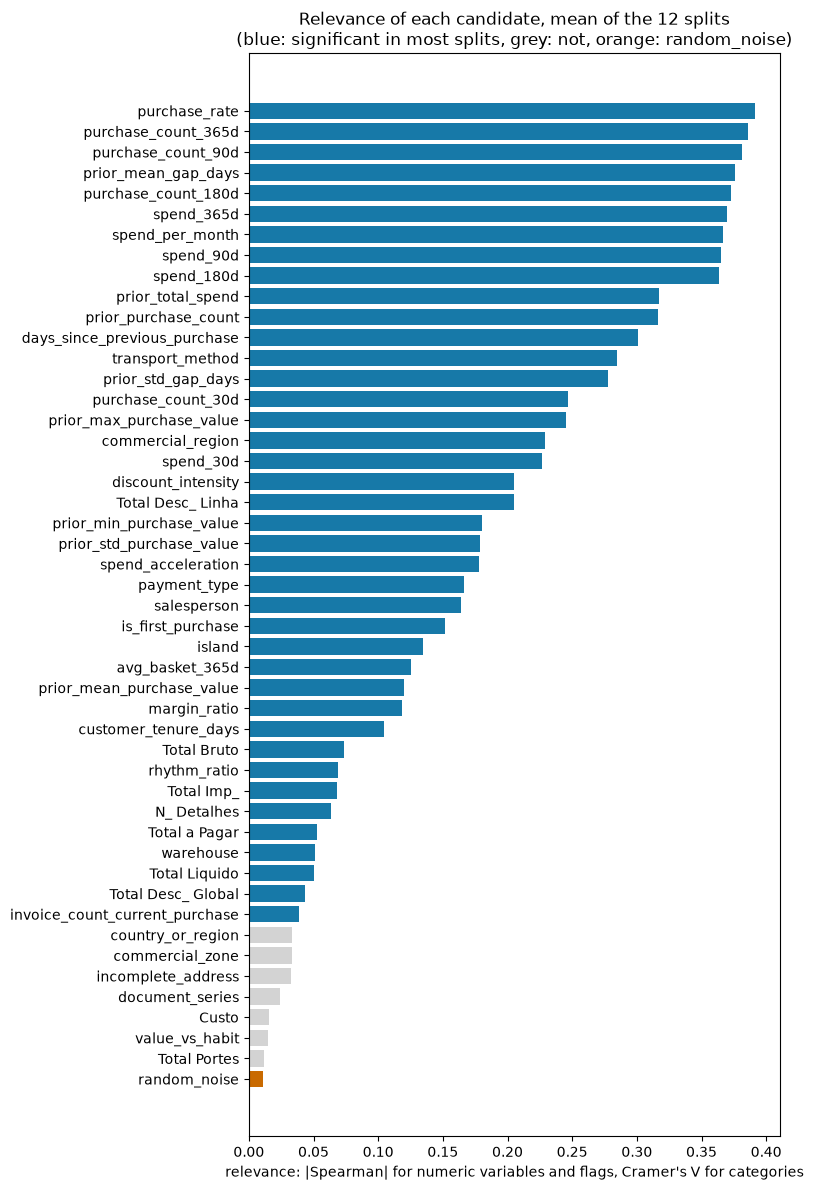

In [108]:
order = relevance.mean(axis=1).sort_values().index
colors = ["#C96A00" if v == "random_noise" else "#1779A8" if significant.loc[v].sum() > 6 else "lightgrey" for v in order]
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order, relevance.mean(axis=1)[order], color=colors)
ax.set_xlabel("relevance: |Spearman| for numeric variables and flags, Cramer's V for categories")
ax.set_title("Relevance of each candidate, mean of the 12 splits\n(blue: significant in most splits, grey: not, orange: random_noise)")
plt.tight_layout()
plt.show()

Frequency and Recency are at the top, with `purchase_rate`, `purchase_count_365d`, `purchase_count_90d`and `prior_mean_gap_days`) being significant in every fold. However their values are lower than in the EDA (0.391 aggainst 0.44 for `purchase_rate`) because they are a mean of the 12 train sets, where the first ones are smaller. These increase of folds size is reflected on `purchase_count_365d`tendency to go from 0.31 in fold 1 to 0.42 in fold 12.

`value_vs_habit`, `Custo` and `Total Portes` are not better than the noise, meaning they are not significant to the prevision model. 
At same time, `document_series` is significant in only 2 splits, and `country_or_region`, `commercial_zone` and `incomplete_address` in only 4.

#### **24.3. Redundancy**

As two variables can both be relevant and still say the same thing, we analyse redundancy through the Spearman correlation between the numeric variables. For the categories we use the Cramér's V between each pair. 

In [109]:
def redundancy(split):
    """Spearman and Cramer's V """
    rows = df_model.loc[split["train_idx"]]
    numeric = rows[numeric_vars].corr(method="spearman").abs()  # spearman
    levels = {col: levels_seen(split, col) for col in cat_vars}
    categorical = pd.DataFrame({a: {b: cramers_v(levels[a], levels[b])[0] for b in cat_vars} for a in cat_vars}) #cramer's v
    return numeric, categorical


redund = [redundancy(s) for s in splits]

# the pairs above 0.90 in the biggest train set (fold 12)
numeric_12, categorical_12 = redund[-1]
pairs = [(a, b, numeric_12.loc[a, b]) for i, a in enumerate(numeric_vars) for b in numeric_vars[i + 1:]
         if numeric_12.loc[a, b] > 0.90]
print(f"Pairs of numeric variables above 0.90: {len(pairs)}")
v_pairs = categorical_12.where(~np.eye(len(cat_vars), dtype=bool)).stack()
print(f"Highest Cramer's V between two different categories: {v_pairs.max():.2f} ({' and '.join(v_pairs.idxmax())})")
pd.DataFrame(pairs, columns=["variable", "same information as", "|Spearman|"]).sort_values("|Spearman|", ascending=False).round(3).set_index("variable")

Pairs of numeric variables above 0.90: 15
Highest Cramer's V between two different categories: 0.78 (country_or_region and commercial_region)


,same information as,|Spearman|
variable,,
Total a Pagar,Total Liquido,1.000
Total Bruto,Total Liquido,0.992
Total a Pagar,Total Bruto,0.991
spend_30d,spend_acceleration,0.967
purchase_count_30d,spend_30d,0.964
purchase_count_30d,spend_acceleration,0.939
prior_std_purchase_value,prior_max_purchase_value,0.935
prior_mean_gap_days,purchase_rate,0.934
prior_mean_purchase_value,avg_basket_365d,0.924


In the biggest train set 15 pairs are above 0.90. Most of them are the pairs of the EDA, plus `Total a Pagar` with `Total Imp_`, just above 0.90 here. 
The others involve the new features chosen, which are close to the columns they are built from (`spend_acceleration` with `spend_30d`, `purchase_rate` with `prior_mean_gap_days`, `spend_per_month` with `spend_365d`). 
Between the categories the highest V is 0.78, for `country_or_region` and `commercial_region`.
No pair of categories is above 0.90, so the redundancy rule only removes numeric variables.

#### **24.4. The Filter**

The filter puts relevance and redundancy together. A variable only stays if its test is significant (p < 0.05) and if it does not repeat (above 0.90) a variable that already stayed.

We compare this filter with three other versions: only the test, a stricter limit for the redundancy (0.70), and only the 10 most relevant variables (a fixed budget).

In [110]:
def filter_variables(a, numeric, categorical, threshold=0.90, alpha=0.05, budget=None):
    """
    Walks the variables from the most relevant to the least relevant.
    ---
    Returns: the variables that stay and the reason why each other variable leaves.
    
    """
    kept, reason = [], {}
    for col in a["relevance"].sort_values(ascending=False).index:
        if a.loc[col, "p-value"] >= alpha:
            reason[col] = "not significant"
            continue
        if budget is not None and len(kept) == budget:
            reason[col] = "outside the budget"
            continue
        if threshold is not None:
            matrix = numeric if col in numeric_vars else categorical
            repeats = [k for k in kept if k in matrix.index and matrix.loc[col, k] > threshold]
            if repeats:
                reason[col] = "repeats " + repeats[0]
                continue
        kept.append(col)
    return set(kept), reason


filters = {
    "test only": dict(threshold=None),
    "test + redundancy 0.90": dict(threshold=0.90),
    "test + redundancy 0.70": dict(threshold=0.70),
    "test + 10 most relevant": dict(threshold=None, budget=10),
}
for name, settings in filters.items():
    measure("filter: " + name, [filter_variables(assoc[i], *redund[i], **settings)[0] for i in range(len(splits))])
show(["filter: " + name for name in filters])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
filter: test only,0.8366,0.002,0.002,5/12,inside the noise,39.2,0/12,0.88
filter: test + redundancy 0.90,0.8377,0.0031,0.0021,7/12,inside the noise,27.2,0/12,0.71
filter: test + redundancy 0.70,0.8345,-0.0001,0.0022,5/12,inside the noise,18.6,0/12,0.56
filter: test + 10 most relevant,0.8304,-0.0042,0.0041,4/12,inside the noise,10.0,0/12,0.89


All four versions are inside the noise, and none of them keeps `random_noise`. The test alone removes about 9 variables. The redundancy limit of 0.90 removes about 12 more and has the best AP on average (+0.003). Going further costs AP: with a limit of 0.70, or with only the 10 most relevant variables, the instrument loses what it gained. The 10 most relevant are the lowest on average, because they are all frequency, recency and spend variables.

The filter method keeps about 27 variables. Its stability (0.71) is lower than the one of the test alone, because the variable that stays in a redundant group is the most relevant one of each split, and in some groups the most relevant one changes from split to split.

### **25. Wrapper Method: RFE**

The Wrapper method judges the variables through the RFE instrument, so it can see what a filter can not. It removes the column with the smallest coefficient, and repeats until only one column is left. The order in which the variables leave is a ranking, from the weakest to the strongest (a category leaves when its last column leaves).

RFE compares the size of the coefficients, so all the columns must be on the same scale. The instrument scales the numeric columns but leaves the 0/1 columns as they are. The controls are ranked together with the candidates, so lets first see where they fall.

In [111]:
def rfe_ranking(split, allowed=None):
    """
    RFE on the selection matrix, one column per step as in the classes. 
    
    Returns: the variables and the controls, from the strongest to the weakest. a variable leaves when its last
    column leaves. 
    """
    cols = np.isin(split["select_variable"], list(allowed)) if allowed is not None else np.ones(len(split["select_variable"]), bool)
    # liblinear: the same logistic regression, faster for the many fits of RFE
    rfe = RFE(LogisticRegression(solver="liblinear", max_iter=3000), n_features_to_select=1, step=1)
    rfe.fit(split["X_select"][:, cols], split["y_train"])
    best_rank = pd.Series(rfe.ranking_, index=split["select_variable"][cols]).groupby(level=0).min()
    return list(best_rank.sort_values().index)


rankings = [rfe_ranking(s) for s in splits]

#where the controls rank among the 48 candidates and 11 shuffled copies
controls = ["random_noise"] + [f"shuffled {v}" for v in shuffled_vars]
places = pd.DataFrame({i: {c: r.index(c) + 1 for c in controls} for i, r in enumerate(rankings)})
pd.DataFrame({"place (mean of 12 splits)": places.mean(axis=1).round(1),
              "best place": places.min(axis=1),
              "above random_noise in": ["–"] + [f"{(places.loc[c] < places.loc['random_noise']).sum()}/12" for c in controls[1:]]})

,place (mean of 12 splits),best place,above random_noise in
random_noise,45.7,36,–
shuffled payment_type,33.4,12,11/12
shuffled salesperson,24.7,13,11/12
shuffled commercial_zone,37.6,18,8/12
shuffled transport_method,28.0,17,11/12
shuffled warehouse,38.6,25,7/12
shuffled document_series,43.9,25,6/12
shuffled country_or_region,35.1,22,10/12
shuffled commercial_region,27.0,17,11/12
shuffled island,29.5,21,12/12


`random_noise` is near the end of the ranking (around place 46). But most shuffled categories are above it, beating the `random_noise` in almost every split. These copies have no information at all, so it could be random. The shuffled flags have one column, like `random_noise`, and they fall close to it.

So `random_noise` would be a control that is too easy for a category. RFE keeps a variable only when it is ranked above **its own** control, as stated before.

In [112]:
def above_control(ranking, candidates=feature_cols):
    """The candidates ranked above their own control."""
    return {v for v in candidates if v in ranking and ranking.index(v) < ranking.index(control[v])}


measure("RFE: above its control", [above_control(r) for r in rankings])
show(["RFE: above its control"])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
RFE: above its control,0.8349,0.0002,0.0008,7/12,inside the noise,35.3,0/12,0.69


RFE keeps about 35 variables and gives the same AP as all the candidates, without `random_noise`. It removes the variables that are clearly weak, but it keeps most of the redundant ones. The filter does the opposite and keeps only one variable of each group.

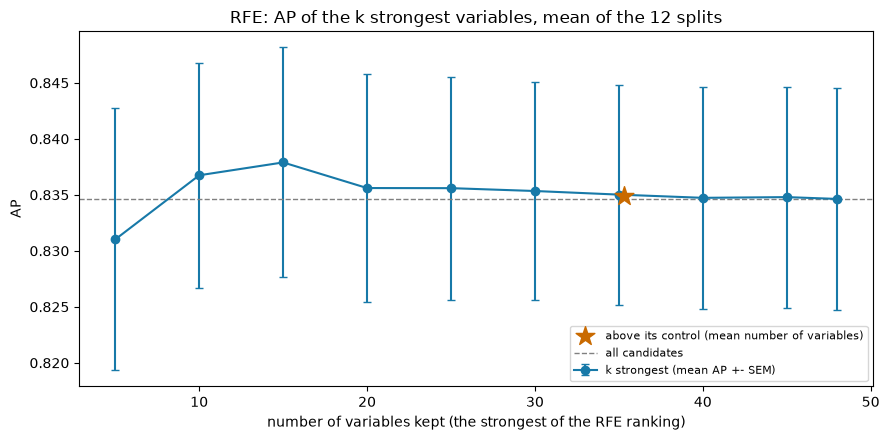

,5,10,15,20,25,30,35,40,45,48
AP,0.8310,0.8367,0.8379,0.8356,0.8356,0.8353,0.8350,0.8347,0.8348,0.8346
SEM,0.0117,0.0100,0.0103,0.0101,0.0099,0.0097,0.0098,0.0099,0.0099,0.0099


In [113]:
# the class way: the k strongest variables of each split, for several k (the controls are not counted)
real_rankings = [[v for v in r if v in feature_cols] for r in rankings]
widths_k = [5, 10, 15, 20, 25, 30, 35, 40, 45, len(feature_cols)]
curve = {k: selection_ap([set(r[:k]) for r in real_rankings]) for k in widths_k}
curve = pd.DataFrame({"AP": [c.mean() for c in curve.values()],
                      "SEM": [c.std(ddof=1) / np.sqrt(len(c)) for c in curve.values()]}, index=widths_k)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(curve.index, curve["AP"], yerr=curve["SEM"], marker="o", capsize=3, color="#1779A8", label="k strongest (mean AP +- SEM)")
ax.scatter(np.mean([len(s) for s in kept_by["RFE: above its control"]]), board["RFE: above its control"].mean(),
           marker="*", s=200, color="#C96A00", zorder=5, label="above its control (mean number of variables)")
ax.axhline(board["all candidates"].mean(), color="grey", linestyle="--", linewidth=1, label="all candidates")
ax.set(xlabel="number of variables kept (the strongest of the RFE ranking)", ylabel="AP",
       title="RFE: AP of the k strongest variables, mean of the 12 splits")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()
curve.round(4).T

This is the curve of the classes, with the k strongest variables of each split. With 5 variables the AP is lower, it is highest around 10 to 15 variables, and from 20 variables on it slowly goes down to the AP of all the candidates. All these differences are small (the error bars overlap). In the classes k is the point with the best AP, but this AP is too optimistic (the selection bias with validation blocks choosing k and measuring it). Our cut does not look at the AP (orange star). It keeps more variables than the best point of the curve, because RFE alone does not remove the redundant variables.

### **26. Embedded Methods**

The embedded methods select while the model is fitted. We use the two of the classes: the L1 penalty of the logistic regression and the random forest (tree model), which is more stable than a single tree.

#### **26.1. L1 Penalty (Lasso)**

The L1 penalty (lasso) pushes the coefficients of the weak columns to exactly 0, and C sets how strong it is. The smaller C, the stronger the penalty and the more columns at 0. The classes used C = 0.1. 

On the selection matrix we defined the path of the penalty from strong to weak.

In [114]:
C_grid = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]


def lasso_path(split, allowed=None):
    """For each C, from the strongest penalty to the weakest: the variables and controls with at least one column
    that the L1 penalty does not set to 0."""
    cols = np.isin(split["select_variable"], list(allowed)) if allowed is not None else np.ones(len(split["select_variable"]), bool)
    path = {}
    for C in C_grid:
        model = LogisticRegression(solver="liblinear", C=C, max_iter=3000, random_state=44, **LASSO)
        model.fit(split["X_select"][:, cols], split["y_train"])
        alive = pd.Series(np.abs(model.coef_[0]) > 1e-8, index=split["select_variable"][cols]).groupby(level=0).any()
        path[C] = set(alive[alive].index)
    return path


paths = [lasso_path(s) for s in splits]
pd.DataFrame({C: {"variables kept (mean)": round(np.mean([len(p[C] & set(feature_cols)) for p in paths]), 1),
                  "random_noise kept": f"{sum('random_noise' in p[C] for p in paths)}/12",
                  "shuffled copies kept (mean)": round(np.mean([len(p[C] - set(feature_cols)) for p in paths]), 1),
                  "AP": round(selection_ap([p[C] & set(feature_cols) for p in paths]).mean(), 4)}
              for C in C_grid}).T.rename_axis("C")

,variables kept (mean),random_noise kept,shuffled copies kept (mean),AP
C,,,,
0.001,0.1,0/12,0.0,0.5658
0.002,1.4,0/12,0.0,0.7154
0.005,4.5,0/12,0.0,0.8257
0.010,8.6,0/12,0.1,0.8341
0.020,14.7,0/12,1.9,0.8345
0.050,20.8,6/12,7.5,0.8336
0.100,27.5,10/12,9.7,0.8341
0.200,32.0,11/12,10.2,0.8352
0.500,35.8,11/12,10.8,0.8348



With a strong penalty almost nothing stays, and the AP falls. As C grows more variables enter, and from C = 0.01 on the AP is already close to the one of all the candidates. The controls also show that with a fixed C (0.1) `random_noise` is kept in 10 of 12 splits and almost all the shuffled copies are kept too. At this C the penalty is too weak to remove pure noise. The shuffled copies also enter earlier than `random_noise`, because of many columns and many chances.

So, as for RFE, each variable is compared with its own control: L1 keeps a variable when it enters the path (from the strongest penalty to the weakest) before its control.

We didn't tested C = 0.001 because the model would be almost empty and its AP would be close to the repeat rate.

In [115]:
def before_control(path, candidates=feature_cols):
    """The candidates that enter the path (from the strongest penalty to the weakest) before their own control."""
    first = {}
    for C in C_grid:
        for v in path[C]:
            first.setdefault(v, C)
    return {v for v in candidates if first.get(v, np.inf) < first.get(control[v], np.inf)}


measure("L1: before its control", [before_control(p) for p in paths])
measure("L1: C = 0.1 (class value)", [p[0.1] & set(feature_cols) for p in paths])
show(["L1: before its control", "L1: C = 0.1 (class value)"])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
L1: before its control,0.8352,0.0006,0.0016,7/12,inside the noise,19.3,0/12,0.60
L1: C = 0.1 (class value),0.8341,-0.0006,0.0008,6/12,inside the noise,27.5,10/12,0.76


L1 keeps about 19 variables, inside the noise of all the candidates (never `random_noise`). 

The C of the classes gives a similar AP with about 27 variables, but with the noise in 10 of 12 splits. 

L1 keeps only one variable from a group of correlated ones, because one column is enough to carry the information and the penalty makes every extra coefficient expensive. This is also why its sets are the least stable of the three methods (0.60).

#### **26.2. Random Forest Importance**

A random forest measures how much each column improves tree predictions. We add column importances to get each category’s importance. Numeric columns can appear more important by chance because they allow more possible splits. Therefore, we again compare each category or flag with its shuffled copy, and each numeric variable with random_noise.

The forest is a second embedded method, and the classes combine one method of each family, so we use it as a check from another kind of model, not in the combination.

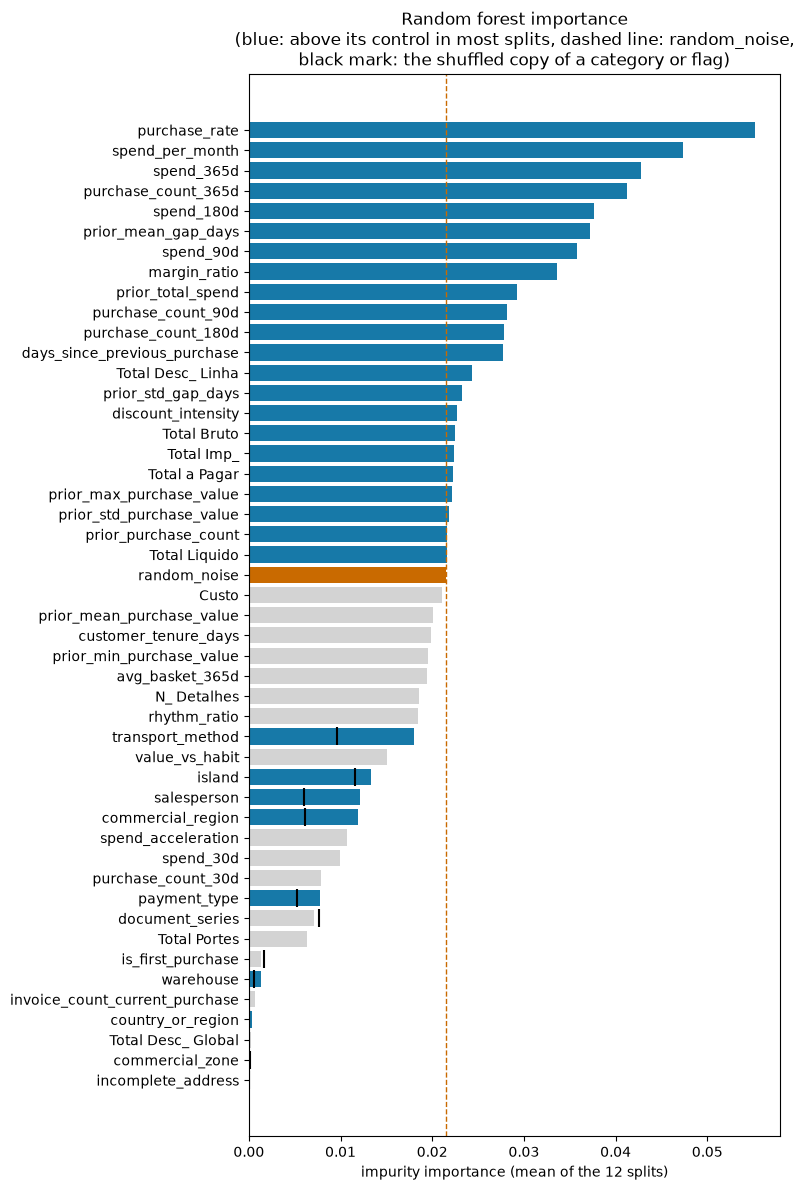

Categories and flags more important than random_noise in at least one split: []


,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
random forest: above its control,0.8335,-0.0012,0.0013,5/12,inside the noise,28.0,0/12,0.71


In [116]:
def forest_importance(split):
    """Impurity importance of a random forest.   
    """        
    forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=44, n_jobs=-1)
    forest.fit(split["X_select"], split["y_train"])
    return pd.Series(forest.feature_importances_, index=split["select_variable"]).groupby(level=0).sum()


importance = pd.DataFrame({i: forest_importance(s) for i, s in enumerate(splits)})
measure("random forest: above its control",
        [{v for v in feature_cols if importance.loc[v, i] > importance.loc[control[v], i]} for i in range(len(splits))])

mean_imp = importance.mean(axis=1)
order = mean_imp[feature_cols].sort_values().index
kept_rf = pd.Series({v: sum(v in s for s in kept_by["random forest: above its control"]) for v in feature_cols})
colors = ["#C96A00" if v == "random_noise" else "#1779A8" if kept_rf[v] > 6 else "lightgrey" for v in order]
fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order, mean_imp[order], color=colors)
ax.axvline(mean_imp["random_noise"], color="#C96A00", linestyle="--", linewidth=1)
shuffled = [v for v in order if v in shuffled_vars]
ax.scatter(mean_imp[[control[v] for v in shuffled]], shuffled, marker="|", s=150, color="black", zorder=5)
ax.set_xlabel("impurity importance (mean of the 12 splits)")
ax.set_title("Random forest importance\n(blue: above its control in most splits, dashed line: random_noise,\n"
             "black mark: the shuffled copy of a category or flag)")
plt.tight_layout()
plt.show()
above_noise = [v for v in shuffled_vars if (importance.loc[v] > importance.loc["random_noise"]).any()]
print(f"Categories and flags more important than random_noise in at least one split: {above_noise}")
show(["random forest: above its control"])

The forest kept about 28 variables, inside the noise of all the candidates. The printed line shows no category and no flag is more important than `random_noise` in any split. Therefore `random_noise` as the only control the forest would remove all of that categorical variables. Against their shuffled copies, most categories stay (blue bars).

The forest agrees with the other methods on the strongest variables, but it reads the data in another way. It keeps the spend variables that the filter and L1 remove as copies, and it drops some variables that the linear methods use (such as `N_ Detalhes` and `spend_acceleration`). 

### **27. Combining the Methods**

Each method reads the variables in its own way, and each one has its blind spots: the filter sees each variable alone, RFE keeps the redundant variables, and L1 keeps only one variable of each group. There are two ways to combine the three methods:

- **sequence**: Each method works with the variables kept by the previous one. A removed variable cannot return. Each variable’s control is carried forward for comparison.
- **vote**: Each method evaluates all candidates, and a variable stays if at least two methods select it.

Both use the same three methods.

In [117]:
members = {"filter": kept_by["filter: test + redundancy 0.90"],
           "RFE": kept_by["RFE: above its control"],
           "L1": kept_by["L1: before its control"]}

# vote: a variable stays in a split when at least 2 of the 3 methods keep it
measure("vote: 2 of 3 methods",
        [{v for v in feature_cols if sum(v in kept[i] for kept in members.values()) >= 2} for i in range(len(splits))])


def run_sequence(split, kept):
    """
    run_sequence: each method only sees what the previous one kept, and each variable brings its control.
    ---
    Returns: the variables that are still kept after each step.
    ---
    """
    after_rfe = above_control(rfe_ranking(split, allowed=kept | {control[v] for v in kept}), kept)
    after_l1 = before_control(lasso_path(split, allowed=after_rfe | {control[v] for v in after_rfe}), after_rfe)
    return {"filter": kept, "+ RFE": after_rfe, "+ L1": after_l1}


steps = [run_sequence(split, members["filter"][i]) for i, split in enumerate(splits)]
measure("sequence: filter -> RFE -> L1", [s["+ L1"] for s in steps])
show(["vote: 2 of 3 methods", "sequence: filter -> RFE -> L1"])

,AP,difference,SEM,better in,verdict,variables kept,random_noise kept,stability
all candidates,0.8346,0.0,0.0,0/12,reference,48.0,12/12,1.00
vote: 2 of 3 methods,0.835,0.0003,0.0009,5/12,inside the noise,27.9,0/12,0.66
sequence: filter -> RFE -> L1,0.8382,0.0035,0.0015,9/12,better,13.9,0/12,0.48


The two combinations are very different. The vote keeps about 28 variables and gives the same AP as all the candidates. The sequence keeps half (only 14) and its AP is higher (about +0.0035), which is right at the limit of the noise (2 SEM). 
The sequence selects around 10–15 variables. It removes redundant and insignificant variables first, then uses RFE and L1 to remove variables that do not outperform their controls.

The sequence has the higher mean difference across all candidates. It is also the simpler option, so we choose the **sequence**.

The disadvantage is lower stability (0.48 compared with 0.66 for the vote). Each step depends on the previous one, so a small change at the start can affect the final result. The next section shows which variables change.

### **28. The Final Feature Set**

The sequence was run 12 times, once per split, producing 12 lists of variables. The final set includes variables selected in more than 6 splits. Before applying this rule, we must ensure that shuffled copies are treated correctly. We then examine each variable and determine the final set.

#### **28.1. Copies That Take Turns**

When two variables are copies the filter and L1 keep only keeps one of them in each fold, changing this decision from fold to fold. This means that the original information is kept all across the folds. Since no individual copy reaches the majority, the final set may exclude relevant information that the sequence consistently preserved across different copies.

So the copies are counted together as a set linked by pairs above 0.90 in most of the train sets. A group stays when one of its copies is kept in more than 6 of the 12 folds, and only its **representative** enters in the final set. 

To choose the **representative**, we prioritised the copy selected in the most splits, then the most relevant one, and finally the one selected in the most recent folds.

In [118]:
# here are defined the pairs of numeric variables above 0.90 
above = sum((numeric > 0.90).astype(int) for numeric, _ in redund)
copy_of = {v: {w for w in numeric_vars if w != v and above.loc[v, w] > len(splits) / 2} for v in numeric_vars}

#here are the variables linked by group of copies
groups, seen = [], set()
for v in numeric_vars:
    if v in seen or not copy_of[v]:
        continue
    group, todo = set(), [v]
    while todo:
        w = todo.pop()
        if w not in group:
            group.add(w)
            todo += list(copy_of[w])
    seen |= group
    groups.append([c for c in feature_cols if c in group])


def last_split(v):
    """The most recent split where the sequence keeps v (-1 if never)."""
    return max([i for i, s in enumerate(steps) if v in s["+ L1"]], default=-1)


rows = []
for group in groups:
    # rules to choose representative
    best = max(group, key=lambda v: (sum(v in s["+ L1"] for s in steps), round(relevance.loc[v].mean(), 3), last_split(v)))
    rows.append({"group of copies": ", ".join(group),
                 "folds where one of them is kept": sum(any(v in s["+ L1"] for v in group) for s in steps),
                 "representative": best})
copy_groups = pd.DataFrame(rows).sort_values("folds where one of them is kept", ascending=False).set_index("group of copies")
copy_groups

,folds where one of them is kept,representative
group of copies,,
"Total Desc_ Linha, discount_intensity",12,discount_intensity
"purchase_count_90d, spend_90d",12,purchase_count_90d
"prior_mean_gap_days, purchase_rate",11,purchase_rate
"Total a Pagar, Total Bruto, Total Liquido, Total Imp_",11,Total Bruto
"prior_std_purchase_value, prior_max_purchase_value",10,prior_max_purchase_value
"prior_mean_purchase_value, avg_basket_365d",7,avg_basket_365d
"purchase_count_30d, spend_30d, spend_acceleration",4,purchase_count_30d
"prior_purchase_count, prior_total_spend, spend_180d, spend_365d, spend_per_month",2,spend_180d


The three rules still leave some problems. 
In the pairs `Total Desc_ Linha` and `discount_intensity`, and `avg_basket_365d` and `prior_mean_purchase_value`, each variable is selected in about 6 of the 12 folds, but at least one variable from each pair is selected in every fold. Grouping them ensures that information about discounts and average purchase value is retained. 
The other representatives remain unchanged, while variables selected in fewer than half of the splits are excluded.

#### **28.2. The Sequence, Variable by Variable**

In [119]:
def splits_kept(sets):
    """In how many of the 12 folds each candidate is kept."""
    return pd.Series({v: sum(v in kept for kept in sets) for v in feature_cols})


reasons = [filter_variables(assoc[i], *redund[i])[1] for i in range(len(splits))]


def why_out(i, v):
    """The step of the sequence where a variable leaves, in fold i."""
    if v not in steps[i]["filter"]:
        return reasons[i][v]                     # when is not significant or it repeats a stronger variable
    if v not in steps[i]["+ RFE"]:
        return "RFE: below its control"
    if v not in steps[i]["+ L1"]:
        return "L1: enters after its control"
    return ""


table = pd.DataFrame({"relevance": relevance.mean(axis=1).round(3),
                      "filter": splits_kept([s["filter"] for s in steps]),
                      "+ RFE": splits_kept([s["+ RFE"] for s in steps]),
                      "+ L1": splits_kept([s["+ L1"] for s in steps]),
                      "vote": splits_kept(kept_by["vote: 2 of 3 methods"]),
                      "random forest": splits_kept(kept_by["random forest: above its control"])})

group_of = {v: g for g, row in copy_groups.iterrows() for v in g.split(", ")}
table["group kept in"] = [copy_groups.loc[group_of[v], "folds where one of them is kept"] if v in group_of else "" for v in table.index] # the group stays when one of its copies is kept in more than 6 folds
majority = len(splits) / 2
table["decision"] = ["kept" if (v not in group_of and table.loc[v, "+ L1"] > majority)
                     or (v in group_of and copy_groups.loc[group_of[v], "folds where one of them is kept"] > majority
                         and copy_groups.loc[group_of[v], "representative"] == v) else "out" for v in table.index]
# for the variables that leave
table["main reason when it leaves a fold"] = [
    pd.Series([why_out(i, v) for i in range(len(splits)) if why_out(i, v)]).mode().iloc[0] if table.loc[v, "+ L1"] < len(splits) else ""
    for v in table.index]
table = table.sort_values(["decision", "+ L1", "relevance"], ascending=[True, False, False])
table

,relevance,filter,+ RFE,+ L1,vote,random forest,group kept in,decision,main reason when it leaves a fold
purchase_count_90d,0.381,12,12,12,12,11,12,kept,
prior_std_gap_days,0.278,12,12,12,12,8,,kept,
purchase_count_365d,0.386,11,11,11,12,12,,kept,repeats purchase_count_180d
transport_method,0.285,12,12,11,12,12,,kept,L1: enters after its control
margin_ratio,0.118,12,12,11,12,12,,kept,L1: enters after its control
salesperson,0.164,11,11,10,12,12,,kept,L1: enters after its control
purchase_rate,0.391,12,11,9,12,12,11,kept,L1: enters after its control
prior_max_purchase_value,0.245,11,9,9,12,7,10,kept,RFE: below its control
is_first_purchase,0.152,12,10,9,12,2,,kept,RFE: below its control
Total Bruto,0.073,10,10,8,10,9,11,kept,L1: enters after its control


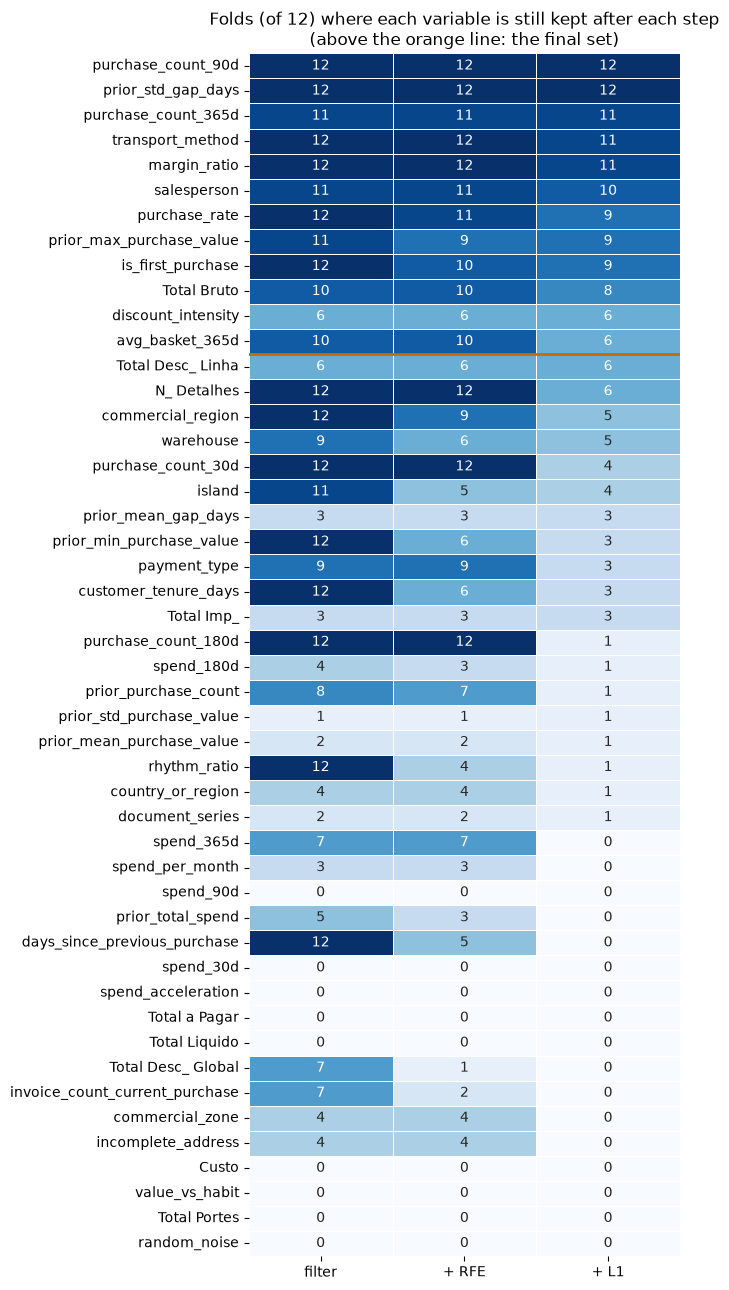

In [120]:
fig, ax = plt.subplots(figsize=(7, 13))
sns.heatmap(table[["filter", "+ RFE", "+ L1"]], annot=True, fmt="d", cmap="Blues", vmin=0, vmax=12,
            cbar=False, linewidths=0.5, ax=ax)
ax.axhline((table["decision"] == "kept").sum(), color="#C96A00", linewidth=2)
ax.set_title("Folds (of 12) where each variable is still kept after each step\n(above the orange line: the final set)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

The final set kept variables with the **strongest predictive information**, related to purchase frequency (`purchase_count_90d`, `purchase_count_365d`, `purchase_rate`), regularity (prior_std_gap_days), value (`prior_max_purchase_value`, `Total Bruto`, `avg_basket_365d`, `margin_ratio`), discounts (`discount_intensity`), first purchases (`is_first_purchase`), and two categories (`transport_method` and `salesperson`). The vote and the forest kept most of these variables too.

**Recency** is captured by `purchase_count_90d`, as no purchases in the last 90 days means the previous purchase was more than 90 days ago. Therefore, RFE and L1 remove `days_since_previous_purchase` because it adds no useful information beyond this indicator, although the vote keeps it in every fold.

About **redundant variables**, many variables are removed because they repeat information captured by stronger variables. Each group of similar variables is represented by one variable.

**Bordeline variables**, such as `N_Detalhes`, `commercial_region` and `warehouse`, are selected in about half of the folds but do not reach the majority threshold. They remain excluded since they are not copies of variables already selected.

The categories `transport_method` and `salesperson` outperform their shuffled copies in most of the folds, suggesting their signal is not random. The other categories, including `commercial_region`, `island`, `country_or_region`, `payment_type`, `warehouse`, `commercial_zone` and `document_series`, are excluded because they are not significant enough or do not consistently outperform their shuffled copies.

Finally, `random_noise` is removed at the first step in every fold because it has not significant information to the predictive model.

#### **28.3. The Final Set**

In [121]:
selected = [v for v in feature_cols if table.loc[v, "decision"] == "kept"]
selected_columns = {group: [c for c in cols if c in selected] for group, cols in final_columns.items()}
sequence_sets = [s["+ L1"] for s in steps]   # the selection of each split, for the comparisons of Part 4
for group, cols in selected_columns.items():
    print(f"{group} ({len(cols)} of {len(final_columns[group])}): {', '.join(cols)}")
print(f"\nSelected: {len(selected)} of {len(feature_cols)} variables | random_noise in the set: {'random_noise' in selected}")
width = {name: make_preprocessor(**columns, **final_recipe).fit_transform(df_model.loc[is_dev, feature_cols]).shape[1]
         for name, columns in [("final set", selected_columns), ("all candidates", final_columns)]}
print(f"Columns after Layer B, fitted on the development rows | final set: {width['final set']} | all candidates: {width['all candidates']}")

log_cols (7 of 32): Total Bruto, prior_max_purchase_value, prior_std_gap_days, purchase_count_90d, purchase_count_365d, purchase_rate, avg_basket_365d
plain_cols (2 of 5): margin_ratio, discount_intensity
cat_cols (2 of 9): salesperson, transport_method
flag_cols (1 of 2): is_first_purchase

Selected: 12 of 48 variables | random_noise in the set: False
Columns after Layer B, fitted on the development rows | final set: 56 | all candidates: 136


The final set has 12 of the 48 candidates: 9 numeric variables, the flag `is_first_purchase` and 2 categories, excluding identifiers. 
After Layer B they are 56 columns instead of 136. The final set is smaller than the selections in each fold (about 14 variables). Variables that change across folds often fail to reach the majority. Only the most consistently selected variables remain, with one representative for each group of copies.

In [122]:
# the same sequence fitted once on all the training rows
dev_idx = df_model.index[is_dev]
prep = make_preprocessor(**final_columns, **final_recipe)
X_dev = prep.fit_transform(df_model.loc[dev_idx, feature_cols])
names = encoded_names(prep)
X_select, select_variable = selection_matrix(X_dev, variable_of(names), rng)
dev_split = {"train_idx": dev_idx, "names": names, "variable": variable_of(names), "X_train": X_dev,
             "y_train": df_model.loc[dev_idx, target_col].to_numpy(), "X_select": X_select, "select_variable": select_variable}

dev_set = run_sequence(dev_split, filter_variables(association(dev_split), *redundancy(dev_split))[0])["+ L1"]
print(f"Sequence fitted on all the training rows: {len(dev_set)} variables | in common with the final set: {len(dev_set & set(selected))}")
print(f"Only in the final set: {sorted(set(selected) - dev_set)}")
print(f"Only in the sequence on all the training rows: {sorted(dev_set - set(selected))}")

Sequence fitted on all the training rows: 15 variables | in common with the final set: 9
Only in the final set: ['Total Bruto', 'avg_basket_365d', 'discount_intensity']
Only in the sequence on all the training rows: ['Total Desc_ Linha', 'Total Imp_', 'commercial_region', 'country_or_region', 'incomplete_address', 'warehouse']


The sequence fitted once on all the training data keeps 15 variables, including 9 of the 12 in the final set. Two differences are simply alternative variables representing the same information: `Total Desc_ Linha` instead of `discount_intensity`, and `Total Imp_` instead of `Total Bruto`.

The other extra variables are less consistent. `commercial_region` and `warehouse` are kept in about half of the folds, while `country_or_region` and `incomplete_address` are rarely selected. Their selection can change depending on the shuffled copies.

This shows why combining results across folds is useful. A single fit produces one list of variables, while the 12 folds reveal which variables are selected consistently. The final set therefore contains the variables that the sequence keeps most reliably across different folds.

#### **28.4. Summary of the Decisions**

| Section | Decision | Options tested | Choice | Why |
|---|---|---|---|---|
| 22 | How to select | – | every method inside each split; a variable stays only if it beats a control | no leakage; no cut is chosen with the AP |
| 22.1 | Controls | `random_noise` for every variable, a control of the same shape | `random_noise` for the numeric variables, a shuffled copy for the categories and flags | shuffled categories beat `random_noise` in almost every split (25) |
| 23 | Identifiers | `ID` and `customer_id` (as a number and as a category) | out | no gain; as a category `customer_id` loses AP |
| 24.1 | Constant columns | `VarianceThreshold(0)` | nothing to remove | no constant column |
| 24.4 | Filter | test, + redundancy 0.90 or 0.70, 10 most relevant | test + redundancy 0.90 | inside the noise; best on average; the limit of the EDA |
| 25 | RFE | k strongest (curve), above its control | above its control | the best k is too optimistic |
| 26.1 | L1 | C from 0.001 to 1, C = 0.1 of the classes | before its control | C = 0.1 keeps `random_noise` in 10 of 12 splits |
| 26.2 | Random forest | above its control | only a check | second embedded method, another kind of model |
| 27 | Combination | vote 2 of 3, sequence | sequence: filter → RFE → L1 | higher AP with half the variables; the plan of the EDA |
| 28.1 | Copies that take turns | each variable alone, groups of copies | groups of copies, one representative | the information of a group is kept even when its copies take turns |
| 28 | Final set | majority of the 12 splits, one fit on all the development rows | kept by the sequence in more than 6 of 12 splits | the core that the strategy keeps every time |

In conclusion, Part 3 reduces the number of variables from 48 to 12 while keeping the most useful predictive information. The selection process is robust, as every selected variable outperforms its corresponding noise control, or performs at its limit. Therefore, the main achievement is a simpler model without identifiers or noise, rather than a higher AP score.

## **Part 4. Modelling**

### **29. Modelling: The Plan**

Part 4 builds the model that predicts `repeat_purchase_90d` for test.csv and evaluates it with the F1 of class 1, the metric of the competition. We compare **two models** that look at the data in different ways:
* **Logistic regression**: the instrument of Parts 2 and 3. In the EDA the strongest relations were monotonic (section 7), and with `log1p` and the scaler a linear model can follow them. It is simple and we can read its coefficients.
* **Gradient boosting** (`HistGradientBoostingClassifier`): usually the strongest model for tables like ours. Its trees can find what a linear model can not, like breaks (the 90 days of 7.3) and interactions between variables.

The plan follows the rules of the previous parts:
* every option is fitted on the train rows of the same 12 temporal splits and scored on the validation blocks (12.2);
* the models and their settings are compared with the AP, as in Parts 2 and 3, because it does not depend on the threshold;
* then the threshold is chosen for the F1 (2.3), with the predictions of the 12 blocks;
* the holdout (2024 and 2025), never used until now, gives the honest check of the chosen model (34);
* the final model learns from all the rows of train.csv and predicts test.csv (35).

`split_probs` gives the probabilities of each validation block, and `board` puts the options side by side: the AP with `compare` (paired, with the SEM) and the best F1 that each option can reach.

In [123]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix


def split_probs(model, columns):
    """The probabilities of each validation block, from the pipeline fitted on the train rows of its split."""
    probs = []
    for train_idx, val_idx in folds:
        pipe = Pipeline([("prep", make_preprocessor(**columns, **final_recipe)), ("model", clone(model))])
        pipe.fit(df_model.loc[train_idx, feature_cols], df_model.loc[train_idx, target_col])
        probs.append(pipe.predict_proba(df_model.loc[val_idx, feature_cols])[:, 1])
    return probs

# True target of each validation block, and the thresholds we test for the F1.
y_blocks = [df_model.loc[val_idx, target_col].to_numpy() for _, val_idx in folds]
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)


def block_ap(probs):
    """AP of each validation block, as in Parts 2 and 3."""
    return np.array([average_precision_score(y, p) for y, p in zip(y_blocks, probs)])


def f1_curve(probs):
    """F1 of class 1 of the 12 blocks together, for each threshold."""
    y_all, p_all = np.concatenate(y_blocks), np.concatenate(probs)
    return pd.Series([f1_score(y_all, p_all >= t) for t in thresholds], index=thresholds)


def board(probs_by_name, reference):
    """compare (AP, paired) plus the best F1 that each option can reach with its own threshold."""
    table = compare({name: block_ap(p) for name, p in probs_by_name.items()}, reference)
    table["best F1"] = [round(f1_curve(p).max(), 4) for p in probs_by_name.values()]
    return table

#F1 of always predicting 1 (the minimum any model has to beat).
floor_f1 = f1_score(np.concatenate(y_blocks), np.ones(sum(len(y) for y in y_blocks)))
print(f"F1 of always predicting 1 in the 12 blocks: {floor_f1:.3f}")

F1 of always predicting 1 in the 12 blocks: 0.706


Always predicting 1 already gives an F1 of 0.706 on the 12 blocks (2.3). Any model has to beat this.

### **30. Two Models, Two Sets of Variables**

First the two models with their default settings, each with the final set of Part 3 (28.3) and with all the 48 candidates. Part 3 chose the variables with a linear model, so the trees should also try all the candidates (they may use variables that a linear model does not need).

In [124]:
models = {"logistic regression": LogisticRegression(max_iter=3000),
          "gradient boosting": HistGradientBoostingClassifier(random_state=44)} #Both models with their default settings.
variable_sets = {"final set": selected_columns, "all candidates": final_columns}

probs = {f"{m}, {s}": split_probs(model, columns) for m, model in models.items() for s, columns in variable_sets.items()}
board(probs, "logistic regression, final set")

,AP,difference,SEM,better in,verdict,best F1
"logistic regression, final set",0.8357,0.0,0.0,0/12,reference,0.7454
"logistic regression, all candidates",0.8346,-0.0011,0.0015,6/12,inside the noise,0.7369
"gradient boosting, final set",0.8198,-0.0159,0.005,2/12,worse,0.7282
"gradient boosting, all candidates",0.822,-0.0137,0.0035,2/12,worse,0.7325


With the default settings, gradient boosting is clearly **worse** than the logistic regression (about −0.015 of AP, with both sets of variables). Its default trees are large (31 leaves) and learn fast, so with a few thousand rows they end up learning noise. The logistic regression does slightly better with the 12 selected variables than with all 48, but the difference is inside the noise. Both models need tuning before a fair comparison.

### **31. Tuning**

We tune each model on the same 12 splits, using the AP. We also use small grids: Parts 2 and 3 showed that this data rewards simple models, and every extra setting tried on the same blocks makes the best result a bit more optimistic.

#### **31.1. Logistic Regression**

In [125]:
C_grid = [0.01, 0.03, 0.1, 0.3, 1, 3, np.inf] #C = infinity means no penalty at all. It shows if the penalty is worth it.
lr_probs = {C: split_probs(LogisticRegression(C=C, max_iter=3000), selected_columns) for C in C_grid}
lr_table = pd.DataFrame({"AP": [block_ap(p).mean() for p in lr_probs.values()],
                         "best F1": [f1_curve(p).max() for p in lr_probs.values()]}, index=pd.Index(C_grid, name="C")).round(4)
best_C = float(lr_table["AP"].idxmax())
print(f"Best C: {best_C}")
lr_table

Best C: 0.1


,AP,best F1
C,,
0.01,0.8376,0.7447
0.03,0.8383,0.7454
0.10,0.8388,0.7446
0.30,0.8385,0.7455
1.00,0.8357,0.7454
3.00,0.8321,0.7446
inf,0.8168,0.7435


The last row is the model with no penalty (C = infinity), to check whether the penalty helps. It is clearly the worst (AP of about 0.82 against about 0.84), so it does. Between the other values the AP barely changes, and the best is C = 0.1, a slightly stronger penalty than the default (C = 1).

#### **31.2. Gradient Boosting**

In [126]:
#5 settings, from the default (big trees that learn fast) to small trees that learn slowly.
gb_grid = [dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=20, max_iter=100),
           dict(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=40, max_iter=200),
           dict(learning_rate=0.03, max_leaf_nodes=7, min_samples_leaf=80, max_iter=300),
           dict(learning_rate=0.03, max_leaf_nodes=4, min_samples_leaf=80, max_iter=400),
           dict(learning_rate=0.05, max_leaf_nodes=4, min_samples_leaf=150, max_iter=200)] 
gb_probs, rows = {}, []
for i, settings in enumerate(gb_grid):
    model = HistGradientBoostingClassifier(**settings, l2_regularization=1.0, random_state=44)
    row = {"leaves": settings["max_leaf_nodes"], "learning rate": settings["learning_rate"],
           "min rows per leaf": settings["min_samples_leaf"], "trees": settings["max_iter"]}
    for s, columns in variable_sets.items():
        gb_probs[(i, s)] = split_probs(model, columns)
        row[f"AP, {s}"] = round(block_ap(gb_probs[(i, s)]).mean(), 4)
        row[f"best F1, {s}"] = round(f1_curve(gb_probs[(i, s)]).max(), 4)
    rows.append(row)
best_gb = max(gb_probs, key=lambda k: block_ap(gb_probs[k]).mean())
print(f"Best gradient boosting: settings {best_gb[0] + 1} with the {best_gb[1]}")
pd.DataFrame(rows, index=pd.Index(range(1, len(gb_grid) + 1), name="settings"))

Best gradient boosting: settings 4 with the all candidates


,leaves,learning rate,min rows per leaf,trees,"AP, final set","best F1, final set","AP, all candidates","best F1, all candidates"
settings,,,,,,,,
1,31,0.10,20,100,0.8202,0.7347,0.8198,0.7310
2,15,0.05,40,200,0.8282,0.7364,0.8268,0.7359
3,7,0.03,80,300,0.8358,0.7404,0.8347,0.7424
4,4,0.03,80,400,0.8380,0.7443,0.8401,0.7471
5,4,0.05,150,200,0.8367,0.7424,0.8377,0.7460


Smaller trees that learn slowly work much better. Going from the default (settings 1) to trees with 4 leaves, a learning rate of 0.03 and at least 80 rows per leaf (settings 4) raises the AP from about 0.82 to about 0.84. A tree with 4 leaves only combines two or three variables, so the best boosting ends up close to an additive model, like the logistic regression. This matches the EDA, where the strong signals are monotonic and add up. With small trees, boosting does slightly better with all 48 candidates, so we keep them.

### **32. Choosing the Model**

Now the best version of each model side by side plus the average of their probabilities. One model is linear on 12 variables and the other uses small trees on 48, so they make different mistakes, and their average can beat both.

In [127]:
finalists = {"logistic regression": lr_probs[best_C], "gradient boosting": gb_probs[best_gb]}
finalists["average of the two"] = [(a + b) / 2 for a, b in zip(lr_probs[best_C], gb_probs[best_gb])]
board(finalists, "logistic regression") #The best version of each model + the average of their probabilities.

,AP,difference,SEM,better in,verdict,best F1
logistic regression,0.8388,0.0,0.0,0/12,reference,0.7446
gradient boosting,0.8401,0.0013,0.0029,6/12,inside the noise,0.7471
average of the two,0.8434,0.0045,0.0011,11/12,better,0.7481


The two models are tied: boosting is a bit higher on average, but it only wins in half of the blocks. Their **average is clearly better** than the logistic regression (better in 11 of 12 blocks, outside the noise) and has the best F1.

Using two models adds some complexity, but here it pays off, because the average is the only option clearly ahead. The final model is the **average of the two**: the logistic regression with the 12 selected variables and gradient boosting with small trees on all 48 candidates.

In [128]:
# The final model: the two finalists (each with its own variables) and the average of their probabilities.
finalist_models = {"logistic regression": (LogisticRegression(C=best_C, max_iter=3000), selected_columns),
                   "gradient boosting": (HistGradientBoostingClassifier(**gb_grid[best_gb[0]], l2_regularization=1.0,
                                                                        random_state=44), variable_sets[best_gb[1]])}


def fit_average(rows):
    """Fits the pipeline of each finalist on the given rows."""
    pipes = []
    for model, columns in finalist_models.values():
        pipe = Pipeline([("prep", make_preprocessor(**columns, **final_recipe)), ("model", clone(model))])
        pipes.append(pipe.fit(df_model.loc[rows, feature_cols], df_model.loc[rows, target_col]))
    return pipes


def predict_average(pipes, frame):
    """The mean of the probabilities of the two pipelines."""
    return np.mean([pipe.predict_proba(frame[feature_cols])[:, 1] for pipe in pipes], axis=0)


final_probs = finalists["average of the two"]
for name, (model, columns) in finalist_models.items():
    print(f"{name}: {model} | {sum(len(c) for c in columns.values())} variables")

logistic regression: LogisticRegression(C=0.1, max_iter=3000) | 12 variables
gradient boosting: HistGradientBoostingClassifier(l2_regularization=1.0, learning_rate=0.03,
                               max_iter=400, max_leaf_nodes=4,
                               min_samples_leaf=80, random_state=44) | 48 variables


### **33. The Threshold**

The F1 needs a threshold: predict 1 when the probability is above it. The default is 0.5, but nothing says that 0.5 is the best for the F1 (2.3). We choose it with the predictions of the 12 validation blocks together, so each prediction comes from a model that did not see its purchase.

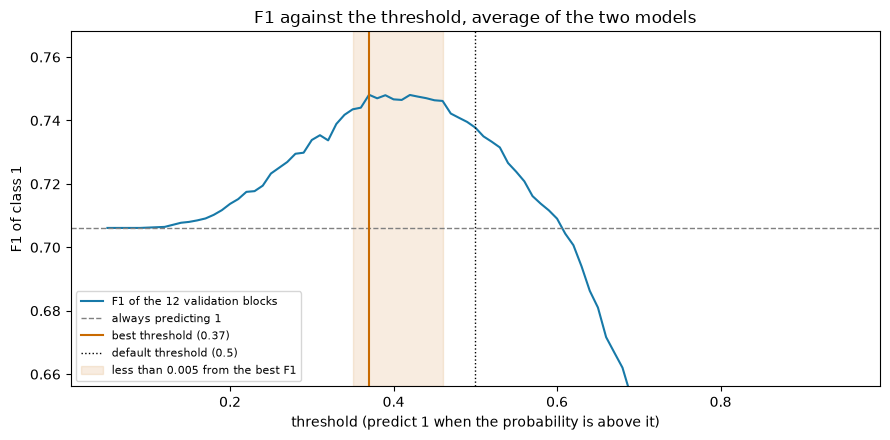

Threshold: 0.37 | F1: 0.748 (at 0.5: 0.738, always 1: 0.706)
Thresholds within 0.005 of the best F1: 0.35 to 0.46
Blocks where the model beats always predicting 1: 11/12


,0,1,2,3,4,5,6,7,8,9,10,11
F1 at the threshold,0.738,0.748,0.770,0.755,0.732,0.750,0.760,0.738,0.749,0.686,0.778,0.770
F1 at 0.5,0.768,0.715,0.798,0.745,0.719,0.737,0.759,0.743,0.754,0.679,0.718,0.736
F1 always 1,0.696,0.701,0.682,0.688,0.732,0.756,0.735,0.690,0.700,0.609,0.720,0.747


In [129]:
curve = f1_curve(final_probs)
threshold = curve.idxmax()
near_best = curve[curve >= curve.max() - 0.005].index #Thresholds where the F1 is less than 0.005 from the best (the shaded zone of the plot).

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve.index, curve.values, color="#1779A8", label="F1 of the 12 validation blocks")
ax.axhline(floor_f1, color="grey", linestyle="--", linewidth=1, label="always predicting 1")
ax.axvline(threshold, color="#C96A00", linewidth=1.5, label=f"best threshold ({threshold})")
ax.axvline(0.5, color="black", linestyle=":", linewidth=1, label="default threshold (0.5)")
ax.axvspan(near_best.min(), near_best.max(), color="#C96A00", alpha=0.12, label="less than 0.005 from the best F1")
ax.set(xlabel="threshold (predict 1 when the probability is above it)", ylabel="F1 of class 1",
       title="F1 against the threshold, average of the two models")
ax.set_ylim(floor_f1 - 0.05, curve.max() + 0.02)
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

#F1 of each block: at our threshold, at 0.5 and when always predicting 1.
per_block = pd.DataFrame({"F1 at the threshold": [f1_score(y, p >= threshold) for y, p in zip(y_blocks, final_probs)],
                          "F1 at 0.5": [f1_score(y, p >= 0.5) for y, p in zip(y_blocks, final_probs)],
                          "F1 always 1": [f1_score(y, np.ones(len(y))) for y in y_blocks]})
print(f"Threshold: {threshold} | F1: {curve.max():.3f} (at 0.5: {curve[0.5]:.3f}, always 1: {floor_f1:.3f})")
print(f"Thresholds within 0.005 of the best F1: {near_best.min()} to {near_best.max()}")
print(f"Blocks where the model beats always predicting 1: {(per_block['F1 at the threshold'] > per_block['F1 always 1']).sum()}/12")
per_block.round(3).T

The best threshold is clearly below 0.5. For the F1 of class 1, missing a repeat purchase costs more than predicting one that does not happen, so it pays to predict 1 a bit more often. The curve is flat around the best point (between about 0.35 and 0.46 the F1 changes by less than 0.005), so the exact value matters little and can move slightly from one computer to another, but 0.5 is already outside this zone.

With this threshold the model reaches an F1 of about 0.75 against 0.706 for always predicting 1, and it beats it in 11 of the 12 blocks. The only exception is a block where always predicting 1 is already very strong (0.756).

### **34. Holdout Check**

The holdout (2024 and 2025, section 12.1) was not used for any decision in Parts 2 to 4, so it gives an honest test of the whole pipeline, on purchases closer to the test period. Both models are trained on 2015 to 2023 only, with the threshold of section 33.

In [130]:
dev_rows, holdout_rows = df_model.index[is_dev], df_model.index[~is_dev]
pipes = fit_average(dev_rows) #Both models learn only from the development rows (2015-2023)
p_holdout = predict_average(pipes, df_model.loc[holdout_rows])
y_holdout = df_model.loc[holdout_rows, target_col].to_numpy()

print(f"Holdout: {len(holdout_rows)} purchases (2024-2025) | repeat rate: {y_holdout.mean():.3f}")
print(f"AP: {average_precision_score(y_holdout, p_holdout):.3f}")
print(f"F1 at the threshold ({threshold}): {f1_score(y_holdout, p_holdout >= threshold):.3f}"
      f" | at 0.5: {f1_score(y_holdout, p_holdout >= 0.5):.3f} | always 1: {f1_score(y_holdout, np.ones(len(y_holdout))):.3f}")
print(f"Purchases predicted as 1: {(p_holdout >= threshold).mean():.0%}")
pd.DataFrame(confusion_matrix(y_holdout, p_holdout >= threshold),
             index=["no repeat (0)", "repeat (1)"], columns=["predicted 0", "predicted 1"])

Holdout: 835 purchases (2024-2025) | repeat rate: 0.605
AP: 0.864
F1 at the threshold (0.37): 0.792 | at 0.5: 0.778 | always 1: 0.754
Purchases predicted as 1: 77%


,predicted 0,predicted 1
no repeat (0),140,190
repeat (1),49,456


On the holdout the model reaches an **F1 of about 0.79** (AP 0.864), against 0.754 for always predicting 1. The gain over this floor (about +0.04) is similar to the one on the 12 blocks, so our choices were not too optimistic. The chosen threshold also beats 0.5 here.

The values are higher than in the 12 blocks because the repeat rate of the holdout is higher (0.605): when more purchases come back, the F1 of class 1 is easier, also for the floor. The confusion matrix shows the cost of the threshold: the model finds about 90% of the repeat purchases, and in exchange more than half of the purchases that do not come back are predicted as 1.

### **35. Final Model and Submission**

The final model is the same average of the two models, now fitted on all the 6,469 purchases of train.csv, including the holdout. The most recent purchases are the closest to test.csv, so the model should learn from them too. Then test.csv follows the path of 21.4. It goes through `prepare_data` (Layer A, row by row), and the fitted pipelines only transform it, they never learn from it. The threshold is the one of section 33.

In [131]:
# the final model learns from all the 6,469 purchases of train.csv: development rows and holdout
final_pipes = fit_average(df_model.index)

# test.csv goes through the same Layer A, and the pipeline only transforms it (never fit)
test_path = os.path.join("..", "data", "raw", "test.csv")
df_test = pd.read_csv(test_path, index_col="ID", sep=",")
test_model = prepare_data(df_test, df_clientes)
p_test = predict_average(final_pipes, test_model)

submission = pd.DataFrame({"ID": test_model.index, target_col: (p_test >= threshold).astype(int)})
sample = pd.read_csv(os.path.join("..", "data", "raw", "sample_submission.csv"))
print(f"Test purchases: {len(submission):,} | same IDs and order as sample_submission.csv: {submission['ID'].equals(sample['ID'])}")
print(f"Purchases predicted as 1: {submission[target_col].mean():.0%} (holdout: {(p_holdout >= threshold).mean():.0%})")

os.makedirs(os.path.join("..", "data", "processed"), exist_ok=True)
submission.to_csv(os.path.join("..", "data", "processed", "submission_group44.csv"), index=False)
submission.head()

Test purchases: 986 | same IDs and order as sample_submission.csv: True
Purchases predicted as 1: 79% (holdout: 77%)


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


test.csv has 986 purchases, with the same IDs and order as `sample_submission.csv`. The share predicted as 1 is close to the one of the holdout, so test.csv looks similar to the latest purchases of train.csv. The file is saved as `submission_group44.csv` in `data/processed`.

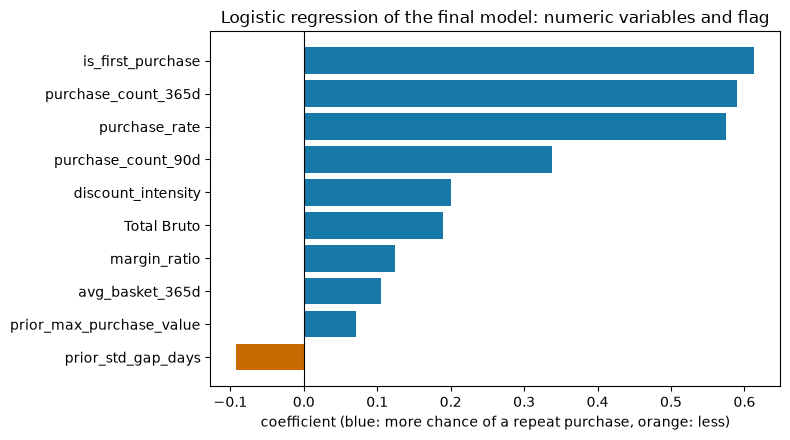

In [132]:
# Coefficients of the logistic regression of the final model (the columns are scaled, so they can be compared).
lr_pipe = final_pipes[0]
prep = lr_pipe.named_steps["prep"]
names = []
for name, steps, cols in prep.transformers_:
    if name == "cat":
        names += list(steps.named_steps["encode"].get_feature_names_out(cols))
    elif name != "remainder":
        names += list(cols)
coefs = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names)
numeric = coefs[[n for n in names if n in selected]].sort_values() #We only plot the numeric variables and the flag (the category levels would be too many bars).

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(numeric.index, numeric.values, color=np.where(numeric > 0, "#1779A8", "#C96A00"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="coefficient (blue: more chance of a repeat purchase, orange: less)",
       title="Logistic regression of the final model: numeric variables and flag")
plt.tight_layout()
plt.show()

The coefficients show what the logistic regression learned (the numeric ones can be compared because the columns are scaled). Frequency is the strongest signal, with `purchase_count_365d`, `purchase_rate` and `purchase_count_90d` at the top. Clients who buy often, and recently, are more likely to come back. Discounts, invoice value and margin add a little. `prior_std_gap_days` is the only negative one, so clients with irregular gaps between purchases come back less.

`is_first_purchase` has a large positive coefficient, which looks odd after 7.3 (first purchases come back less). But the flag never acts alone. In a first purchase all the counts are 0, which pushes the probability down a lot, and the flag only offsets part of that. Overall, first purchases still get a low probability.

### **36. Summary of Part 4**

| Section | Decision | Options tested | Choice | Why |
|---|---|---|---|---|
| 29 | Models | – | Logistic regression and gradient boosting | A linear model that follows the monotonic relations of the EDA, and a tree model that finds breaks and interactions |
| 30 | Variables | Final set of Part 3, all the 48 candidates | Final set for the logistic regression, all the candidates for gradient boosting | Best AP of each model |
| 31.1 | Penalty of the logistic regression | C from 0.01 to 3, and no penalty (C = infinity) | C = 0.1 | Best AP; without penalty the AP is clearly lower |
| 31.2 | Settings of gradient boosting | 5 settings, from the default to small trees | 4 leaves, learning rate 0.03, 80 rows per leaf, 400 trees | The default overfits; small trees are clearly better |
| 32 | Final model | Logistic regression, gradient boosting, average of the two | Average of the two | The only option outside the noise (better in 11 of 12 blocks) |
| 33 | Threshold | 0.05 to 0.95 | Best F1 of the 12 blocks (below 0.5) | The curve is flat around it; 0.5 is outside the best zone |
| 34 | Holdout check | – | F1 about 0.79 against 0.754 for always 1 | The gain is close to the one of the 12 blocks |
| 35 | Submission | – | Fitted on all train.csv, `submission_group44.csv` | The most recent purchases are the closest to test.csv |